# Query Matrix and Acquisition Progress: Seven Visualizations

This notebook contains the complete code for seven high-resolution, English-language figures. The supplied renders use Matplotlib and NumPy, an opaque white background, Arial with a DejaVu Sans fallback, and 450 dpi PNG export.

## Run instructions

1. Install `matplotlib` and `numpy` if needed.
2. Run the setup and embedded-data cells, then any figure cell independently.
3. Edit `OUTPUT_DIR` to select another destination. PNG files are the deliverables; editable PDF and preview files in `support/qa` support visual verification.

The plotting inputs are embedded below. No database, corpus body, source website or collection worker is opened. Source signatures accompany the inputs. The supplied figure renders received full panel-alignment and PDF collision checks. If the optional alignment-audit module is absent on another machine, the notebook records its more limited portable plot-area check rather than claiming the full audit passed.

## Counting rules

- 988 cluster-term memberships comprise 350 base terms, 343 direct children and 295 sub-parent-grouped children. There are 985 distinct literal terms.
- The fear/anxiety parent has 15 named sub-parents; irritability/anger has two. Sub-parent sizes use canonical child ownership, not overlapping discovery lists.
- Search progress uses all 942 round31 registrations. Five contiguous artifact-defined blocks contain 20, 94, 123, 345 and 360 registrations. Registration order is not elapsed-time throughput.
- Query families describe discovery intent, not sentiment labels. All percentages are recomputed from explicit predicates and denominators.
- Saved year hints cover 218 registrations; 724 have no saved year-hint field. Publication-year additions are a separate final-report population of 25,000 records.


In [1]:
import os
import json
import math
import re
import textwrap
import tempfile
from pathlib import Path
from collections import Counter

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir())/'query_matrix_matplotlib'))
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.colors as mcolors
from matplotlib.font_manager import FontProperties
from matplotlib.ticker import PercentFormatter, MaxNLocator, FuncFormatter
import numpy as np

try:
    from audit_panel_alignment import require_matplotlib_panel_alignment
except ImportError:
    require_matplotlib_panel_alignment = None

plt.rcParams.update({'font.family':'sans-serif','font.sans-serif':['Arial','DejaVu Sans'],
 'font.size':11,'axes.titlesize':12,'axes.labelsize':11,'xtick.labelsize':10,'ytick.labelsize':11,
 'axes.spines.top':False,'axes.spines.right':False,'axes.linewidth':0.65,
 'axes.edgecolor':'#B9C6D2','axes.labelcolor':'#344657','xtick.color':'#536779','ytick.color':'#344657',
 'text.color':'#193047','legend.frameon':False,'legend.fontsize':10,'figure.facecolor':'white',
 'axes.facecolor':'white','savefig.facecolor':'white','figure.dpi':300,'pdf.fonttype':42,'svg.fonttype':'none'})

C={'navy':'#24465F','steel':'#779EB9','amber':'#D5A064','teal':'#4F8A83','plum':'#78658F',
 'slate':'#9BAAB6','ink':'#193047','muted':'#627485','grid':'#E1E7ED','pale':'#F3F6F9',
 'base':'#24465F','direct':'#779EB9','grouped':'#D5A064'}
FAMILIES=['somatic_daily_impact','psychological_cultural_response','ecological_grief_memory','broad_forum_exploration','irony_metaphor']
FCOL=dict(zip(FAMILIES,[C['navy'],C['plum'],C['teal'],C['slate'],C['amber']]))
FLAB=dict(zip(FAMILIES,['Somatic / daily life','Psychological / cultural','Ecology / memory','Broad exploration','Irony / metaphor']))
SUBLABEL={
 'summer_anticipatory_fear':'Summer\nanticipation','heatwave_panic':'Heatwave\npanic','future_climate_dread':'Future\nclimate dread',
 'ecological_loss_grief':'Ecological\nloss & grief','heat_aversion':'Heat\naversion','heat_entrapment_exhaustion':'Entrapment &\nexhaustion',
 'heat_climate_anger':'Heat / climate\nanger','unequal_heat_distress':'Unequal-heat\ndistress','learned_shared_fear':'Learned &\nshared fear',
 'fire_season_memory':'Fire-season\nmemory','fear_ordinary_variants':'Fear\nvocabulary','fear_indirect_idioms':'Indirect\nfear idioms',
 'fear_learned_shared_expression':'Shared-fear\nexpressions','fear_ordinary_cultural_variants':'Cultural\nfear variants',
 'fear_ordinary_indirect_idioms':'Everyday\nfear idioms','fear_colloquial_interjections_and_embodied_idioms':'Colloquial &\nembodied fear',
 'distress_colloquial_and_cultural_metaphors':'Distress\nmetaphors','anger_colloquial_and_heat_metaphors':'Anger\nmetaphors',
 'continuum_fear_anxiety':'Fear / anxiety\ncontinuum','continuum_mild_discomfort':'Mild\ndiscomfort',
 'continuum_embodied_feedback':'Embodied\nfeedback','continuum_ecological_metaphor':'Ecological\nmetaphors',
 'continuum_policy_cultural_backlash':'Policy / cultural\nbacklash','continuum_cultural_learning':'Cultural\nlearning'}

def header(fig,num,title,subtitle):
    fig.text(.045,.963,f'{num:02d}  /  QUERY MATRIX',fontsize=9,fontweight='bold',color=C['muted'],va='top')
    fig.text(.045,.919,title,fontsize=23,fontweight='bold',color=C['ink'],va='top')
    fig.text(.045,.865,subtitle,fontsize=11,color=C['muted'],va='top')

def footer(fig,text):
    fig.text(.045,.027,text,fontsize=9,color=C['muted'],va='bottom')

def panel_title(ax,letter,title):
    ax.annotate(letter,xy=(0,1),xycoords='axes fraction',xytext=(-19,12),textcoords='offset points',fontsize=13,fontweight='bold',annotation_clip=False)
    ax.annotate(title,xy=(0,1),xycoords='axes fraction',xytext=(0,12),textcoords='offset points',fontsize=12,fontweight='bold',annotation_clip=False)

def grid(ax,axis='y'):
    ax.grid(axis=axis,color=C['grid'],linewidth=.65,zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(length=0,pad=8)

def key(fig,x,y,color,label,fs=10):
    fig.add_artist(patches.Rectangle((x,y-.006),.012,.012,transform=fig.transFigure,facecolor=color,edgecolor='none'))
    fig.text(x+.018,y,label,fontsize=fs,va='center')

def save_figure(fig,stem,out_dir,qa_dir):
    out_dir=Path(out_dir);qa_dir=Path(qa_dir);out_dir.mkdir(parents=True,exist_ok=True);qa_dir.mkdir(parents=True,exist_ok=True)
    fig.canvas.draw()
    if require_matplotlib_panel_alignment is not None:
        require_matplotlib_panel_alignment(fig,json_out=qa_dir/f'{stem}.alignment.json',tolerance_pt=1.5,gutter_tolerance_pt=1.5,strict=True)
    else:
        boxes=[ax.get_position().bounds for ax in fig.axes if ax.get_visible()]
        if len(boxes)>1:
            for i,a in enumerate(boxes):
                for b in boxes[i+1:]:
                    assert not (max(a[0],b[0])<min(a[0]+a[2],b[0]+b[2])-1e-6 and max(a[1],b[1])<min(a[1]+a[3],b[1]+b[3])-1e-6),'Plot areas overlap'
        (qa_dir/f'{stem}.alignment.json').write_text(json.dumps({'status':'portable plot-area overlap check only; full alignment auditor not installed','boxes':boxes}))
    fig.savefig(out_dir/f'{stem}.png',dpi=450)
    fig.savefig(qa_dir/f'{stem}.pdf')
    fig.savefig(qa_dir/f'{stem}.svg')
    fig.savefig(qa_dir/f'{stem}.preview.png',dpi=300)
    assert all(not re.search('[\u3400-\u4dbf\u4e00-\u9fff\uf900-\ufaff]',t.get_text()) for t in fig.findobj(matplotlib.text.Text))
    return out_dir/f'{stem}.png'

def treemap(values,x,y,w,h):
    values=[float(v) for v in values];assert all(v>0 for v in values)
    # Weighted recursive bisection preserves areas while avoiding thin final strips.
    def split(vals,xx,yy,ww,hh):
        if len(vals)==1:return [(xx,yy,ww,hh)]
        total=sum(vals);running=0;best=None
        for i in range(1,len(vals)):
            running+=vals[i-1];candidate=(abs(running-total/2),i,running/total)
            if best is None or candidate[0]<best[0]:best=candidate
        _,k,ratio=best
        if ww>=hh:
            cut=ww*ratio
            return split(vals[:k],xx,yy,cut,hh)+split(vals[k:],xx+cut,yy,ww-cut,hh)
        cut=hh*ratio
        return split(vals[:k],xx,yy,ww,cut)+split(vals[k:],xx,yy+cut,ww,hh-cut)
    return split(values,x,y,w,h)

def fit_rect_text(ax,rect,label,color=C['ink'],maxsize=11,minsize=8.4,bold=False):
    x,y,w,h=rect;renderer=ax.figure.canvas.get_renderer();p0=ax.transData.transform((x,y));p1=ax.transData.transform((x+w,y+h))
    width=abs(p1[0]-p0[0])-6;height=abs(p1[1]-p0[1])-6
    for size in np.arange(maxsize,minsize-.01,-.25):
        fp=FontProperties(family='Arial',size=float(size),weight='bold' if bold else 'normal')
        for paragraphs in [label.split('\n'),[' '.join(label.split())]]:
            lines=[]
            for original in paragraphs:
                current=''
                for word in original.split():
                    candidate=(current+' '+word).strip()
                    if current and renderer.get_text_width_height_descent(candidate,fp,False)[0]>width:
                        lines.append(current);current=word
                    else:current=candidate
                lines.append(current)
            if max(renderer.get_text_width_height_descent(line,fp,False)[0] for line in lines)<=width and len(lines)*size*ax.figure.dpi/72*1.12<=height:
                return ax.text(x+w/2,y+h/2,'\n'.join(lines),ha='center',va='center',fontsize=float(size),color=color,fontweight='bold' if bold else 'normal',linespacing=1.06)
    raise ValueError(f'Text does not fit its rectangle: {label!r}; size={w:.2f}x{h:.2f}')

def phase_statistics(data):
    bounds=data['phase_bounds'];counts=np.zeros((5,len(FAMILIES)),dtype=int);metrics=np.zeros((4,5),dtype=float)
    genre=re.compile(r'\b(?:blogs?|diary|diaries|essay|essays|memoir|forum|forums|article|articles|publication|print)\b',re.I)
    cities=re.compile(r'\b(?:'+ '|'.join(map(re.escape,data['cities']))+r')\b',re.I)
    geo={s.lower() for s in data['geo_terms']}
    for i in range(5):
        rows=data['queries'][bounds[i]:bounds[i+1]]
        for q in rows:
            counts[i,FAMILIES.index(q['family'])]+=1
            metrics[0,i]+=bool(q['weight'] is not None and q['child_ids'])
            metrics[1,i]+=bool(genre.search(q['text']))
            alternatives=[part.strip().strip('\"\'').lower() for part in re.findall(r'\(([^()]*)\)',q['text']) for part in part.split(' OR ')]
            metrics[2,i]+=sum(part in geo for part in alternatives)>=2
            metrics[3,i]+=bool(cities.search(q['text']))
        metrics[:,i]=metrics[:,i]/len(rows)*100
    assert counts.sum()==942
    return counts,metrics

OUTPUT_DIR = Path.cwd()
QA_DIR = OUTPUT_DIR / 'support' / 'qa'


## Frozen plotting inputs

The complete input objects are embedded for reproducibility. Original corpus data are not included.

In [2]:
DATA = {'parents': [{'id': 'warming_seasons',
              'name': 'Warming & changing seasons',
              'short': 'Warming & seasons',
              'base': 31,
              'direct': 19,
              'grouped': 0,
              'groups': 0,
              'family': 'broad_forum_exploration',
              'weight': 1.0,
              'base_terms': ['rising temperature',
                             'rising temperatures',
                             'warming',
                             'global warming',
                             'climate change',
                             'hotter summers',
                             'hotter summer',
                             'warmer summers',
                             'warmer summer',
                             'warmer winters',
                             'warm winter',
                             'getting hotter',
                             'getting warmer',
                             'hotter than',
                             'warmer than',
                             'unseasonably warm',
                             'unseasonal warmth',
                             'changing seasons',
                             'climate crisis',
                             'climate emergency',
                             'hotter and hotter',
                             'warmer and warmer',
                             'summers are longer',
                             'longer summers',
                             'earlier spring',
                             'late autumn',
                             'warming planet',
                             'warming world',
                             'climate breakdown',
                             'climate disruption',
                             'climate grief'],
              'direct_terms': ['climate',
                               'climatic',
                               'climatechange',
                               'globalwarming',
                               'warming climate',
                               'warmest',
                               'hotter',
                               'hottest',
                               'summer',
                               'summers',
                               'heat',
                               'hot',
                               'warm',
                               'wet season',
                               'dry season',
                               'build up',
                               'build-up',
                               'midsummer',
                               'unseasonal'],
              'subparents': [],
              'total': 50},
             {'id': 'acute_heat',
              'name': 'Acute heat & temperature extremes',
              'short': 'Acute heat',
              'base': 55,
              'direct': 21,
              'grouped': 0,
              'groups': 0,
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'base_terms': ['heatwave',
                             'heatwaves',
                             'heat wave',
                             'heat waves',
                             'extreme heat',
                             'hot weather',
                             'hot day',
                             'hot days',
                             'hot night',
                             'hot nights',
                             'hot spell',
                             'heat dome',
                             'scorcher',
                             'scorching',
                             'sweltering',
                             'stinking hot',
                             'bloody hot',
                             'so hot',
                             'too hot',
                             'boiling hot',
                             'baking hot',
                             'oppressive heat',
                             'summer heat',
                             'summer sun',
                             'unbearably hot',
                             'unbearable heat',
                             'stifling heat',
                             'heat stress',
                             'heat stroke',
                             'heatstroke',
                             'record temperatures',
                             'record temperature',
                             'record heat',
                             'heatwave warning',
                             'heat wave warning',
                             'heat alert',
                             'severe heatwave',
                             'extreme heatwave',
                             'hot as hell',
                             "I'm melting",
                             'I am melting',
                             "we're melting",
                             'muggy',
                             'humid',
                             'humidity',
                             'sticky heat',
                             'sticky night',
                             'sticky nights',
                             'stinking bloody hot',
                             'roasting hot',
                             'cooking in the heat',
                             'forty degrees',
                             '40 degree heat',
                             'a scorcher',
                             'hotter than hell'],
              'direct_terms': ['blistering',
                               'roasting',
                               'boiling',
                               'melting',
                               'stifling',
                               'scorching heat',
                               'baking',
                               'sticky weather',
                               'parched',
                               'desiccated',
                               'swelter',
                               'sweltered',
                               'searing',
                               'scorched',
                               'sun-drenched',
                               'sizzling',
                               'dry heat',
                               'torrid',
                               'sultry',
                               'heat haze',
                               'prolonged heat'],
              'subparents': [],
              'total': 76},
             {'id': 'body_daily_life',
              'name': 'Somatic & daily-life experience',
              'short': 'Somatic & daily life',
              'base': 54,
              'direct': 39,
              'grouped': 12,
              'groups': 1,
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'base_terms': ['sweat',
                             'sweaty',
                             'sweating',
                             'dehydrated',
                             'dehydration',
                             'exhausted',
                             'exhaustion',
                             'fatigue',
                             'tired',
                             "can't sleep",
                             "couldn't sleep",
                             'cannot sleep',
                             'sleepless',
                             'sleep',
                             'insomnia',
                             'tossing and turning',
                             'working outside',
                             'outdoor work',
                             'commute',
                             'commuting',
                             'walking',
                             'hiking',
                             'bushwalking',
                             'cycling',
                             'garden',
                             'gardening',
                             'plants',
                             'school',
                             'children',
                             'pregnant',
                             'headache',
                             'brain fog',
                             'heat rash',
                             'prickly heat',
                             'heat exhaustion',
                             'night sweats',
                             'overheating',
                             'overheated',
                             'sleepless nights',
                             'sweating buckets',
                             'sweating like',
                             'sweating through',
                             'sunburn',
                             'sunburnt',
                             'sunburned',
                             'heat fatigue',
                             'too hot to work',
                             'too hot to walk',
                             'too hot to sleep',
                             'heat exposure',
                             'heat intolerance',
                             'sticky',
                             'clammy',
                             'sunscreen'],
              'direct_terms': ['sweats',
                               'sweated',
                               'sleeping',
                               'sleeplessness',
                               'choking',
                               'choke',
                               'cough',
                               'coughing',
                               'breathing',
                               'breathless',
                               'unbreathable',
                               'asthma',
                               'fatigued',
                               'heat-related',
                               'sleep deprivation',
                               'food insecurity',
                               'outdoor workers',
                               'rural communities',
                               'road closures',
                               'remote communities',
                               'out bush',
                               'remote community',
                               'wellbeing',
                               'mental health',
                               'connection to country',
                               'sense of belonging',
                               'mental wellbeing',
                               'wilting',
                               'soil moisture',
                               'restless night',
                               'thirst',
                               'thirsty',
                               'perspiration',
                               'restlessness',
                               'kinship',
                               'retirement',
                               'olden days',
                               'young at heart',
                               'memory loss'],
              'subparents': [{'id': 'continuum_embodied_feedback',
                              'terms': ['kept awake by the heat',
                                        'awake all night in the heat',
                                        'aircon on all night',
                                        'air conditioning all night',
                                        'could not sleep in the heat',
                                        "can't cool down",
                                        'cannot cool down',
                                        'unable to cool down',
                                        'hot flushes',
                                        'heat makes me dizzy',
                                        'too exhausted to do anything',
                                        'sweating through the sheets'],
                              'declared_discovery_terms': ['kept awake by the heat',
                                                           'awake all night in the heat',
                                                           'aircon on all night',
                                                           'air conditioning all night',
                                                           'could not sleep in the heat',
                                                           "can't cool down",
                                                           'cannot cool down',
                                                           'unable to cool down',
                                                           'hot flushes',
                                                           'heat makes me dizzy',
                                                           'too exhausted to do anything',
                                                           'sweating through the sheets'],
                              'count': 12}],
              'total': 105},
             {'id': 'heat_irritability_anger',
              'name': 'Irritability & anger',
              'short': 'Irritability & anger',
              'base': 22,
              'direct': 7,
              'grouped': 18,
              'groups': 2,
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'base_terms': ['heat rage',
                             'summer rage',
                             'make my blood boil',
                             'driving me crazy',
                             'driving me insane',
                             'irritable',
                             'irritability',
                             'losing my temper',
                             'zero patience',
                             'short fuse',
                             'snapping at',
                             'agitated',
                             'rage',
                             'angry',
                             'angry at the heat',
                             'grumpy',
                             'cranky',
                             'ratty',
                             'bad temper',
                             'short tempered',
                             'short-tempered',
                             'heat makes me angry'],
              'direct_terms': ['anger', 'annoyed', 'annoying', 'frustrated', 'frustration', 'furious', 'shame on you'],
              'subparents': [{'id': 'heat_climate_anger',
                              'terms': ['climate anger',
                                        'climate rage',
                                        'eco-anger',
                                        'eco anger',
                                        'irritable in the heat',
                                        'heat makes me irritable',
                                        'angry about climate change',
                                        'climate frustration'],
                              'declared_discovery_terms': ['climate anger',
                                                           'climate rage',
                                                           'eco-anger',
                                                           'eco anger',
                                                           'irritable in the heat',
                                                           'heat makes me irritable',
                                                           'angry about climate change',
                                                           'climate frustration'],
                              'count': 8},
                             {'id': 'anger_colloquial_and_heat_metaphors',
                              'terms': ['pissed off',
                                        'shits me',
                                        'drives me mad',
                                        'driving me mad',
                                        'boiling with rage',
                                        'makes my blood boil',
                                        'my blood boils',
                                        'seeing red',
                                        'spitting chips',
                                        'cracking the shits'],
                              'declared_discovery_terms': ['pissed off',
                                                           'shits me',
                                                           'drives me mad',
                                                           'driving me mad',
                                                           'boiling with rage',
                                                           'makes my blood boil',
                                                           'my blood boils',
                                                           'seeing red',
                                                           'spitting chips',
                                                           'cracking the shits'],
                              'count': 10}],
              'total': 47},
             {'id': 'climate_anxiety_anticipation',
              'name': 'Fear, anxiety & anticipation',
              'short': 'Fear & anticipation',
              'base': 23,
              'direct': 21,
              'grouped': 201,
              'groups': 15,
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'base_terms': ['dreading',
                             'dread',
                             'anxiety',
                             'anxious',
                             'fear',
                             'scared',
                             'terrified',
                             'panic',
                             'horrified',
                             'worried',
                             'worry',
                             'climate anxiety',
                             'eco-anxiety',
                             'eco anxiety',
                             'ecological anxiety',
                             'climate grief',
                             'eco grief',
                             'solastalgia',
                             'dreading summer',
                             'scared of summer',
                             'fear of heat',
                             'heat anxiety',
                             'weather anxiety'],
              'direct_terms': ['fears',
                               'fearful',
                               'worries',
                               'worrying',
                               'frightened',
                               'concerned',
                               'concerns',
                               'trauma',
                               'traumatised',
                               'traumatized',
                               'devastated',
                               'devastation',
                               'climate dread',
                               'ecological collapse',
                               'ecological grief',
                               'vulnerability',
                               'on edge',
                               'unsettled',
                               'intergenerational trauma',
                               'survivor guilt',
                               'uncertainty'],
              'subparents': [{'id': 'summer_anticipatory_fear',
                              'terms': ['dread summer',
                                        'dread the summer',
                                        'afraid of summer',
                                        'fear of summer',
                                        'scared of the heat',
                                        'afraid of the heat',
                                        'fear of rising temperatures',
                                        'summer anxiety'],
                              'declared_discovery_terms': ['dread summer',
                                                           'dread the summer',
                                                           'afraid of summer',
                                                           'fear of summer',
                                                           'scared of the heat',
                                                           'afraid of the heat',
                                                           'fear of rising temperatures',
                                                           'summer anxiety'],
                              'count': 8},
                             {'id': 'heatwave_panic',
                              'terms': ['heatwave anxiety',
                                        'heatwave fear',
                                        'heatwave panic',
                                        'heat panic',
                                        'terrified of the heat',
                                        'fear of extreme heat',
                                        'panic about the heat',
                                        'dreading the heat'],
                              'declared_discovery_terms': ['heatwave anxiety',
                                                           'heatwave fear',
                                                           'heatwave panic',
                                                           'heat panic',
                                                           'terrified of the heat',
                                                           'fear of extreme heat',
                                                           'panic about the heat',
                                                           'dreading the heat'],
                              'count': 8},
                             {'id': 'future_climate_dread',
                              'terms': ['climate fear',
                                        'climate fears',
                                        'climate despair',
                                        'climate distress',
                                        'climate hopelessness',
                                        'worried about climate change',
                                        'scared about climate change',
                                        'fear for the future'],
                              'declared_discovery_terms': ['climate fear',
                                                           'climate fears',
                                                           'climate despair',
                                                           'climate distress',
                                                           'climate hopelessness',
                                                           'worried about climate change',
                                                           'scared about climate change',
                                                           'fear for the future'],
                              'count': 8},
                             {'id': 'ecological_loss_grief',
                              'terms': ['climate sorrow',
                                        'ecological mourning',
                                        'environmental grief',
                                        'environmental distress',
                                        'grieving for the planet',
                                        'grief for country',
                                        'ecological despair',
                                        'eco-despair'],
                              'declared_discovery_terms': ['climate sorrow',
                                                           'ecological mourning',
                                                           'environmental grief',
                                                           'environmental distress',
                                                           'grieving for the planet',
                                                           'grief for country',
                                                           'ecological despair',
                                                           'eco-despair'],
                              'count': 8},
                             {'id': 'learned_shared_fear',
                              'terms': ['learned to fear the heat',
                                        'learning to fear the heat',
                                        'grew up fearing summer',
                                        'collective climate anxiety',
                                        'shared climate grief',
                                        'intergenerational climate anxiety',
                                        'climate emotions',
                                        'climate feelings'],
                              'declared_discovery_terms': ['learned to fear the heat',
                                                           'learning to fear the heat',
                                                           'grew up fearing summer',
                                                           'collective climate anxiety',
                                                           'shared climate grief',
                                                           'intergenerational climate anxiety',
                                                           'climate emotions',
                                                           'climate feelings'],
                              'count': 8},
                             {'id': 'fire_season_memory',
                              'terms': ['bushfire anxiety',
                                        'bushfire fear',
                                        'bushfire trauma',
                                        'fire season anxiety',
                                        'dreading fire season',
                                        'afraid of bushfires',
                                        'bushfire grief',
                                        'fear of another black summer'],
                              'declared_discovery_terms': ['bushfire anxiety',
                                                           'bushfire fear',
                                                           'bushfire trauma',
                                                           'fire season anxiety',
                                                           'dreading fire season',
                                                           'afraid of bushfires',
                                                           'bushfire grief',
                                                           'fear of another black summer'],
                              'count': 8},
                             {'id': 'fear_ordinary_variants',
                              'terms': ['afraid',
                                        'fright',
                                        'frightening',
                                        'frightful',
                                        'terrifying',
                                        'terror',
                                        'horror',
                                        'horrifying',
                                        'fearfully',
                                        'dreadful',
                                        'dreaded',
                                        'uneasy',
                                        'unease',
                                        'nervous',
                                        'nervously',
                                        'nervousness',
                                        'apprehensive',
                                        'apprehension',
                                        'trepidation',
                                        'petrified',
                                        'unnerved',
                                        'unnerving',
                                        'alarmed',
                                        'alarming',
                                        'intimidated',
                                        'intimidating'],
                              'declared_discovery_terms': ['afraid',
                                                           'fright',
                                                           'frightening',
                                                           'frightful',
                                                           'terrifying',
                                                           'terror',
                                                           'horror',
                                                           'horrifying',
                                                           'fearfully',
                                                           'dreadful',
                                                           'dreaded',
                                                           'uneasy',
                                                           'unease',
                                                           'nervous',
                                                           'nervously',
                                                           'nervousness',
                                                           'apprehensive',
                                                           'apprehension',
                                                           'trepidation',
                                                           'petrified',
                                                           'unnerved',
                                                           'unnerving',
                                                           'alarmed',
                                                           'alarming',
                                                           'intimidated',
                                                           'intimidating'],
                              'count': 26},
                             {'id': 'fear_indirect_idioms',
                              'terms': ['heart in my mouth',
                                        'heart sank',
                                        'my stomach dropped',
                                        'stomach in knots',
                                        'knot in my stomach',
                                        'butterflies in my stomach',
                                        'blood ran cold',
                                        'cold sweat',
                                        'cold sweats',
                                        'scared stiff',
                                        'scared witless',
                                        'scared to death',
                                        'worried sick',
                                        'sick with worry',
                                        'on tenterhooks',
                                        'walking on eggshells',
                                        'waiting for the other shoe to drop',
                                        'ticking time bomb',
                                        'ticking timebomb',
                                        'looming threat',
                                        'dark cloud hanging over',
                                        'drowning in worry'],
                              'declared_discovery_terms': ['heart in my mouth',
                                                           'heart sank',
                                                           'my stomach dropped',
                                                           'stomach in knots',
                                                           'knot in my stomach',
                                                           'butterflies in my stomach',
                                                           'blood ran cold',
                                                           'cold sweat',
                                                           'cold sweats',
                                                           'scared stiff',
                                                           'scared witless',
                                                           'scared to death',
                                                           'worried sick',
                                                           'sick with worry',
                                                           'on tenterhooks',
                                                           'walking on eggshells',
                                                           'waiting for the other shoe to drop',
                                                           'ticking time bomb',
                                                           'ticking timebomb',
                                                           'looming threat',
                                                           'dark cloud hanging over',
                                                           'drowning in worry'],
                              'count': 22},
                             {'id': 'fear_learned_shared_expression',
                              'terms': ['learned fear',
                                        'learned to fear',
                                        'learning to fear',
                                        'taught to fear',
                                        'grew up afraid',
                                        'grew up fearing',
                                        'shared fear',
                                        'collective fear',
                                        'intergenerational fear',
                                        'fear passed down',
                                        'cultural fear'],
                              'declared_discovery_terms': ['learned fear',
                                                           'learned to fear',
                                                           'learning to fear',
                                                           'taught to fear',
                                                           'grew up afraid',
                                                           'grew up fearing',
                                                           'shared fear',
                                                           'collective fear',
                                                           'intergenerational fear',
                                                           'fear passed down',
                                                           'cultural fear'],
                              'count': 11},
                             {'id': 'fear_ordinary_cultural_variants',
                              'terms': ['scary',
                                        'scare',
                                        'scares',
                                        'scaring',
                                        'creepy',
                                        'creepiness',
                                        'spooky',
                                        'eerie',
                                        'hair-raising',
                                        'phobia',
                                        'phobias',
                                        'phobic',
                                        'paranoia',
                                        'paranoid',
                                        'foreboding',
                                        'traumatic',
                                        'harrowing',
                                        'terrorised',
                                        'terrorized',
                                        'fearmongering',
                                        'fear-mongering',
                                        'fear mongering',
                                        'scaremongering',
                                        'scare-mongering',
                                        'scare mongering',
                                        'scare campaign',
                                        'scare campaigns'],
                              'declared_discovery_terms': ['scary',
                                                           'scare',
                                                           'scares',
                                                           'scaring',
                                                           'creepy',
                                                           'creepiness',
                                                           'spooky',
                                                           'eerie',
                                                           'hair-raising',
                                                           'phobia',
                                                           'phobias',
                                                           'phobic',
                                                           'paranoia',
                                                           'paranoid',
                                                           'foreboding',
                                                           'traumatic',
                                                           'harrowing',
                                                           'terrorised',
                                                           'terrorized',
                                                           'fearmongering',
                                                           'fear-mongering',
                                                           'fear mongering',
                                                           'scaremongering',
                                                           'scare-mongering',
                                                           'scare mongering',
                                                           'scare campaign',
                                                           'scare campaigns'],
                              'count': 27},
                             {'id': 'fear_ordinary_indirect_idioms',
                              'terms': ['freaking out',
                                        'freaked out',
                                        'freaks me out',
                                        'freak me out',
                                        'on pins and needles',
                                        'heart in my throat',
                                        'hair stood on end',
                                        'shivers down my spine',
                                        'shiver down my spine',
                                        'sends chills down my spine',
                                        'gives me the creeps',
                                        'give me the creeps',
                                        'cold feet',
                                        'nerve-racking',
                                        'nerve-wracking'],
                              'declared_discovery_terms': ['freaking out',
                                                           'freaked out',
                                                           'freaks me out',
                                                           'freak me out',
                                                           'on pins and needles',
                                                           'heart in my throat',
                                                           'hair stood on end',
                                                           'shivers down my spine',
                                                           'shiver down my spine',
                                                           'sends chills down my spine',
                                                           'gives me the creeps',
                                                           'give me the creeps',
                                                           'cold feet',
                                                           'nerve-racking',
                                                           'nerve-wracking'],
                              'count': 15},
                             {'id': 'fear_colloquial_interjections_and_embodied_idioms',
                              'terms': ['eek',
                                        'eeek',
                                        'yikes',
                                        'shit scared',
                                        'shitscared',
                                        'scared shitless',
                                        'scared out of my wits',
                                        'scared out of your wits',
                                        'jumped out of my skin',
                                        'jump out of my skin',
                                        'shaking like a leaf',
                                        'shaking in my boots',
                                        'quaking in my boots',
                                        'rabbit in the headlights',
                                        'deer in the headlights',
                                        'frozen with fear',
                                        'paralysed with fear',
                                        'paralyzed with fear',
                                        'nervous wreck',
                                        'bundle of nerves'],
                              'declared_discovery_terms': ['eek',
                                                           'eeek',
                                                           'yikes',
                                                           'shit scared',
                                                           'shitscared',
                                                           'scared shitless',
                                                           'scared out of my wits',
                                                           'scared out of your wits',
                                                           'jumped out of my skin',
                                                           'jump out of my skin',
                                                           'shaking like a leaf',
                                                           'shaking in my boots',
                                                           'quaking in my boots',
                                                           'rabbit in the headlights',
                                                           'deer in the headlights',
                                                           'frozen with fear',
                                                           'paralysed with fear',
                                                           'paralyzed with fear',
                                                           'nervous wreck',
                                                           'bundle of nerves'],
                              'count': 20},
                             {'id': 'continuum_fear_anxiety',
                              'terms': ['absolutely terrified',
                                        'utterly terrified',
                                        'scared out of my mind',
                                        'terrified for my children',
                                        'dread the forecast',
                                        'panic at the forecast',
                                        'anxiety about the future',
                                        'no future for our children',
                                        'overcome with dread',
                                        'a sense of impending doom',
                                        'climate terror',
                                        'existential dread'],
                              'declared_discovery_terms': ['absolutely terrified',
                                                           'utterly terrified',
                                                           'scared out of my mind',
                                                           'terrified for my children',
                                                           'dread the forecast',
                                                           'panic at the forecast',
                                                           'anxiety about the future',
                                                           'no future for our children',
                                                           'overcome with dread',
                                                           'a sense of impending doom',
                                                           'climate terror',
                                                           'existential dread'],
                              'count': 12},
                             {'id': 'continuum_ecological_metaphor',
                              'terms': ['leaves burnt to a crisp',
                                        'trees dying in the heat',
                                        'garden is dying',
                                        'country is crying',
                                        'mourning the landscape',
                                        'burnt leaves',
                                        'scorched garden',
                                        'the land is grieving',
                                        'home feels unfamiliar',
                                        'summer feels like a threat',
                                        'living in an oven',
                                        'cooked alive'],
                              'declared_discovery_terms': ['leaves burnt to a crisp',
                                                           'trees dying in the heat',
                                                           'garden is dying',
                                                           'country is crying',
                                                           'mourning the landscape',
                                                           'burnt leaves',
                                                           'scorched garden',
                                                           'the land is grieving',
                                                           'home feels unfamiliar',
                                                           'summer feels like a threat',
                                                           'living in an oven',
                                                           'cooked alive'],
                              'count': 12},
                             {'id': 'continuum_cultural_learning',
                              'terms': ['learnt to fear',
                                        'raised to fear',
                                        'my parents warned me',
                                        'we were taught',
                                        'we have always feared',
                                        'inherited fear',
                                        'cultural memory of fire',
                                        'remembering the old summers'],
                              'declared_discovery_terms': ['learnt to fear',
                                                           'learned to fear',
                                                           'taught to fear',
                                                           'grew up afraid',
                                                           'raised to fear',
                                                           'my parents warned me',
                                                           'we were taught',
                                                           'we have always feared',
                                                           'fear passed down',
                                                           'inherited fear',
                                                           'cultural memory of fire',
                                                           'remembering the old summers'],
                              'count': 8}],
              'total': 245},
             {'id': 'exhaustion_aversion',
              'name': 'Exhaustion & aversion',
              'short': 'Exhaustion & aversion',
              'base': 27,
              'direct': 16,
              'grouped': 44,
              'groups': 4,
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'base_terms': ['miserable',
                             'depressing',
                             'depression',
                             'overwhelmed',
                             "can't cope",
                             'cannot cope',
                             "can't take this anymore",
                             'breaking point',
                             'hopeless',
                             'mental drain',
                             'mentally drained',
                             'hate',
                             'despise',
                             "can't stand",
                             'suffocating',
                             'hellish',
                             'pure torture',
                             'nightmare',
                             'stressed',
                             'uncomfortable',
                             'fed up',
                             'over it',
                             'summer depression',
                             'hate the heat',
                             'hate summer',
                             'depressing heat',
                             'exhausted from the heat'],
              'direct_terms': ['depressed',
                               'overwhelming',
                               'suffocate',
                               'suffocation',
                               'struggling',
                               'struggle',
                               'stressing',
                               'stressed out',
                               'burnout',
                               'burnt out',
                               'burned out',
                               'soporific',
                               'disconnection',
                               'alienation',
                               'despairing',
                               'bereft'],
              'subparents': [{'id': 'heat_aversion',
                              'terms': ['hate hot weather',
                                        'hate this heat',
                                        'hate the hot weather',
                                        'cannot stand the heat',
                                        "can't stand the heat",
                                        'sick of the heat',
                                        'fed up with the heat',
                                        'dread hot weather'],
                              'declared_discovery_terms': ['hate hot weather',
                                                           'hate this heat',
                                                           'hate the hot weather',
                                                           'cannot stand the heat',
                                                           "can't stand the heat",
                                                           'sick of the heat',
                                                           'fed up with the heat',
                                                           'dread hot weather'],
                              'count': 8},
                             {'id': 'heat_entrapment_exhaustion',
                              'terms': ['heat misery',
                                        'miserable in the heat',
                                        'heat makes me miserable',
                                        'overwhelmed by the heat',
                                        'trapped by the heat',
                                        'no escape from the heat',
                                        'summer dread',
                                        'summer blues'],
                              'declared_discovery_terms': ['heat misery',
                                                           'miserable in the heat',
                                                           'heat makes me miserable',
                                                           'overwhelmed by the heat',
                                                           'trapped by the heat',
                                                           'no escape from the heat',
                                                           'summer dread',
                                                           'summer blues'],
                              'count': 8},
                             {'id': 'distress_colloquial_and_cultural_metaphors',
                              'terms': ['black dog',
                                        'black dogs',
                                        'at breaking point',
                                        'emotional wreck',
                                        'dying inside',
                                        "at my wit's end",
                                        'at my wits end',
                                        'at the end of my tether',
                                        "can't take it anymore",
                                        'cannot take it anymore',
                                        'sick and tired',
                                        'gutted',
                                        'heartbroken',
                                        'heartbreaking',
                                        'hopelessness',
                                        'helplessness'],
                              'declared_discovery_terms': ['black dog',
                                                           'black dogs',
                                                           'at breaking point',
                                                           'emotional wreck',
                                                           'dying inside',
                                                           "at my wit's end",
                                                           'at my wits end',
                                                           'at the end of my tether',
                                                           "can't take it anymore",
                                                           'cannot take it anymore',
                                                           'sick and tired',
                                                           'gutted',
                                                           'heartbroken',
                                                           'heartbreaking',
                                                           'hopelessness',
                                                           'helplessness'],
                              'count': 16},
                             {'id': 'continuum_mild_discomfort',
                              'terms': ['a bit too hot',
                                        'slightly too hot',
                                        'this heat is annoying',
                                        'sick of sweating',
                                        'getting sick of this heat',
                                        'another hot night',
                                        'more heat again',
                                        'heat is getting to me',
                                        'too warm for comfort',
                                        'a little worried',
                                        'not looking forward to summer',
                                        'fed up with summer'],
                              'declared_discovery_terms': ['a bit too hot',
                                                           'slightly too hot',
                                                           'this heat is annoying',
                                                           'sick of sweating',
                                                           'getting sick of this heat',
                                                           'another hot night',
                                                           'more heat again',
                                                           'heat is getting to me',
                                                           'too warm for comfort',
                                                           'a little worried',
                                                           'not looking forward to summer',
                                                           'fed up with summer'],
                              'count': 12}],
              'total': 87},
             {'id': 'homes_costs_inequality',
              'name': 'Housing, costs & inequality',
              'short': 'Housing & inequality',
              'base': 48,
              'direct': 50,
              'grouped': 8,
              'groups': 1,
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'base_terms': ['house',
                             'home',
                             'bedroom',
                             'apartment',
                             'flat',
                             'rental',
                             'renting',
                             'renter',
                             'tenant',
                             'landlord',
                             'electricity',
                             'energy bill',
                             'power bill',
                             'bills',
                             'afford',
                             'cost',
                             'expensive',
                             'poverty',
                             'homeless',
                             'inequality',
                             'inequity',
                             'elderly',
                             'neighbour',
                             'neighbor',
                             'community',
                             'family',
                             'housing',
                             'heat island',
                             'double glazing',
                             'double glazed',
                             'single glazing',
                             'west facing',
                             'west-facing',
                             'uninsulated',
                             'poor insulation',
                             'heat trap',
                             'hot box',
                             'hotbox',
                             'thermal comfort',
                             'energy poverty',
                             'high electricity bill',
                             'high power bill',
                             'bill shock',
                             'rental minimum standards',
                             'top floor',
                             'top-floor',
                             'heat inequity',
                             'urban heat'],
              'direct_terms': ['housing shortage',
                               'housing crisis',
                               'rents',
                               'rented',
                               'renters',
                               'energy costs',
                               'food prices',
                               'grocery prices',
                               'vegetable prices',
                               'cost of living',
                               'food bill',
                               'water bill',
                               'water shortage',
                               'water restrictions',
                               'ran out of water',
                               'homes destroyed',
                               'lost my home',
                               'lost our home',
                               'power outage',
                               'blackout',
                               'blackouts',
                               'power cuts',
                               'student housing',
                               'rental crisis',
                               'housing insecurity',
                               'public housing',
                               'social housing',
                               'housing affordability',
                               'social isolation',
                               'rental stress',
                               'food supply',
                               'water security',
                               'remote housing',
                               'overcrowded housing',
                               'rental affordability',
                               'disadvantaged communities',
                               'cost-of-living',
                               'food relief',
                               'rough sleeping',
                               'housing stress',
                               'housing waitlist',
                               'displacement',
                               'precarity',
                               'sense of place',
                               'belonging',
                               'dislocation',
                               'cultural safety',
                               'insecure housing',
                               'downsizing',
                               'ageism'],
              'subparents': [{'id': 'unequal_heat_distress',
                              'terms': ['afraid to turn on the air conditioning',
                                        'cannot afford to keep cool',
                                        "can't afford to keep cool",
                                        'trapped in a hot house',
                                        'sweltering at home',
                                        'heat vulnerability',
                                        'cooling poverty',
                                        'heat injustice'],
                              'declared_discovery_terms': ['afraid to turn on the air conditioning',
                                                           'cannot afford to keep cool',
                                                           "can't afford to keep cool",
                                                           'trapped in a hot house',
                                                           'sweltering at home',
                                                           'heat vulnerability',
                                                           'cooling poverty',
                                                           'heat injustice'],
                              'count': 8}],
              'total': 106},
             {'id': 'individual_household_coping',
              'name': 'Individual & household coping',
              'short': 'Household coping',
              'base': 53,
              'direct': 39,
              'grouped': 0,
              'groups': 0,
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'base_terms': ['aircon',
                             'air con',
                             'air conditioning',
                             'air-conditioning',
                             'air conditioner',
                             'cooling',
                             'cool down',
                             'staying cool',
                             'keeping cool',
                             'keep cool',
                             'fan',
                             'fans',
                             'shade',
                             'shading',
                             'insulation',
                             'insulate',
                             'curtains',
                             'blinds',
                             'ventilation',
                             'evaporative',
                             'swimming',
                             'pool',
                             'water',
                             'adapt',
                             'adaptation',
                             'resilience',
                             'resilient',
                             'portable AC',
                             'portable air conditioner',
                             'evaporative cooler',
                             'evaporative cooling',
                             'ceiling fan',
                             'ceiling fans',
                             'reverse cycle',
                             'split system',
                             'split-system',
                             'double glazing',
                             'double glazed',
                             'solar panel',
                             'solar panels',
                             'solar energy',
                             'solar power',
                             'cool roof',
                             'cool roofs',
                             'cross ventilation',
                             'cross-ventilation',
                             'verandah',
                             'veranda',
                             'shade cloth',
                             'shadecloth',
                             'breeze',
                             'sea breeze',
                             'Fremantle Doctor'],
              'direct_terms': ['wfh',
                               'work from home',
                               'working from home',
                               'stay indoors',
                               'staying indoors',
                               'stay inside',
                               'staying inside',
                               'evacuation',
                               'evacuate',
                               'evacuated',
                               'evacuating',
                               'shelter',
                               'refuge',
                               'rescue',
                               'relief',
                               'cooler',
                               'coolers',
                               'cooling off',
                               'keep hydrated',
                               'drinking water',
                               'solar',
                               'renewableenergy',
                               'cleanenergy',
                               'wicking beds',
                               'wicking bed',
                               'rainwater tank',
                               'self-sufficiency',
                               'permaculture',
                               'reticulation',
                               'self sufficiency',
                               'air conditioned',
                               'water tank',
                               'water tanks',
                               'community kitchen',
                               'rainwater harvesting',
                               'drought tolerant',
                               'waterwise',
                               'waterhole',
                               'rainwater'],
              'subparents': [],
              'total': 92},
             {'id': 'systemic_policy_collective_action',
              'name': 'Policy, science & collective action',
              'short': 'Policy & collective action',
              'base': 20,
              'direct': 63,
              'grouped': 12,
              'groups': 1,
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'base_terms': ['heat plan',
                             'heat policy',
                             'climate policy',
                             'climate action',
                             'climate adaptation',
                             'carbon tax',
                             'emissions',
                             'protest',
                             'petition',
                             'activism',
                             'climate justice',
                             'environmental justice',
                             'climate strike',
                             'school strike',
                             'fossil fuel',
                             'fossil fuels',
                             'net zero',
                             'heat refuge',
                             'cooling centre',
                             'cooling center'],
              'direct_terms': ['carbon',
                               'carbon credits',
                               'carbon emissions',
                               'coal',
                               'logging',
                               'deforestation',
                               'environment',
                               'environmental',
                               'renewable',
                               'renewables',
                               'renewable energy',
                               'climate summit',
                               'climate disaster',
                               'climate apocalypse',
                               'climate denial',
                               'climate misinformation',
                               'protests',
                               'petitions',
                               'adani',
                               'climatecrisis',
                               'sustainability',
                               'stopadani',
                               'climateemergency',
                               'climateaction',
                               'sustainable',
                               'climatestrike',
                               'climatedenial',
                               'greenhouse',
                               'food security',
                               'green space',
                               'tree canopy',
                               'green spaces',
                               'community garden',
                               'community gardens',
                               'community resilience',
                               'urban forest',
                               'neighbourhood centre',
                               'mutual aid',
                               'neighbourhood house',
                               'tree cover',
                               'on country',
                               'community-led',
                               'urban greening',
                               'caring for country',
                               'disaster recovery',
                               'shade trees',
                               'cultural burning',
                               'grassroots',
                               'community action',
                               'landcare',
                               'natural regeneration',
                               'old growth forests',
                               'intergenerational',
                               'future generations',
                               'collective action',
                               'stewardship',
                               'ecocide',
                               'slow violence',
                               'fossil capitalism',
                               'regeneration',
                               'climate safe future',
                               'environmental footprint',
                               'regenerative agriculture'],
              'subparents': [{'id': 'continuum_policy_cultural_backlash',
                              'terms': ['climate scaremongering',
                                        'climate scare mongering',
                                        'climate alarmists',
                                        'climate hysteria',
                                        'sick of climate alarmism',
                                        'climate fearmongering',
                                        'climate fear mongering',
                                        'climate scientists are wrong',
                                        'fear of the carbon tax',
                                        'angry about climate policy',
                                        'net zero madness',
                                        'climate propaganda'],
                              'declared_discovery_terms': ['climate scaremongering',
                                                           'climate scare mongering',
                                                           'climate alarmists',
                                                           'climate hysteria',
                                                           'sick of climate alarmism',
                                                           'climate fearmongering',
                                                           'climate fear mongering',
                                                           'climate scientists are wrong',
                                                           'fear of the carbon tax',
                                                           'angry about climate policy',
                                                           'net zero madness',
                                                           'climate propaganda'],
                              'count': 12}],
              'total': 95},
             {'id': 'weather_uv_fire_risk_context',
              'name': 'Weather, ecology & fire-risk context',
              'short': 'Weather & fire risk',
              'base': 17,
              'direct': 68,
              'grouped': 0,
              'groups': 0,
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'base_terms': ['UV',
                             'UV index',
                             'ultraviolet',
                             'BOM',
                             'Bureau of Meteorology',
                             'fire danger',
                             'total fire ban',
                             'fire ban',
                             'TFB',
                             'TOBAN',
                             'bushfire risk',
                             'bushfire warning',
                             'catastrophic fire',
                             'feels like',
                             'apparent temperature',
                             'wet bulb',
                             'wet-bulb'],
              'direct_terms': ['bushfire',
                               'bushfires',
                               'bush fire',
                               'bush fires',
                               'bush-fire',
                               'bush-fires',
                               'wildfire',
                               'wildfires',
                               'wild fire',
                               'wild fires',
                               'fire',
                               'fires',
                               'burning',
                               'burnt',
                               'burned',
                               'smoke',
                               'smoky',
                               'smokey',
                               'haze',
                               'air quality',
                               'air pollution',
                               'hazardous air',
                               'dust storm',
                               'drought',
                               'dry spell',
                               'dry weather',
                               'megafire',
                               'melbournesmoke',
                               'nswfires',
                               'vicfires',
                               'nswbushfires',
                               'black summer',
                               'airpollution',
                               'floodwaters',
                               'flood waters',
                               'monsoon',
                               'storm surge',
                               'tropical cyclone',
                               'flood recovery',
                               'flood-prone',
                               'fire-prone',
                               'rainfall',
                               'south-westerly',
                               'salinity',
                               'bushfire smoke',
                               'bushfire season',
                               'cool change',
                               'dried out',
                               'drying out',
                               'overcast',
                               'drizzle',
                               'thermometer',
                               'firestorm',
                               'easterly',
                               'sunlight',
                               'droughts',
                               'frost',
                               'hazy',
                               'downpour',
                               'aridity',
                               'coastal erosion',
                               'drought-stricken',
                               'land clearing',
                               'biodiversity loss',
                               'resource depletion',
                               'environmental degradation',
                               'weathering',
                               'evacuation centre'],
              'subparents': [],
              'total': 85}],
 'queries': [{'id': 'aed1941e4a5860de32c3213e',
              'text': '"2004" Hobart Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR forum)',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': '2004',
              'city': 'Hobart',
              'artifact': 'RESUMED_WEIGHTED_SEARCH_BATCH1_20261111.json'},
             {'id': 'dbd3d1be0f7de8601e71f00d',
              'text': '"2004" Hobart Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary OR '
                      'blog OR forum)',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': '2004',
              'city': 'Hobart',
              'artifact': 'RESUMED_WEIGHTED_SEARCH_BATCH1_20261111.json'},
             {'id': 'dbfecd9361be7a7a8f372a7a',
              'text': '"2003" Darwin Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR forum)',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': '2003',
              'city': 'Darwin',
              'artifact': 'RESUMED_WEIGHTED_SEARCH_BATCH1_20261111.json'},
             {'id': 'ff72ee68af2ad219ae8bf2b9',
              'text': '"2003" Melbourne Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary '
                      'OR blog OR forum)',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': '2003',
              'city': 'Melbourne',
              'artifact': 'RESUMED_WEIGHTED_SEARCH_BATCH1_20261111.json'},
             {'id': 'resume_adelaide_2019_somatic',
              'text': '"2019" Adelaide ("too hot to sleep" OR "stinking hot") (blog OR forum)',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'RESUMED_WEIGHTED_SEARCH_BATCH2_20261111.json'},
             {'id': 'resume_melbourne_2009_somatic',
              'text': '"2009" Melbourne ("couldn\'t sleep" OR "sweating") heat blog',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'RESUMED_WEIGHTED_SEARCH_BATCH2_20261111.json'},
             {'id': 'resume_australia_2019_psych',
              'text': '"2019" Australia "heat" "anxious" forum',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'RESUMED_WEIGHTED_SEARCH_BATCH2_20261111.json'},
             {'id': 'resume_bigfooty_2019_somatic',
              'text': 'site:bigfooty.com/forum/threads/ "2019" "heat" "sleep"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'RESUMED_WEIGHTED_SEARCH_BATCH3_20261111.json'},
             {'id': 'resume_rotorburn_2019_somatic',
              'text': 'site:rotorburn.com/forums/ "2019" "hot" "sleep"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'RESUMED_WEIGHTED_SEARCH_BATCH3_20261111.json'},
             {'id': 'resume_ocau_thermal_sleep',
              'text': 'site:forums.overclockers.com.au/threads/ "heatwave" "sleep"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'RESUMED_WEIGHTED_SEARCH_BATCH4_20261111.json'},
             {'id': 'resume_bigfooty_melbourne_heatwave',
              'text': 'site:bigfooty.com/forum/threads/ "heatwave" "Melbourne"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'RESUMED_WEIGHTED_SEARCH_BATCH4_20261111.json'},
             {'id': 'resume_2019_adelaide_blogger',
              'text': '"2019" "Adelaide" "hot" site:blogspot.com',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'RESUMED_WEIGHTED_SEARCH_BATCH4_20261111.json'},
             {'id': 'resume_perth_2004_somatic',
              'text': '"2004" Perth "hot" "sweating" blog',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'RESUMED_WEIGHTED_SEARCH_BATCH5_20261111.json'},
             {'id': 'resume_brisbane_2019_somatic',
              'text': '"2019" Brisbane "too hot to sleep" blog',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'RESUMED_WEIGHTED_SEARCH_BATCH5_20261111.json'},
             {'id': 'resume_darwin_2003_somatic',
              'text': '"2003" Darwin "hot" "sleep" blog',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'RESUMED_WEIGHTED_SEARCH_BATCH5_20261111.json'},
             {'id': 'resume_seabreeze_thermal_sleep',
              'text': 'site:seabreeze.com.au/forums/ "heatwave" "sleep"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'RESUMED_WEIGHTED_SEARCH_BATCH6_20261111.json'},
             {'id': 'resume_seabreeze_2019_aircon',
              'text': 'site:seabreeze.com.au/forums/ "hot" "2019" "aircon"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'RESUMED_WEIGHTED_SEARCH_BATCH6_20261111.json'},
             {'id': 'resume_melbourne_2019_dread',
              'text': '"2019" "Melbourne" "dread summer" blog',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'RESUMED_WEIGHTED_SEARCH_BATCH6_20261111.json'},
             {'id': '95d1e8e42be8af0591c27fe6',
              'text': '"2005" Sydney Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary OR '
                      'blog OR forum)',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': '2005',
              'city': 'Sydney',
              'artifact': 'CONTINUATION_WEIGHTED_SEARCH_01_20261111.json'},
             {'id': 'dd147601e42ffdfbc9cd4397',
              'text': '"2005" Adelaide Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR forum)',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': '2005',
              'city': 'Adelaide',
              'artifact': 'CONTINUATION_WEIGHTED_SEARCH_01_20261111.json'},
             {'id': 'longform_melbourne_2009_own_heat',
              'text': '"2009" Melbourne "heat" ("my house" OR "my garden" OR "I felt") (blog OR diary OR essay)',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_01_20261111.json'},
             {'id': 'longform_sydney_2004_thermal_memory',
              'text': '"2004" Sydney ("heatwave" OR "stinking hot") (diary OR memoir OR blog)',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_01_20261111.json'},
             {'id': 'longform_perth_2019_somatic',
              'text': '"2019" Perth heat ("I felt" OR "sweating" OR "sleepless") (blog OR diary OR essay)',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_01_20261111.json'},
             {'id': 'longform_kyd_melbourne_heat',
              'text': 'site:killyourdarlings.com.au heat Melbourne essay',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_02_20261111.json'},
             {'id': 'longform_griffith_2019_heat',
              'text': 'site:griffithreview.com "heat" "2019" Australia',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_02_20261111.json'},
             {'id': 'longform_srb_climate_body',
              'text': 'site:sydneyreviewofbooks.com "heat" "body" Australia',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_02_20261111.json'},
             {'id': 'longform_2004_sydney_narrative',
              'text': '"2004" Sydney "summer" "heat" "personal" essay',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_02_20261111.json'},
             {'id': 'longform_kyd_heatwave_narrative',
              'text': 'site:killyourdarlings.com.au/article/ "heatwave"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_03_20261111.json'},
             {'id': 'longform_griffith_somatic_summer',
              'text': 'site:griffithreview.com/articles/ "sweat" "summer"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_03_20261111.json'},
             {'id': 'longform_srb_heatwave_personal',
              'text': 'site:sydneyreviewofbooks.com "heatwave" "I"',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_03_20261111.json'},
             {'id': 'longform_aus_somatic_narrative_01',
              'text': 'Australia "heatwave" "I remember" "blog" -site:reddit.com -site:facebook.com',
              'family': 'ecological_grief_memory',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_04_20261111.json'},
             {'id': 'longform_melbourne_somatic_narrative_02',
              'text': 'Melbourne "stifling" "summer" essay personal',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_04_20261111.json'},
             {'id': 'longform_sydney_heat_fear_narrative_03',
              'text': 'Sydney "heat" "dread" "blog" -site:reddit.com -site:facebook.com',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_04_20261111.json'},
             {'id': 'longform_heat_personal_melbourne',
              'text': 'Melbourne heatwave personal experience essay blog',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_05_20261111.json'},
             {'id': 'longform_bushfire_personal_2019',
              'text': '"2019" "bushfires" "my experience" essay Australia',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_05_20261111.json'},
             {'id': 'longform_hot_summer_autobiography',
              'text': '"Australia" "hot summer" "memoir" essay',
              'family': 'ecological_grief_memory',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_05_20261111.json'},
             {'id': 'longform_2018_heatwave_essay_20261111',
              'text': 'Australia "heatwave" "I" "essay" "2018"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_06_20261111.json'},
             {'id': 'longform_sleep_summer_20261111',
              'text': 'Australia "summer" "I could not sleep" blog',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_06_20261111.json'},
             {'id': 'longform_heatwave_personal_20261111',
              'text': 'Australia "heatwave" "personal essay" -site:reddit.com',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_06_20261111.json'},
             {'id': 'longform_anxiety_memoir_20261111',
              'text': 'Australia "heat" "climate anxiety" memoir essay blog',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_06_20261111.json'},
             {'id': 'longform_rental_2019_20261111',
              'text': 'Australia "2019" "heatwave" "my" "blog" -site:reddit.com',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_07_20261111.json'},
             {'id': 'longform_diary_2004_20261111',
              'text': 'Australia "2004" "heat" "sleep" diary',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_07_20261111.json'},
             {'id': 'longform_literary_heat_20261111',
              'text': 'Australia "summer" "heat" "personal essay" -site:reddit.com -site:studocu.com',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_07_20261111.json'},
             {'id': 'longform_08_2003_heat_daily_20261111',
              'text': '"2003" Australia heatwave "my" blog diary',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_08_20261111.json'},
             {'id': 'longform_08_2004_sydney_heat_20261111',
              'text': '"2004" Sydney heatwave blog "I"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_08_20261111.json'},
             {'id': 'longform_08_eco_memory_20261111',
              'text': 'Australia "heat" "ecological grief" "essay" -site:reddit.com',
              'family': 'ecological_grief_memory',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_08_20261111.json'},
             {'id': 'longform_09_summer_australia_diary_20261111',
              'text': 'Australia heatwave "blog" "sleepless" essay memoir',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_09_20261111.json'},
             {'id': 'longform_09_heat_australia_dread_20261111',
              'text': 'Australia "summer" "dread" "essay" heat',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_09_20261111.json'},
             {'id': 'longform_09_personal_summer_2009_20261111',
              'text': '"2009" Melbourne heatwave personal blog diary "long"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_09_20261111.json'},
             {'id': 'longform_10_bob_heat_isolation_20261111',
              'text': 'site:bobisdysautonomia.blogspot.com "Heat intolerance is isolation"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_10_20261111.json'},
             {'id': 'longform_10_early2008_somatic_20261111',
              'text': '"2008" Melbourne "heat" "sleep" blog diary',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_10_20261111.json'},
             {'id': 'longform_10_2004_brisbane_20261111',
              'text': '"2004" Brisbane "hot" "sweat" blog diary',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_10_20261111.json'},
             {'id': 'longform_11_2006_perth_somatic_20261111',
              'text': '"2006" Perth "heat" "sleep" blog diary',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_11_20261111.json'},
             {'id': 'longform_11_2007_sydney_psych_20261111',
              'text': '"2007" Sydney summer "heat" "blog" "I"',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_11_20261111.json'},
             {'id': 'longform_11_2010_adelaide_somatic_20261111',
              'text': '"2010" Adelaide "heat" "sleep" diary blog',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_11_20261111.json'},
             {'id': 'longform_11_2012_drygarden_20261111',
              'text': '"2012" Australia garden "heat" "devastated" blog',
              'family': 'ecological_grief_memory',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_11_20261111.json'},
             {'id': 'longform_12_meanjin_heat_20261111',
              'text': 'site:meanjin.com.au/essays/ heat summer fear',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_12_20261111.json'},
             {'id': 'longform_12_overland_heat_20261111',
              'text': 'site:overland.org.au heat "I" summer essay',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_12_20261111.json'},
             {'id': 'longform_12_srb_heat_20261111',
              'text': 'site:sydneyreviewofbooks.com "heat" "summer" "I"',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_12_20261111.json'},
             {'id': 'longform_12_griffith_drought_20261111',
              'text': 'site:griffithreview.com "drought" "my" "grief"',
              'family': 'ecological_grief_memory',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_12_20261111.json'},
             {'id': 'longform_13_travelblog_heat_20261111',
              'text': 'site:travelblog.org Australia "heat" "sleep" "2004"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_13_20261111.json'},
             {'id': 'longform_13_worldnomads_2007_20261111',
              'text': 'site:journals.worldnomads.com Australia "heat" "2007"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_13_20261111.json'},
             {'id': 'longform_13_cyclist_heat_20261111',
              'text': 'Australia "heatstroke" "blog" "2011" journey',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_13_20261111.json'},
             {'id': 'longform_14_early2003_2004_memory_20261111',
              'text': 'Australia "2004" "summer" "heat" "memoir"',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_14_20261111.json'},
             {'id': 'longform_14_2007_personalheat_20261111',
              'text': '"2007" Australia "heatwave" "I" "essay"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_14_20261111.json'},
             {'id': 'longform_14_2010_2011_loss_20261111',
              'text': 'Australia "2011" "drought" "my garden" "blog"',
              'family': 'ecological_grief_memory',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_14_20261111.json'},
             {'id': 'longform_15_2019_firstperson_20261111',
              'text': 'Australia "2019" "summer" "I felt" "heat" blog',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_15_20261111.json'},
             {'id': 'longform_15_culture_fear_20261111',
              'text': 'Australia "summer" "I fear" essay blog',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_15_20261111.json'},
             {'id': 'longform_15_body_2018_20261111',
              'text': 'Australia "2018" "heat" "exhausted" "blog"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_15_20261111.json'},
             {'id': 'longform_15_early_memory2005_20261111',
              'text': '"2005" "Australia" "heat" "personal" blog',
              'family': 'ecological_grief_memory',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_15_20261111.json'},
             {'id': 'longform16_0_20261111',
              'text': '"2008" Australia summer heat "I" blog diary',
              'family': 'broad_forum_exploration',
              'weight': None,
              'child_ids': [],
              'year': '2008',
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_16_RAW_20261111.txt'},
             {'id': 'longform16_1_20261111',
              'text': '"2012" Adelaide heatwave personal blog',
              'family': 'broad_forum_exploration',
              'weight': None,
              'child_ids': [],
              'year': '2012',
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_16_RAW_20261111.txt'},
             {'id': 'longform16_2_20261111',
              'text': '"2006" Melbourne heatwave "blog"',
              'family': 'broad_forum_exploration',
              'weight': None,
              'child_ids': [],
              'year': '2006',
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_16_RAW_20261111.txt'},
             {'id': 'longform16_3_20261111',
              'text': '"2019" Australian summer fear personal essay',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': '2019',
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_16_RAW_20261111.txt'},
             {'id': 'longform17_2007_exhausted_20261111',
              'text': '"2007" Australia "heat" "exhausted" blog',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': '2007',
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_17_20261111.json'},
             {'id': 'longform17_2010_dread_20261111',
              'text': '"2010" Australia "summer" "dreading" blog',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': '2010',
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_17_20261111.json'},
             {'id': 'longform17_2011_sweat_20261111',
              'text': '"2011" Australia "heat" "sweat" diary blog',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': '2011',
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_17_20261111.json'},
             {'id': 'longform17_2012_sleep_20261111',
              'text': '"2012" Australia heat "couldn\'t sleep" blog',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': '2012',
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_17_20261111.json'},
             {'id': 'longform18_kyd_personal_heat_20261111',
              'text': 'site:killyourdarlings.com.au heat summer "I"',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_18_20261111.json'},
             {'id': 'longform18_griffith_heatwave_20261111',
              'text': 'site:griffithreview.com heatwave "I"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_18_20261111.json'},
             {'id': 'longform18_srb_heat_20261111',
              'text': 'site:sydneyreviewofbooks.com heat summer "I"',
              'family': 'ecological_grief_memory',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_18_20261111.json'},
             {'id': 'longform18_au_personal_anxiety_20261111',
              'text': 'Australia climate anxiety personal essay "I"',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_18_20261111.json'},
             {'id': 'longform19_uluru_exhausted_20261111',
              'text': 'Uluru heat exhausted personal travel blog',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_19_20261111.json'},
             {'id': 'longform19_kakadu_humidity_20261111',
              'text': 'Kakadu humidity heat "we" blog travel diary',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_19_20261111.json'},
             {'id': 'longform19_2003_stifling_20261111',
              'text': '"2003" Australia "stifling" diary blog',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': '2003',
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_19_20261111.json'},
             {'id': 'longform19_2011_perth_sleep_20261111',
              'text': '"2011" Perth heat sleepless blog',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': '2011',
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_19_20261111.json'},
             {'id': 'longform20_au_ultra_heat_20261111',
              'text': 'Australia ultramarathon "heat" "race report" blog',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_20_20261111.json'},
             {'id': 'longform20_au_hot_hike_20261111',
              'text': 'Australia hiking "heat exhaustion" personal blog',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_20_20261111.json'},
             {'id': 'longform20_early_heat_running_20261111',
              'text': '"2008" "Australia" "heat" running blog race',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': '2008',
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_20_20261111.json'},
             {'id': 'longform20_early_trail_fear_20261111',
              'text': '"2011" Australian "heat" "race report"',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': '2011',
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_20_20261111.json'},
             {'id': '996799760224a66d254efb63',
              'text': '"2009" Australia "heatwave" "couldn\'t sleep" blog',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2009',
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_21_20261111.json'},
             {'id': 'dbe61b1503e7ad578181b81a',
              'text': '"2011" Australia "heat" "I felt" blog summer',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2011',
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_21_20261111.json'},
             {'id': '75343468935e99951ab219e3',
              'text': '"2008" Melbourne "heat" "sleepless" blog',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2008',
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_21_20261111.json'},
             {'id': '2060fd55405994fb838481f2',
              'text': '"2012" Australia "heatwave" "garden" "blog"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2012',
              'city': None,
              'artifact': 'LONGFORM_WEIGHTED_SEARCH_21_20261111.json'},
             {'id': '0d16e2cec6b4e38ba505e3b2',
              'text': '"2003" (Australia OR Sydney OR Melbourne) ("heatwave" OR "hot summer") ("I" OR "my") (blog OR '
                      'diary)',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2003',
              'city': None,
              'artifact': 'LONGFORM_BULK_MATRIX_SEARCH_22_GROUP1_20261111.json'},
             {'id': '6155bbf4697655fb97c95e23',
              'text': '"2004" (Australia OR Sydney OR Melbourne) ("heatwave" OR "hot summer") ("I" OR "my") (blog OR '
                      'diary)',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2004',
              'city': None,
              'artifact': 'LONGFORM_BULK_MATRIX_SEARCH_22_GROUP1_20261111.json'},
             {'id': 'd92ec2483703e9ebd0347b89',
              'text': '"2005" (Australia OR Sydney OR Melbourne) ("heatwave" OR "hot summer") ("I" OR "my") (blog OR '
                      'diary)',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2005',
              'city': None,
              'artifact': 'LONGFORM_BULK_MATRIX_SEARCH_22_GROUP1_20261111.json'},
             {'id': '2bf1ed80563db87f5219f8a7',
              'text': '"2008" (Australia OR Sydney OR Melbourne) ("heatwave" OR "hot summer") ("I" OR "my") (blog OR '
                      'diary)',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2008',
              'city': None,
              'artifact': 'LONGFORM_BULK_MATRIX_SEARCH_22_GROUP1_20261111.json'},
             {'id': 'aad78e115041d6415ba64e5d',
              'text': '"2007" (Australia OR Sydney OR Melbourne) ("heatwave" OR "hot summer") ("I" OR "my") (blog OR '
                      'diary)',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2007',
              'city': None,
              'artifact': 'LONGFORM_BULK_MATRIX_SEARCH_22_GROUP2_20261111.json'},
             {'id': '5194bb43317e4d445925aa8b',
              'text': '"2010" (Australia OR Sydney OR Melbourne) ("heatwave" OR "hot summer") ("I" OR "my") (blog OR '
                      'diary)',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2010',
              'city': None,
              'artifact': 'LONGFORM_BULK_MATRIX_SEARCH_22_GROUP2_20261111.json'},
             {'id': '74804acea8fe7912f5ba6c3d',
              'text': '"2006" (Australia OR Sydney OR Melbourne) ("heatwave" OR "hot summer") ("I" OR "my") (blog OR '
                      'diary)',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2006',
              'city': None,
              'artifact': 'LONGFORM_BULK_MATRIX_SEARCH_22_GROUP2_20261111.json'},
             {'id': 'c5a57ec17d7243a76a7af8a5',
              'text': '"2012" (Australia OR Sydney OR Melbourne) ("heatwave" OR "hot summer") ("I" OR "my") (blog OR '
                      'diary)',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2012',
              'city': None,
              'artifact': 'LONGFORM_BULK_MATRIX_SEARCH_22_GROUP2_20261111.json'},
             {'id': '0062b049cf570af5aa0e226a',
              'text': '"2011" (Australia OR Sydney OR Melbourne) ("heatwave" OR "hot summer") ("I" OR "my") (blog OR '
                      'diary)',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2011',
              'city': None,
              'artifact': 'LONGFORM_BULK_MATRIX_SEARCH_22_GROUP3_20261111.json'},
             {'id': '1459e8be99fd93a84a3a51b2',
              'text': '"2009" (Australia OR Sydney OR Melbourne) ("heatwave" OR "hot summer") ("I" OR "my") (blog OR '
                      'diary)',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2009',
              'city': None,
              'artifact': 'LONGFORM_BULK_MATRIX_SEARCH_22_GROUP3_20261111.json'},
             {'id': '9ee646bcb2afcf374cbf53e3',
              'text': '"2003" Australia blog ("heat" OR "summer") ("dread" OR "unbearable" OR "horrible" OR '
                      '"sleepless")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2003',
              'city': None,
              'artifact': 'LONGFORM_BULK_MATRIX_SEARCH_22_GROUP3_20261111.json'},
             {'id': 'a4f34c1b1b1c87093e428ad8',
              'text': '"2004" Australia blog ("heat" OR "drought") ("my garden" OR "our garden")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2004',
              'city': None,
              'artifact': 'LONGFORM_BULK_MATRIX_SEARCH_22_GROUP3_20261111.json'},
             {'id': 'c0803b0c2cf044b42267e4f1',
              'text': '"2005" Australia blog ("heat" OR "summer") ("dread" OR "unbearable" OR "horrible" OR '
                      '"sleepless")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2005',
              'city': None,
              'artifact': 'LONGFORM_BULK_MATRIX_SEARCH_22_GROUP4_20261111.json'},
             {'id': '4140f5e39ef8158e45b9e473',
              'text': '"2008" Australia blog ("heat" OR "drought") ("my garden" OR "our garden")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2008',
              'city': None,
              'artifact': 'LONGFORM_BULK_MATRIX_SEARCH_22_GROUP4_20261111.json'},
             {'id': '71d864f68902dd5382075ba5',
              'text': '"2007" Australia blog ("heat" OR "summer") ("dread" OR "unbearable" OR "horrible" OR '
                      '"sleepless")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2007',
              'city': None,
              'artifact': 'LONGFORM_BULK_MATRIX_SEARCH_22_GROUP4_20261111.json'},
             {'id': 'e836683578d46b7f34f19039',
              'text': '"2010" Australia blog ("heat" OR "drought") ("my garden" OR "our garden")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2010',
              'city': None,
              'artifact': 'LONGFORM_BULK_MATRIX_SEARCH_22_GROUP4_20261111.json'},
             {'id': '9d4751afe1c9899661f7d926',
              'text': '"2006" Australia blog ("heat" OR "summer") ("dread" OR "unbearable" OR "horrible" OR '
                      '"sleepless")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2006',
              'city': None,
              'artifact': 'LONGFORM_BULK_MATRIX_SEARCH_22_GROUP5_20261111.json'},
             {'id': '633737e61a4c3fd54bc3e1d7',
              'text': '"2012" Australia blog ("heat" OR "drought") ("my garden" OR "our garden")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2012',
              'city': None,
              'artifact': 'LONGFORM_BULK_MATRIX_SEARCH_22_GROUP5_20261111.json'},
             {'id': '18a50bfb7437211750729a33',
              'text': '"2011" Australia blog ("heat" OR "summer") ("dread" OR "unbearable" OR "horrible" OR '
                      '"sleepless")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2011',
              'city': None,
              'artifact': 'LONGFORM_BULK_MATRIX_SEARCH_22_GROUP5_20261111.json'},
             {'id': '11ec50ddf0e770e28383f6da',
              'text': '"2009" Australia blog ("heat" OR "drought") ("my garden" OR "our garden")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2009',
              'city': None,
              'artifact': 'LONGFORM_BULK_MATRIX_SEARCH_22_GROUP5_20261111.json'},
             {'id': 'fec73e7710764112a4767899',
              'text': 'Australia heatwave "I" "sleep" "blog" -site:reddit.com -site:facebook.com -site:youtube.com',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'CONTINUED_BROAD_LONGFORM_SEARCH_RESULT_20261111.json'},
             {'id': '176aac4b08618dda37b5ca27',
              'text': 'Australia "summer" "heat" "memoir" "dread"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'CONTINUED_BROAD_LONGFORM_SEARCH_RESULT_20261111.json'},
             {'id': '0d53321b0f71986c74d15be1',
              'text': 'Australia "2009" "heatwave" "wordpress.com"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'CONTINUED_BROAD_LONGFORM_SEARCH_RESULT_20261111.json'},
             {'id': '9a49e4b3adce3dcd5ef3804b',
              'text': 'Australia "2019" "heat" "personal" "blog"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'CONTINUED_BROAD_LONGFORM_SEARCH_RESULT_20261111.json'},
             {'id': 'ef27e1d666aba8b6391ebf7e',
              'text': 'site:news.ycombinator.com "Australia" "heatwave"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'HN_OFFICIAL_REFERENCE_AND_THREE_DISCOVERY_QUERIES_20261111.json'},
             {'id': '5ebce97f96f043598655322a',
              'text': 'site:news.ycombinator.com "Australia" "climate anxiety"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'HN_OFFICIAL_REFERENCE_AND_THREE_DISCOVERY_QUERIES_20261111.json'},
             {'id': '0057422a71c470ac55d5c180',
              'text': 'site:news.ycombinator.com "Australia" "heat" "comments"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'HN_OFFICIAL_REFERENCE_AND_THREE_DISCOVERY_QUERIES_20261111.json'},
             {'id': 'e673f1818f71f2f6030b78c4',
              'text': 'site:news.ycombinator.com/item "Australia" "hottest" "2019"',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'HN_FOUR_ACTUAL_TOPIC_SEARCHES_20261111.json'},
             {'id': 'e50743d7ad1c73ed08472110',
              'text': 'site:news.ycombinator.com/item "Australia" "heatwave" "2009"',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'HN_FOUR_ACTUAL_TOPIC_SEARCHES_20261111.json'},
             {'id': 'b0521ddc7732a2abb610d4b1',
              'text': 'site:news.ycombinator.com/item "Australian" "heatwave" "2013"',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'HN_FOUR_ACTUAL_TOPIC_SEARCHES_20261111.json'},
             {'id': 'c9866f1f1e6c6cdde352ce4c',
              'text': 'site:news.ycombinator.com/item "Australia" "bushfires" "2020"',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'HN_FOUR_ACTUAL_TOPIC_SEARCHES_20261111.json'},
             {'id': '7f1087f8293ac14969a0fc9f',
              'text': 'site:wordpress.com "2003" Australia heat drought diary blog',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'WORDPRESS_EIGHT_REAL_QUERY_BATCH_0_20261111.json'},
             {'id': 'b7f0f844e6118f68d6844a0e',
              'text': 'site:wordpress.com "2004" Australia summer sleep heatwave',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'WORDPRESS_EIGHT_REAL_QUERY_BATCH_0_20261111.json'},
             {'id': '32703abd7c4710198e784ba0',
              'text': 'site:wordpress.com "2007" Australia drought garden dying',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'WORDPRESS_EIGHT_REAL_QUERY_BATCH_0_20261111.json'},
             {'id': 'f03964b379b30bc5298c2439',
              'text': 'site:wordpress.com Australia "too hot to sleep"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'WORDPRESS_EIGHT_REAL_QUERY_BATCH_0_20261111.json'},
             {'id': 'c878b31fca97bca2affe3539',
              'text': 'site:wordpress.com Australia "climate anxiety"',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'WORDPRESS_EIGHT_REAL_QUERY_BATCH_1_20261111.json'},
             {'id': '1d75572a966e345b3b0f8351',
              'text': 'site:wordpress.com "2019" Australia bushfire "I"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'WORDPRESS_EIGHT_REAL_QUERY_BATCH_1_20261111.json'},
             {'id': 'ac76946fd431e38c00267bb0',
              'text': 'site:wordpress.com Australia furnace summer blog',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'WORDPRESS_EIGHT_REAL_QUERY_BATCH_1_20261111.json'},
             {'id': '3ab69a1497aaea24c377e3c6',
              'text': 'site:wordpress.com Australia hot melting blog',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'WORDPRESS_EIGHT_REAL_QUERY_BATCH_1_20261111.json'},
             {'id': '39c2d114a7ffc9814d890787',
              'text': 'Australia ("climate anxiety" OR "dreading summer" OR "eco anxiety" OR "fear of heat")',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_FOUR_ACTUAL_QUERY_EXECUTIONS_20261111.json'},
             {'id': '33fc81739bc0cde38adde53f',
              'text': 'Australia ("sweating" OR "sleepless" OR "heat exhaustion" OR "uncomfortable")',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_FOUR_ACTUAL_QUERY_EXECUTIONS_20261111.json'},
             {'id': '69b1a58c102060de86d08cad',
              'text': 'Australia ("climate alarmists" OR "climate fear" OR "climate policy")',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_FOUR_ACTUAL_QUERY_EXECUTIONS_20261111.json'},
             {'id': 'de9e972ba604f4034a196cb0',
              'text': 'Australia ("blistering" OR "roasting" OR "boiling" OR "melting" OR "stifling" OR "scorching '
                      'heat")',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_FOUR_ACTUAL_QUERY_EXECUTIONS_20261111.json'},
             {'id': 'dcaeec7cac82e8184f0a82e7',
              'text': 'Australia ("fears" OR "fearful" OR "worries" OR "worrying" OR "frightened" OR "concerned")',
              'family': 'broad_forum_exploration',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BREADTH_FOLLOWUP_FOUR_ACTUAL_QUERY_EXECUTIONS_20261111.json'},
             {'id': 'fe07c5ee4e9400a01408361b',
              'text': 'Australia ("sweats" OR "sweated" OR "sleeping" OR "sleeplessness" OR "choking" OR "choke")',
              'family': 'broad_forum_exploration',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BREADTH_FOLLOWUP_FOUR_ACTUAL_QUERY_EXECUTIONS_20261111.json'},
             {'id': '868f74f13e82bcbc3a6d581d',
              'text': 'Australia ("drought" OR "water restrictions" OR "ecological grief" OR "solastalgia")',
              'family': 'broad_forum_exploration',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BREADTH_FOLLOWUP_FOUR_ACTUAL_QUERY_EXECUTIONS_20261111.json'},
             {'id': 'b487e8394dc424844da09e03',
              'text': 'Australia ("heat" OR "hot" OR "warm" OR "summer")',
              'family': 'broad_forum_exploration',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BREADTH_FOLLOWUP_FOUR_ACTUAL_QUERY_EXECUTIONS_20261111.json'},
             {'id': 'f6ef894c8555a1202373f51f',
              'text': 'site:wordpress.com Australia (fear OR worry OR anxious OR dread)',
              'family': 'broad_forum_exploration',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BREADTH_PLATFORM_FOUR_ACTUAL_QUERY_EXECUTIONS_20261111.json'},
             {'id': 'ecf9c6c9fdbd5b2d04ee344b',
              'text': 'site:blogspot.com Australia (heat OR hot OR summer)',
              'family': 'broad_forum_exploration',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BREADTH_PLATFORM_FOUR_ACTUAL_QUERY_EXECUTIONS_20261111.json'},
             {'id': '98fb39a361ddcf47f9f0b2c3',
              'text': 'site:wordpress.com Australia (sweat OR sleep OR uncomfortable)',
              'family': 'broad_forum_exploration',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BREADTH_PLATFORM_FOUR_ACTUAL_QUERY_EXECUTIONS_20261111.json'},
             {'id': '77a735774c68dcb817af735e',
              'text': 'site:wordpress.com Australia (drought OR "climate change")',
              'family': 'broad_forum_exploration',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BREADTH_PLATFORM_FOUR_ACTUAL_QUERY_EXECUTIONS_20261111.json'},
             {'id': '0abcc2037019431db6f6baed',
              'text': 'Australia ("climate anxiety" OR "heat fear" OR "dreading summer") blog',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'PROFILE_AND_DEFICIT_FOUR_ACTUAL_SEARCHES_20261111.json'},
             {'id': 'd7ad66834d25505184389880',
              'text': 'Australia ("heatwave" OR "drought") "2003" blog',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'PROFILE_AND_DEFICIT_FOUR_ACTUAL_SEARCHES_20261111.json'},
             {'id': 'd7e287237e961924b9c6e12c',
              'text': 'Australia ("hot" OR "sweaty" OR "fear") site:wordpress.com',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'PROFILE_AND_DEFICIT_FOUR_ACTUAL_SEARCHES_20261111.json'},
             {'id': 'e50da9365184b9e0c2cbe7af',
              'text': 'Australia ("climate change" OR "heat") "2004" diary',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'PROFILE_AND_DEFICIT_FOUR_ACTUAL_SEARCHES_20261111.json'},
             {'id': 'actual_search_ac0f471532530f78e1c7446a',
              'text': 'Australia ("heatwave" OR "sweat" OR "sleepless") "personal" blog',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_MATRIX_FOUR_ACTUAL_SEARCHES_150_153_20261111.json'},
             {'id': 'actual_search_94129168aa615420469eccbd',
              'text': 'Australia ("climate fear" OR "climate anxiety" OR "eco grief") article',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_MATRIX_FOUR_ACTUAL_SEARCHES_150_153_20261111.json'},
             {'id': 'actual_search_0a7dd177572b95d47c9f1b77',
              'text': 'Australia ("drought" OR "garden") "2004" diary',
              'family': 'ecological_grief_memory',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_MATRIX_FOUR_ACTUAL_SEARCHES_150_153_20261111.json'},
             {'id': 'actual_search_8b85244f4fab187f64b8089f',
              'text': 'Australia ("fear" OR "dread" OR "hot") site:theaimn.com',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_MATRIX_FOUR_ACTUAL_SEARCHES_150_153_20261111.json'},
             {'id': 'actual_search_3c92756f6d76abd94bb77e98',
              'text': 'site:theaimn.com heat climate fear',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_MATRIX_FOUR_ACTUAL_SEARCHES_154_157_20261111.json'},
             {'id': 'actual_search_6532e01df374f56c80fc013d',
              'text': 'site:johnquiggin.com heatwave climate fear',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_MATRIX_FOUR_ACTUAL_SEARCHES_154_157_20261111.json'},
             {'id': 'actual_search_763152c8aefeb767864b7a4a',
              'text': 'site:clubtroppo.com.au climate fear heatwave',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_MATRIX_FOUR_ACTUAL_SEARCHES_154_157_20261111.json'},
             {'id': 'actual_search_33bae00648108dae61faa14b',
              'text': 'site:larvatusprodeo.net climate heatwave',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_MATRIX_FOUR_ACTUAL_SEARCHES_154_157_20261111.json'},
             {'id': 'actual_search_9103101865162a37752c7fa6',
              'text': 'site:climateplus.info "heat" "fear"',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_MATRIX_FOUR_ACTUAL_SEARCHES_158_161_20261111.json'},
             {'id': 'actual_search_47c7a305fd9ba5745793dba3',
              'text': 'site:climatesafety.info "heat" "Australia"',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_MATRIX_FOUR_ACTUAL_SEARCHES_158_161_20261111.json'},
             {'id': 'actual_search_bc7dc15969adaa22afafc991',
              'text': 'site:johnmenadue.com "climate" "fear"',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_MATRIX_FOUR_ACTUAL_SEARCHES_158_161_20261111.json'},
             {'id': 'actual_search_6d88bc27ea1923e6d628ab81',
              'text': 'Australia personal blog heatwave sleepless garden anxiety essay',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_MATRIX_FOUR_ACTUAL_SEARCHES_158_161_20261111.json'},
             {'id': 'actual_search_af7a08a6cca4b3edd19415e4',
              'text': 'site:newmatilda.com climate heat fear',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONG_PUBLICATION_FOUR_ACTUAL_SEARCHES_162_165_20261112.json'},
             {'id': 'actual_search_7d476b2621708e9257e8194c',
              'text': 'site:overland.org.au heat fear climate',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONG_PUBLICATION_FOUR_ACTUAL_SEARCHES_162_165_20261112.json'},
             {'id': 'actual_search_ea54dfd9a9bea423d42e6824',
              'text': 'site:sydneyreviewofbooks.com climate fear essay',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONG_PUBLICATION_FOUR_ACTUAL_SEARCHES_162_165_20261112.json'},
             {'id': 'actual_search_d7d1ac9f40a30d77ac2b7ed4',
              'text': 'site:griffithreview.com climate fear heat',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'LONG_PUBLICATION_FOUR_ACTUAL_SEARCHES_162_165_20261112.json'},
             {'id': '68256e6aad5d08975a05518f',
              'text': 'Australia ("anger" OR "annoyed" OR "annoying" OR "frustrated" OR "frustration" OR "furious") '
                      'after:2002-12-31 before:2026-01-01',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.d4cc56aa47',
                            'heat_irritability_anger.child.72e850d110',
                            'heat_irritability_anger.child.92e93e7e81',
                            'heat_irritability_anger.child.6afb642998',
                            'heat_irritability_anger.child.1748ba31e2',
                            'heat_irritability_anger.child.ab8e1efe40'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_MATRIX_EIGHT_ACTUAL_SEARCHES_166_173_20261112.json'},
             {'id': '8240989088fe47b9d550404b',
              'text': 'Australia ("housing shortage" OR "housing crisis" OR "rents" OR "rented" OR "renters" OR '
                      '"energy costs") after:2002-12-31 before:2026-01-01',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.a2f6728145',
                            'homes_costs_inequality.child.de352f3925',
                            'homes_costs_inequality.child.526aeeff59',
                            'homes_costs_inequality.child.955c0ff445',
                            'homes_costs_inequality.child.0373280943',
                            'homes_costs_inequality.child.c39f46ab6d'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_MATRIX_EIGHT_ACTUAL_SEARCHES_166_173_20261112.json'},
             {'id': '8cc615672fac4745419f926a',
              'text': 'Australia ("fears" OR "fearful" OR "worries" OR "worrying" OR "frightened" OR "concerned") '
                      'after:2002-12-31 before:2026-01-01',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.8e506e203c',
                            'climate_anxiety_anticipation.child.331b049e72',
                            'climate_anxiety_anticipation.child.6f804d1d5b',
                            'climate_anxiety_anticipation.child.10fbdf9d5e',
                            'climate_anxiety_anticipation.child.1d0dbd158c',
                            'climate_anxiety_anticipation.child.8bd72e7d46'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_MATRIX_EIGHT_ACTUAL_SEARCHES_166_173_20261112.json'},
             {'id': 'c0d326033dbc165c5cc738b4',
              'text': 'Australia ("wfh" OR "work from home" OR "working from home" OR "stay indoors" OR "staying '
                      'indoors" OR "stay inside") after:2002-12-31 before:2026-01-01',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.cb8c02ecad',
                            'individual_household_coping.child.b9d5868a1f',
                            'individual_household_coping.child.84d702456f',
                            'individual_household_coping.child.34ed41d1e7',
                            'individual_household_coping.child.a3a17f0b9b',
                            'individual_household_coping.child.029e956803'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_MATRIX_EIGHT_ACTUAL_SEARCHES_166_173_20261112.json'},
             {'id': 'c7d301e0c5f6ffce2f3bbee6',
              'text': 'Australia ("depressed" OR "overwhelming" OR "suffocate" OR "suffocation" OR "struggling" OR '
                      '"struggle") after:2002-12-31 before:2026-01-01',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.22c90970f5',
                            'exhaustion_aversion.child.4943e60532',
                            'exhaustion_aversion.child.b15c961913',
                            'exhaustion_aversion.child.2f9e3d0f18',
                            'exhaustion_aversion.child.736a9444e8',
                            'exhaustion_aversion.child.72b268f826'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_MATRIX_EIGHT_ACTUAL_SEARCHES_166_173_20261112.json'},
             {'id': 'd6c5ac63741720427f73f2ae',
              'text': 'Australia ("carbon" OR "carbon credits" OR "carbon emissions" OR "coal" OR "logging" OR '
                      '"deforestation") after:2002-12-31 before:2026-01-01',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.28d79d50ff',
                            'systemic_policy_collective_action.child.ad41e95765',
                            'systemic_policy_collective_action.child.4185cec3c2',
                            'systemic_policy_collective_action.child.6d114c95fb',
                            'systemic_policy_collective_action.child.0a149844a7',
                            'systemic_policy_collective_action.child.d1d2451ac1'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_MATRIX_EIGHT_ACTUAL_SEARCHES_166_173_20261112.json'},
             {'id': 'e3aac198a3a25f94aeb4a874',
              'text': 'Australia ("sweats" OR "sweated" OR "sleeping" OR "sleeplessness" OR "choking" OR "choke") '
                      'after:2002-12-31 before:2026-01-01',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.f275a34960',
                            'body_daily_life.child.eb18e991e3',
                            'body_daily_life.child.546f04bb7a',
                            'body_daily_life.child.1953403821',
                            'body_daily_life.child.3ae3348877',
                            'body_daily_life.child.f07d989f1a'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_MATRIX_EIGHT_ACTUAL_SEARCHES_166_173_20261112.json'},
             {'id': 'f37b57d34ec0d3cc6317a088',
              'text': 'Australia ("blistering" OR "roasting" OR "boiling" OR "melting" OR "stifling" OR "scorching '
                      'heat") after:2002-12-31 before:2026-01-01',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.f83381ff9b',
                            'acute_heat.child.9b78665395',
                            'acute_heat.child.df690b4bb7',
                            'acute_heat.child.aa463bda3b',
                            'acute_heat.child.b74ccffb3a',
                            'acute_heat.child.d93c68d7cf'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_MATRIX_EIGHT_ACTUAL_SEARCHES_166_173_20261112.json'},
             {'id': 'actual_search_bde9de9705176141d5325a95',
              'text': 'Australia "fearful" blog',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_ACTUAL_SEARCH_AB_174_181_20261112.json'},
             {'id': 'actual_search_92a5252b44772533324b147f',
              'text': 'Australia "frustrated" diary',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_ACTUAL_SEARCH_AB_174_181_20261112.json'},
             {'id': 'actual_search_852cf8a75bacd6e268aedf02',
              'text': 'Australia "sleeplessness" essay',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_ACTUAL_SEARCH_AB_174_181_20261112.json'},
             {'id': 'actual_search_77bdd5adadf1e59b09e2e009',
              'text': 'Australia "stifling" blog',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_ACTUAL_SEARCH_AB_174_181_20261112.json'},
             {'id': 'actual_search_e477de8016e99b5ab2599208',
              'text': 'Australia "overwhelming" personal essay',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_ACTUAL_SEARCH_AB_174_181_20261112.json'},
             {'id': 'actual_search_e4e8cc5782164c31cd08af48',
              'text': 'Australia "sweated" diary "2004"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_ACTUAL_SEARCH_AB_174_181_20261112.json'},
             {'id': 'actual_search_292a59e55443efdc031de7d5',
              'text': 'Australia "blistering" diary "2003"',
              'family': 'somatic_daily_impact',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_ACTUAL_SEARCH_AB_174_181_20261112.json'},
             {'id': 'actual_search_b115c65fe7609f6851a09f5d',
              'text': 'Australia "dread" blog "2006"',
              'family': 'psychological_cultural_response',
              'weight': None,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_ACTUAL_SEARCH_AB_174_181_20261112.json'},
             {'id': '08a684e752a2f17d1d0652f4',
              'text': 'Australia "sleep deprivation"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.c7a3fafc39'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_TARGETED_ACTUAL_SEARCHES_182_189_20261112.json'},
             {'id': '7c9477d67afe7e4799df5a10',
              'text': 'Australia "ecological grief"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.2d5f8e4d77'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_TARGETED_ACTUAL_SEARCHES_182_189_20261112.json'},
             {'id': '832327d47b4e55aaf68c854a',
              'text': 'Australia "hate hot weather" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.c1c98c1ac9'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_TARGETED_ACTUAL_SEARCHES_182_189_20261112.json'},
             {'id': 'b842c586edca8ec95c692b0b',
              'text': 'Australia "dread summer" essay',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.aa28704ccb'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_TARGETED_ACTUAL_SEARCHES_182_189_20261112.json'},
             {'id': 'dbc0869f89bf640e4e1c1745',
              'text': 'Australia "sick of the heat" essay',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.b74742f368'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_TARGETED_ACTUAL_SEARCHES_182_189_20261112.json'},
             {'id': 'd9346920a05f12949614c530',
              'text': 'Australia "restless night" essay',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.c7e9b3a93c'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_TARGETED_ACTUAL_SEARCHES_182_189_20261112.json'},
             {'id': '205cb5026e04e99b7cdfc687',
              'text': 'Australia "dreading the heat" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_TARGETED_ACTUAL_SEARCHES_182_189_20261112.json'},
             {'id': '92d713130fe0ab833ba85bb0',
              'text': 'Australia "a bit too hot" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.continuum.210d59860fde'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_TARGETED_ACTUAL_SEARCHES_182_189_20261112.json'},
             {'id': '912eb4cb7f9d35165d7f5ca4',
              'text': 'Australia "sleeplessness" diary',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.1953403821'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_LONGFORM_ACTUAL_SEARCHES_190_197_20261112.json'},
             {'id': 'ba56255a3b5b3cae3c1febda',
              'text': 'Australia "scorching heat" essay',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.d93c68d7cf'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_LONGFORM_ACTUAL_SEARCHES_190_197_20261112.json'},
             {'id': '7d15e878ad93006cd90f330b',
              'text': 'Australia "drought" diary',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.caaed8c4eb'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_LONGFORM_ACTUAL_SEARCHES_190_197_20261112.json'},
             {'id': 'a4d4203ead5d49089710007a',
              'text': 'Australia "could not sleep in the heat" diary',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.continuum.d768a3b2f283'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_LONGFORM_ACTUAL_SEARCHES_190_197_20261112.json'},
             {'id': 'b543c5ecabe3c51cf98f51b1',
              'text': 'Australia "environmental grief" diary',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.f9cd8adbe7'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_LONGFORM_ACTUAL_SEARCHES_190_197_20261112.json'},
             {'id': 'ced8fd9db77897e90f7949c6',
              'text': 'Australia "grief for country"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.10c7af1e8c'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_LONGFORM_ACTUAL_SEARCHES_190_197_20261112.json'},
             {'id': 'c7e4b01a01cc4b13b48c187e',
              'text': 'Australia "collective climate anxiety" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.db9a6b0b89'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_LONGFORM_ACTUAL_SEARCHES_190_197_20261112.json'},
             {'id': '75af1f8b9aa6b5b16d61bf4b',
              'text': 'Australia "scorched garden" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.continuum.76cfc8439e46'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_LONGFORM_ACTUAL_SEARCHES_190_197_20261112.json'},
             {'id': '42e3ffd121b39ee88b47c380',
              'text': 'Australia "climate dread" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.669ff3caa4'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_LONGFORM_ACTUAL_SEARCHES_198_205_20261112.json'},
             {'id': '2f2f35ea79e6ec6c8bcf5c17',
              'text': 'Australia "scorched" essay',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.76eac2d48d'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_LONGFORM_ACTUAL_SEARCHES_198_205_20261112.json'},
             {'id': '0116f6332106ad336d5da39f',
              'text': 'Australia "dread the summer"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.76b187f676'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_LONGFORM_ACTUAL_SEARCHES_198_205_20261112.json'},
             {'id': '7065ee03e7bc7166476c7485',
              'text': 'Australia "dread hot weather" diary',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.269907838f'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_LONGFORM_ACTUAL_SEARCHES_198_205_20261112.json'},
             {'id': 'abd9e5ab3b9f2b0a4e965418',
              'text': 'Australia "summer dread"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.9f109b5481'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_LONGFORM_ACTUAL_SEARCHES_198_205_20261112.json'},
             {'id': '872ccf91acba446fe57d8a8f',
              'text': 'Australia "another hot night" essay',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.continuum.36c65f8f2fd0'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_LONGFORM_ACTUAL_SEARCHES_198_205_20261112.json'},
             {'id': 'bc4a47fa88560ae6d7baddd6',
              'text': 'Australia "dreading fire season" essay',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.2d7d39e15d'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_LONGFORM_ACTUAL_SEARCHES_198_205_20261112.json'},
             {'id': '9171a82a1424f456c962b914',
              'text': 'Australia "existential dread" essay',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.continuum.c8452cea9606'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_LONGFORM_ACTUAL_SEARCHES_198_205_20261112.json'},
             {'id': 'c7e7c093a263dd4409bea687',
              'text': 'Australia "suffocation" diary',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.2f9e3d0f18'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_CONTINUUM_ACTUAL_SEARCHES_206_213_20261112.json'},
             {'id': 'd60d900e066f9f0f00ebd02a',
              'text': 'Australia "melting" diary',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.aa463bda3b'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_CONTINUUM_ACTUAL_SEARCHES_206_213_20261112.json'},
             {'id': 'c560de1354d8755d83fff54d',
              'text': 'Australia "climate denial"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.bd1028594e'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_CONTINUUM_ACTUAL_SEARCHES_206_213_20261112.json'},
             {'id': '58b7b6c9eb257df7887f188a',
              'text': 'Australia "miserable in the heat" essay',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.4d6d837686'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_CONTINUUM_ACTUAL_SEARCHES_206_213_20261112.json'},
             {'id': 'b875f9eba9197c83d921aabe',
              'text': 'Australia "summer anxiety" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.6ad7aabf28'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_CONTINUUM_ACTUAL_SEARCHES_206_213_20261112.json'},
             {'id': 'd9d8d888c13813d67c49eb40',
              'text': 'Australia "heatwave anxiety" essay',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.63bc49631c'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_CONTINUUM_ACTUAL_SEARCHES_206_213_20261112.json'},
             {'id': '7c46495a2de6288d3531147d',
              'text': 'Australia "climate alarmists" essay',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_CONTINUUM_ACTUAL_SEARCHES_206_213_20261112.json'},
             {'id': '7aeca282f947ce8657d24194',
              'text': 'Australia "intergenerational climate anxiety"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.f72e345ebd'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_CONTINUUM_ACTUAL_SEARCHES_206_213_20261112.json'},
             {'id': '73f35064eac889a4c435dee6',
              'text': 'Australia "frightening" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.fearlayer.a47798ff88'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': '4d57b4d4c8152132e41bc91c',
              'text': 'Australia "breathless" diary',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.816a9b880a'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': 'b33e97a2d2aebae3d11d2d98',
              'text': 'Australia "restlessness" essay',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.3a59b5d106'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': '524e04014e643a9324302808',
              'text': 'Australia "thirsty" blog',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.03f3ef3063'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': '2961b24c82e1a7e7091d058b',
              'text': 'Australia "gutted" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.fearcolloquial.81e085f72a'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': '750ec1c5c50fe2a1ed1d8fc7',
              'text': 'Australia "dried out" diary',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.e000854a88'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': 'c1e22a2390b0448e74d47566',
              'text': 'Australia "parched" blog',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.c417d427d6'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': 'dfbd2f9f1da1fa5e39eb1c29',
              'text': 'Australia "unsettled" essay',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.80e24a3fb2'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': '6d379c42f6d1a0b9305f7903',
              'text': 'Australia "suffocate" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.b15c961913'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': '7d5f85db421dd1d06b78233a',
              'text': 'Australia "nervous wreck" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.fearcolloquial.dde8949839'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': 'd9fcf25445c90a65761add7e',
              'text': 'Australia "warmest" personal blog',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.0091a533bd'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': 'aa4ac9a07cdc3777e0b7944f',
              'text': 'Australia "melting" essay',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.aa463bda3b'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': '0120b61470b95e9502249d0f',
              'text': 'Australia "heartbroken" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.fearcolloquial.f69ca1f4bf'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': 'ff7c7277f945b0fd2c8f4c29',
              'text': 'Australia "hopelessness" diary',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.fearcolloquial.da4697f878'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': 'bb1a890b1df0e26a8dd6db11',
              'text': 'Australia "dreadful" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.fearlayer.da288b384a'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': '343c51d3a7f55d589dcda58f',
              'text': 'Australia "burnout" diary',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.a4f4e73f0d'],
              'year': None,
              'city': None,
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': '9afa398b5869c53e62704831',
              'text': '"2004" Sydney Australia "hot" diary',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['warming_seasons.child.7f5d1618e7'],
              'year': '2004',
              'city': 'Sydney',
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': 'e5fd9b8203b130b70a008ba3',
              'text': '"2003" Melbourne Australia "fears" diary',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.8e506e203c'],
              'year': '2003',
              'city': 'Melbourne',
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': '6f755a800b7a49e7e0dde317',
              'text': '"2005" Brisbane Australia "parched" diary',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.c417d427d6'],
              'year': '2005',
              'city': 'Brisbane',
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': '11fce2b2d69f7017e5cfea8f',
              'text': '"2006" Perth Australia "melting" diary',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.aa463bda3b'],
              'year': '2006',
              'city': 'Perth',
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': '3c6549228d73d3c46e303964',
              'text': '"2007" Adelaide Australia "sleeping" diary',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a'],
              'year': '2007',
              'city': 'Adelaide',
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': 'a79eb9c69c6c2c0114166fdf',
              'text': '"2012" Canberra Australia "struggling" diary',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.736a9444e8'],
              'year': '2012',
              'city': 'Canberra',
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': 'fdf83b953e0fc986554de915',
              'text': '"2011" Hobart Australia "frightened" diary',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.1d0dbd158c'],
              'year': '2011',
              'city': 'Hobart',
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': '45233876cb5624beb34687de',
              'text': '"2008" Darwin Australia "baking" diary',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.56bbbb0a1a'],
              'year': '2008',
              'city': 'Darwin',
              'artifact': 'SINGLE_CHILD_AND_DEFICIT_ACTUAL_SEARCHES_214_237_20261112.json'},
             {'id': 'c65d7d5943fc4990a763bc79',
              'text': 'Australia "sleeplessness" blog',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.1953403821'],
              'year': None,
              'city': None,
              'artifact': 'UNCONSTRAINED_CONTINUUM_ACTUAL_SEARCHES_20261112.json'},
             {'id': '070ae4481ddfbf600c563d24',
              'text': 'Australia "heat exhaustion" diary',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'UNCONSTRAINED_CONTINUUM_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1d75b4e5367cc788ef4733b1',
              'text': 'Australia "climate dread" essay',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.669ff3caa4'],
              'year': None,
              'city': None,
              'artifact': 'UNCONSTRAINED_CONTINUUM_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8dc7e138d30598834f04d302',
              'text': 'Australia "ecological grief" memoir',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['climate_anxiety_anticipation.child.2d5f8e4d77'],
              'year': None,
              'city': None,
              'artifact': 'UNCONSTRAINED_CONTINUUM_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'fcb16f6489ea2db885be7d67',
              'text': 'Australia "garden is dying" blog',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': None,
              'city': None,
              'artifact': 'READY_BODY_BROAD_AND_EARLY_ACTUAL_SEARCHES_20261112.json'},
             {'id': '4dba8d6a34d68c7e9486a5da',
              'text': 'Australia "too hot to sleep" memoir',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'READY_BODY_BROAD_AND_EARLY_ACTUAL_SEARCHES_20261112.json'},
             {'id': '565e0a58eb72e8d4bd12bd04',
              'text': 'Australia "dreading fire season" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.2d7d39e15d'],
              'year': None,
              'city': None,
              'artifact': 'READY_BODY_BROAD_AND_EARLY_ACTUAL_SEARCHES_20261112.json'},
             {'id': '08894f993bc8b4191532996b',
              'text': 'Australia "fearful" personal essay',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.331b049e72'],
              'year': None,
              'city': None,
              'artifact': 'READY_BODY_BROAD_AND_EARLY_ACTUAL_SEARCHES_20261112.json'},
             {'id': '173d138daf29958d2f112ab0',
              'text': 'Australia "melting" personal blog',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.aa463bda3b'],
              'year': None,
              'city': None,
              'artifact': 'READY_BODY_BROAD_AND_EARLY_ACTUAL_SEARCHES_20261112.json'},
             {'id': '176854dd6da6ce285d3acf89',
              'text': 'Australia "grief for country" story',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['climate_anxiety_anticipation.child.10c7af1e8c'],
              'year': None,
              'city': None,
              'artifact': 'READY_BODY_BROAD_AND_EARLY_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'c8a6dda4ffdfc48bec3ef457',
              'text': 'Australia "sweating" blog "2004"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': '2004',
              'city': None,
              'artifact': 'READY_BODY_BROAD_AND_EARLY_ACTUAL_SEARCHES_20261112.json'},
             {'id': '4f69eccab872f8a7bcb2171e',
              'text': 'Australia "hot" diary "2003"',
              'family': 'broad_forum_exploration',
              'weight': 1.0,
              'child_ids': ['warming_seasons.child.7f5d1618e7'],
              'year': '2003',
              'city': None,
              'artifact': 'READY_BODY_BROAD_AND_EARLY_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1928aadfe89e6a493769043a',
              'text': 'Australia "stifling"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.b74ccffb3a'],
              'year': None,
              'city': None,
              'artifact': 'FAMILY_FAIR_CONTINUUM_ACTUAL_SEARCHES_20261112.json'},
             {'id': '52675db706717a01394df4a2',
              'text': 'Australia "sleepless nights"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'FAMILY_FAIR_CONTINUUM_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'be84d9e1f2be1e626f292666',
              'text': 'Australia "climate alarmists" memoir',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': None,
              'city': None,
              'artifact': 'FAMILY_FAIR_CONTINUUM_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a1004301960637822a656e0f',
              'text': 'Australia "scorched" blog',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['acute_heat.child.76eac2d48d'],
              'year': None,
              'city': None,
              'artifact': 'FAMILY_FAIR_CONTINUUM_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'cc037a7ce99b7a39ec746262',
              'text': 'Australia "too hot to sleep" journal "2011"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': '2011',
              'city': None,
              'artifact': 'PRODUCTIVE_LONG_NEW_ACTUAL_SEARCHES_20261112.json'},
             {'id': '26cbcb474a61d8b81a95befd',
              'text': 'Australia "suffocating heat" diary "2012"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': '2012',
              'city': None,
              'artifact': 'PRODUCTIVE_LONG_NEW_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f2a2c75a0be889e6c86b40c2',
              'text': 'Australia "hot nights" blog "2003"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': '2003',
              'city': None,
              'artifact': 'PRODUCTIVE_LONG_NEW_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2f28a76867c8d6c0e6c16076',
              'text': 'Australia "parched" diary "2004"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['acute_heat.child.c417d427d6'],
              'year': '2004',
              'city': None,
              'artifact': 'PRODUCTIVE_LONG_NEW_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f260aa0e8e307542ad88f7fa',
              'text': 'Australia "climate alarmists" personal blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': None,
              'city': None,
              'artifact': 'PRODUCTIVE_LONG_NEW_ACTUAL_SEARCHES_20261112.json'},
             {'id': '968c45791d48a5275817f708',
              'text': 'Australia "climate fear" lived experience',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.0eba14e87c'],
              'year': None,
              'city': None,
              'artifact': 'PRODUCTIVE_LONG_NEW_ACTUAL_SEARCHES_20261112.json'},
             {'id': '17d06a7c073631f9e88e9d8e',
              'text': 'Australia "body aches" blog',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'PRODUCTIVE_LONG_NEW_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0e0b64fa7ce97706fe039f96',
              'text': 'Australia "sweats" blog',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.f275a34960'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CHILD_ACTUAL_SEARCHES_20261112.json'},
             {'id': '13852a3cb5cf04bed69cb9a8',
              'text': 'Australia "fears" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.8e506e203c'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CHILD_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2d16d13473eeedd1e2371688',
              'text': 'Australia "anger" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.d4cc56aa47'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CHILD_ACTUAL_SEARCHES_20261112.json'},
             {'id': '50728275db970e549b2feaa4',
              'text': 'Australia "housing shortage" blog',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.a2f6728145'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CHILD_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6a9682e8df326aeb8c32ec76',
              'text': 'Australia "depressed" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.22c90970f5'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CHILD_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8e34360f31244236b93cbbc7',
              'text': 'Australia "carbon" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.28d79d50ff'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CHILD_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a22b85dbc7e20292ff5f9e09',
              'text': 'Australia "blistering" blog',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.f83381ff9b'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CHILD_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'db99fc3df644f40ddc77e2ae',
              'text': 'Australia "wfh" blog',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.cb8c02ecad'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CHILD_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'df99e9b68d7af8831fa5d083',
              'text': 'Australia "bushfire" blog',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.26dd54b2bf'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CHILD_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'e4cacb704b28aa844aa6de9d',
              'text': 'Australia "climate" blog',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.10db699812'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CHILD_ACTUAL_SEARCHES_20261112.json'},
             {'id': '06c316bb92a2fcb62ef4916e',
              'text': 'Australia "fearful" essay',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.331b049e72'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CHILD_ACTUAL_SEARCHES_20261112.json'},
             {'id': '100103991aea8b672cfc2860',
              'text': 'Australia "overwhelming" essay',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.4943e60532'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CHILD_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2fdb2b834c1e35864f10fce7',
              'text': 'Australia "housing crisis" essay',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.de352f3925'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_SECOND_ACTUAL_SEARCHES_20261112.json'},
             {'id': '627dd64c59823371bdad4776',
              'text': 'Australia "work from home" essay',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.b9d5868a1f'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_SECOND_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6f7967f6c020952062ee9d92',
              'text': 'Australia "carbon credits" essay',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.ad41e95765'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_SECOND_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8567ea56c7db6b4063137bae',
              'text': 'Australia "annoyed" essay',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.72e850d110'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_SECOND_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'ddd757c34e6e4c20004eddb2',
              'text': 'Australia "sweated" essay',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.eb18e991e3'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_SECOND_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'de86947e0461822e3c6874d8',
              'text': 'Australia "roasting" essay',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.9b78665395'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_SECOND_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6cabce4ef36136720627a762',
              'text': 'Australia "bushfires" essay',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.15c161b33b'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_SECOND_ACTUAL_SEARCHES_20261112.json'},
             {'id': '3a349611bbbccde95e996725',
              'text': 'Australia "rents"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.526aeeff59'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_SECOND_ACTUAL_SEARCHES_20261112.json'},
             {'id': '663a53eff2b986e2c5f5ddfa',
              'text': 'Australia "carbon emissions"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.4185cec3c2'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_SECOND_ACTUAL_SEARCHES_20261112.json'},
             {'id': '83c85740bd0f086791925bd3',
              'text': 'Australia "worries"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.6f804d1d5b'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_SECOND_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'c2bf8825bc0ee16d9720f4b6',
              'text': 'Australia "annoying"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.92e93e7e81'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_SECOND_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'c2ef82a8d2768f0a51acace8',
              'text': 'Australia "boiling"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.df690b4bb7'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_SECOND_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd6bddabc7ee6287ab0c5dad3',
              'text': 'Australia "sleeping"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_SECOND_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'e03546f782be2faca5cf1bba',
              'text': 'Australia "suffocate"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.b15c961913'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_SECOND_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f60a54790223c59c60764236',
              'text': 'Australia "working from home"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.84d702456f'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_SECOND_ACTUAL_SEARCHES_20261112.json'},
             {'id': '5df3a5a6eb111a6984563cec',
              'text': 'Australia "climatic" essay',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.2819193247'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_SECOND_ACTUAL_SEARCHES_20261112.json'},
             {'id': '4d1ccf03339003f02c265196',
              'text': 'Australia "2003" "melting" blog',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.aa463bda3b'],
              'year': '2003',
              'city': None,
              'artifact': 'EARLY_DEFICIT_CHILD_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'efebdcb0acaf81da52a4a5a2',
              'text': 'Australia "2004" "sleeplessness" blog',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.1953403821'],
              'year': '2004',
              'city': None,
              'artifact': 'EARLY_DEFICIT_CHILD_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8b09d029206e81d4688f1ac9',
              'text': 'Australia "2005" "parched" blog',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['acute_heat.child.c417d427d6'],
              'year': '2005',
              'city': None,
              'artifact': 'EARLY_DEFICIT_CHILD_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6e198c12bb23af13ee04adbf',
              'text': 'Australia "2006" "fearful" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.331b049e72'],
              'year': '2006',
              'city': None,
              'artifact': 'EARLY_DEFICIT_CHILD_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a6722816687976902fe5c7c2',
              'text': 'Australia "2007" "scorched" blog',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.76eac2d48d'],
              'year': '2007',
              'city': None,
              'artifact': 'EARLY_DEFICIT_CHILD_ACTUAL_SEARCHES_20261112.json'},
             {'id': '21cc092bd93255f481b57240',
              'text': 'Australia "2008" "fears" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.8e506e203c'],
              'year': '2008',
              'city': None,
              'artifact': 'EARLY_DEFICIT_CHILD_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'cf48b27a3206732e2bcfe144',
              'text': 'Australia "2011" "scorching heat" blog',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.d93c68d7cf'],
              'year': '2011',
              'city': None,
              'artifact': 'EARLY_DEFICIT_CHILD_ACTUAL_SEARCHES_20261112.json'},
             {'id': '93b4e3647d37c509ff63c71d',
              'text': 'Australia "2012" "dread summer" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.aa28704ccb'],
              'year': '2012',
              'city': None,
              'artifact': 'EARLY_DEFICIT_CHILD_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'ea8dceef9fa61853e8fe3ebb',
              'text': 'Australia "bush fire"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.e6133749bc'],
              'year': None,
              'city': None,
              'artifact': 'BOOTSTRAP_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '47a92f0f04992a85595b6286',
              'text': 'Australia "stay indoors" diary',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.34ed41d1e7'],
              'year': None,
              'city': None,
              'artifact': 'BOOTSTRAP_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8b7a8ceace3a63105abcb579',
              'text': 'Australia "worrying" diary',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.10fbdf9d5e'],
              'year': None,
              'city': None,
              'artifact': 'BOOTSTRAP_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b61d70d3b24d74f51dfb982b',
              'text': 'Australia "rented" diary',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.955c0ff445'],
              'year': None,
              'city': None,
              'artifact': 'BOOTSTRAP_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'c6f5a2d8f83ad45043969412',
              'text': 'Australia "coal" diary',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.6d114c95fb'],
              'year': None,
              'city': None,
              'artifact': 'BOOTSTRAP_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '95fad696ec4ee870b34bfb50',
              'text': 'Australia "bush fires" diary',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.ea96a4e510'],
              'year': None,
              'city': None,
              'artifact': 'BOOTSTRAP_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '66245d62e77c8d39a272f1ea',
              'text': 'Australia "climatechange"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.059a062e34'],
              'year': None,
              'city': None,
              'artifact': 'BOOTSTRAP_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '21a32c6c83f7b002afd4a6d7',
              'text': 'Australia "renters" blog',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.0373280943'],
              'year': None,
              'city': None,
              'artifact': 'BOOTSTRAP_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '263533a8d91786febc845da3',
              'text': 'Australia "frightened" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.1d0dbd158c'],
              'year': None,
              'city': None,
              'artifact': 'BOOTSTRAP_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2e383198222b85c145adca66',
              'text': 'Australia "staying indoors" blog',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.a3a17f0b9b'],
              'year': None,
              'city': None,
              'artifact': 'BOOTSTRAP_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '4780ed7a9d82a182b8c3e681',
              'text': 'Australia "logging" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.0a149844a7'],
              'year': None,
              'city': None,
              'artifact': 'BOOTSTRAP_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'af886bc1d63a36f56da7bd7d',
              'text': 'Australia "frustration" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.1748ba31e2'],
              'year': None,
              'city': None,
              'artifact': 'BOOTSTRAP_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1b5925d54977152ac70957e8',
              'text': 'Australia "living in an oven" blog',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['climate_anxiety_anticipation.child.continuum.68923052dd89'],
              'year': None,
              'city': None,
              'artifact': 'BOOTSTRAP_PERSONAL_PROSE_ACTUAL_SEARCHES_20261112.json'},
             {'id': '975710d9dd12dc0991803a78',
              'text': 'Australia "boiling with rage" blog',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['heat_irritability_anger.child.fearcolloquial.b7d29da976'],
              'year': None,
              'city': None,
              'artifact': 'BOOTSTRAP_PERSONAL_PROSE_ACTUAL_SEARCHES_20261112.json'},
             {'id': '64e28054692dee57be6eca1d',
              'text': 'Australia "dreading the heat" diary',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221'],
              'year': None,
              'city': None,
              'artifact': 'BOOTSTRAP_PERSONAL_PROSE_ACTUAL_SEARCHES_20261112.json'},
             {'id': '24b980729247b69d981f0d2e',
              'text': 'Australia "heat makes me miserable" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.8ac367d8c8'],
              'year': None,
              'city': None,
              'artifact': 'BOOTSTRAP_PERSONAL_PROSE_ACTUAL_SEARCHES_20261112.json'},
             {'id': '520ec722e55b1cc13ca649ba',
              'text': 'Australia "grief for country" essay',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['climate_anxiety_anticipation.child.10c7af1e8c'],
              'year': None,
              'city': None,
              'artifact': 'BOOTSTRAP_PERSONAL_PROSE_ACTUAL_SEARCHES_20261112.json'},
             {'id': '252389a56c861a728f1796bd',
              'text': 'Australia "ecological grief" personal story',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['climate_anxiety_anticipation.child.2d5f8e4d77'],
              'year': None,
              'city': None,
              'artifact': 'BOOTSTRAP_PERSONAL_PROSE_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f9ccedca8deab19dedab9c01',
              'text': 'Australia "sleeplessness" personal story',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.1953403821'],
              'year': None,
              'city': None,
              'artifact': 'BOOTSTRAP_PERSONAL_PROSE_ACTUAL_SEARCHES_20261112.json'},
             {'id': '9728367e77746396b39b3970',
              'text': 'Australia "baking" diary',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.56bbbb0a1a'],
              'year': None,
              'city': None,
              'artifact': 'BOOTSTRAP_PERSONAL_PROSE_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'cbff926f9576a91435212125',
              'text': 'Australia "struggling" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.736a9444e8'],
              'year': None,
              'city': None,
              'artifact': 'COLD_SOURCE_FOLLOWUP_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'fc95e2dd382e391e66f1e351',
              'text': 'Australia "choking" blog',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.3ae3348877'],
              'year': None,
              'city': None,
              'artifact': 'COLD_SOURCE_FOLLOWUP_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0ae2c841b08e4d1e70188c5c',
              'text': 'Australia "bush-fire" blog',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.c24ed396cb'],
              'year': None,
              'city': None,
              'artifact': 'COLD_SOURCE_FOLLOWUP_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0de0b37117155e83ea4a482a',
              'text': 'Australia "struggle" essay',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.72b268f826'],
              'year': None,
              'city': None,
              'artifact': 'COLD_SOURCE_FOLLOWUP_ACTUAL_SEARCHES_20261112.json'},
             {'id': '17989ce0712ce8ce90d1456c',
              'text': 'Australia "concerned" essay',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.8bd72e7d46'],
              'year': None,
              'city': None,
              'artifact': 'COLD_SOURCE_FOLLOWUP_ACTUAL_SEARCHES_20261112.json'},
             {'id': '424a5abbdc925d51f3cd4ae5',
              'text': 'Australia "stay inside" essay',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.029e956803'],
              'year': None,
              'city': None,
              'artifact': 'COLD_SOURCE_FOLLOWUP_ACTUAL_SEARCHES_20261112.json'},
             {'id': '83e0ccae5f2a2a816abdb610',
              'text': 'Australia "deforestation" essay',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.d1d2451ac1'],
              'year': None,
              'city': None,
              'artifact': 'COLD_SOURCE_FOLLOWUP_ACTUAL_SEARCHES_20261112.json'},
             {'id': '887e2d08b790221190cea4a1',
              'text': 'Australia "choke" essay',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.f07d989f1a'],
              'year': None,
              'city': None,
              'artifact': 'COLD_SOURCE_FOLLOWUP_ACTUAL_SEARCHES_20261112.json'},
             {'id': '9601d16e7a4053ae09b3b24d',
              'text': 'Australia "energy costs" essay',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.c39f46ab6d'],
              'year': None,
              'city': None,
              'artifact': 'COLD_SOURCE_FOLLOWUP_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'fcd071412322407e3ee38d49',
              'text': 'Australia "furious" essay',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.ab8e1efe40'],
              'year': None,
              'city': None,
              'artifact': 'COLD_SOURCE_FOLLOWUP_ACTUAL_SEARCHES_20261112.json'},
             {'id': '847eeaa454a79a3bcc73c92e',
              'text': 'Australia "globalwarming" diary',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.3314a29864'],
              'year': None,
              'city': None,
              'artifact': 'COLD_SOURCE_FOLLOWUP_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd94d395dca92c3c06f67fb37',
              'text': 'Australia "bush-fires" essay',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.78c860e144'],
              'year': None,
              'city': None,
              'artifact': 'COLD_SOURCE_FOLLOWUP_ACTUAL_SEARCHES_20261112.json'},
             {'id': '192e61e8ee05eb59a18ad447',
              'text': 'Australia "cough"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.866ab33b84'],
              'year': None,
              'city': None,
              'artifact': 'COLD_SOURCE_FOLLOWUP_ACTUAL_SEARCHES_20261112.json'},
             {'id': '80d81adbb817311815869d3e',
              'text': 'Australia "staying inside"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.6bdcea0ba7'],
              'year': None,
              'city': None,
              'artifact': 'COLD_SOURCE_FOLLOWUP_ACTUAL_SEARCHES_20261112.json'},
             {'id': '95be0ecb25e8cde990702858',
              'text': 'Australia "stressing"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.7170b2782d'],
              'year': None,
              'city': None,
              'artifact': 'COLD_SOURCE_FOLLOWUP_ACTUAL_SEARCHES_20261112.json'},
             {'id': '9828e148a5d0b7b5c2f43021',
              'text': 'Australia "shame on you"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.7d00bbc6d8'],
              'year': None,
              'city': None,
              'artifact': 'COLD_SOURCE_FOLLOWUP_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2e3608e6711ff6f805351b05',
              'text': '"2004" Hobart Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary OR '
                      'blog OR essay OR memoir OR "personal story")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2004',
              'city': 'Hobart',
              'artifact': 'COLD_SOURCE_DEFICIT_ACTUAL_SEARCHES_20261112.json'},
             {'id': '5e64d623439bae6e32bd8cbd',
              'text': '"2003" Darwin Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR essay OR '
                      'memoir OR "personal story")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2003',
              'city': 'Darwin',
              'artifact': 'COLD_SOURCE_DEFICIT_ACTUAL_SEARCHES_20261112.json'},
             {'id': '834afe4698ad4d7ebf2c7bfc',
              'text': '"2005" Sydney Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary OR '
                      'blog OR essay OR memoir OR "personal story")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2005',
              'city': 'Sydney',
              'artifact': 'COLD_SOURCE_DEFICIT_ACTUAL_SEARCHES_20261112.json'},
             {'id': '9a3014a6946ec1ece985a3a2',
              'text': '"2006" Hobart Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary OR '
                      'blog OR essay OR memoir OR "personal story")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2006',
              'city': 'Hobart',
              'artifact': 'COLD_SOURCE_DEFICIT_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1d9f6d90af8edc0c0034b7b1',
              'text': '"2007" Melbourne Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary '
                      'OR blog OR essay OR memoir OR "personal story")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2007',
              'city': 'Melbourne',
              'artifact': 'COLD_SOURCE_DEFICIT_ACTUAL_SEARCHES_20261112.json'},
             {'id': '710a527f58089dfa067bb678',
              'text': '"2008" Sydney Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR essay OR '
                      'memoir OR "personal story")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2008',
              'city': 'Sydney',
              'artifact': 'COLD_SOURCE_DEFICIT_ACTUAL_SEARCHES_20261112.json'},
             {'id': '13ad65904efcc277915cdccc',
              'text': '"2011" Adelaide Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR essay OR '
                      'memoir OR "personal story")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2011',
              'city': 'Adelaide',
              'artifact': 'COLD_SOURCE_DEFICIT_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6b34302be9eba3c71e6c492e',
              'text': '"2012" Brisbane Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary OR '
                      'blog OR essay OR memoir OR "personal story")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2012',
              'city': 'Brisbane',
              'artifact': 'COLD_SOURCE_DEFICIT_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a25bbe528cd1cc9a3dbc742b',
              'text': 'Australia "baking"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.56bbbb0a1a'],
              'year': None,
              'city': None,
              'artifact': 'BODY100_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'abc2fd3c841f1db1b120946f',
              'text': 'Australia "food prices"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.84ddddcde8'],
              'year': None,
              'city': None,
              'artifact': 'BODY100_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'c16e9015d4ec3cd3892f2b94',
              'text': 'Australia "environment"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.ba5285161b'],
              'year': None,
              'city': None,
              'artifact': 'BODY100_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'fb184137d56fc41ba6061096',
              'text': 'Australia "concerns"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.fcfc5fe39f'],
              'year': None,
              'city': None,
              'artifact': 'BODY100_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'dfdc641064734d6c9711ff01',
              'text': 'Australia "wildfire"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.fee5861463'],
              'year': None,
              'city': None,
              'artifact': 'BODY100_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '03622e84f956a9a87f28103a',
              'text': 'Australia "coughing" diary',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.73413e3826'],
              'year': None,
              'city': None,
              'artifact': 'BODY100_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '39c874118c46eff625d1fd3f',
              'text': 'Australia "grocery prices" diary',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.47f2691263'],
              'year': None,
              'city': None,
              'artifact': 'BODY100_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '665fd9516bb3b5dd2f8aebfb',
              'text': 'Australia "climate anger" diary',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.a0816c4df6'],
              'year': None,
              'city': None,
              'artifact': 'BODY100_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'adca99ac46523d2a8ca08cdd',
              'text': 'Australia "stressed out" diary',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.a3260757ea'],
              'year': None,
              'city': None,
              'artifact': 'BODY100_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b205ee4e84ec2d48bc1aabdb',
              'text': 'Australia "trauma" diary',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.ad12f62c45'],
              'year': None,
              'city': None,
              'artifact': 'BODY100_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'be387903b4fc6b914ce7a0be',
              'text': 'Australia "evacuation" diary',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.012d6a08f0'],
              'year': None,
              'city': None,
              'artifact': 'BODY100_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'da01f27a2162da024f146957',
              'text': 'Australia "warming climate" blog',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.079d631659'],
              'year': None,
              'city': None,
              'artifact': 'BODY100_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f0b672eb30d30057d360e0d5',
              'text': 'Australia "environmental" diary',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.4cb948126b'],
              'year': None,
              'city': None,
              'artifact': 'BODY100_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'fe292ec6ba247e1bd72f4997',
              'text': 'Australia "sticky weather" diary',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.fd42598d81'],
              'year': None,
              'city': None,
              'artifact': 'BODY100_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '55f629407158b6a5369f3bcb',
              'text': 'Australia "wildfires" diary',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.aafd7f1844'],
              'year': None,
              'city': None,
              'artifact': 'BODY100_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1145d62dc27842b5697affe5',
              'text': 'Australia "vegetable prices" blog',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.1f4cc28039'],
              'year': None,
              'city': None,
              'artifact': 'BODY100_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '311c55f93c9896336470ac02',
              'text': '"2004" Hobart Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR essay OR '
                      'memoir OR "personal story")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2004',
              'city': 'Hobart',
              'artifact': 'BODY100_DEFICIT_ACTUAL_SEARCHES_20261112.json'},
             {'id': '879c1a2b2629c8b2eae2aa62',
              'text': '"2003" Melbourne Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary '
                      'OR blog OR essay OR memoir OR "personal story")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2003',
              'city': 'Melbourne',
              'artifact': 'BODY100_DEFICIT_ACTUAL_SEARCHES_20261112.json'},
             {'id': '953806f1a710a92bd2b6877a',
              'text': '"2005" Adelaide Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR essay OR '
                      'memoir OR "personal story")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2005',
              'city': 'Adelaide',
              'artifact': 'BODY100_DEFICIT_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a44d0b4b3161b21bb7ec72d0',
              'text': '"2006" Adelaide Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR essay OR '
                      'memoir OR "personal story")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2006',
              'city': 'Adelaide',
              'artifact': 'BODY100_DEFICIT_ACTUAL_SEARCHES_20261112.json'},
             {'id': '3f9beb1f272c8aaad3dc5b8a',
              'text': '"2007" Perth Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR essay OR '
                      'memoir OR "personal story")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2007',
              'city': 'Perth',
              'artifact': 'BODY100_DEFICIT_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'e66f210953ccfd49432487f6',
              'text': '"2008" Perth Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary OR '
                      'blog OR essay OR memoir OR "personal story")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2008',
              'city': 'Perth',
              'artifact': 'BODY100_DEFICIT_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'abf51c729f78430dfdb44799',
              'text': '"2011" Melbourne Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary '
                      'OR blog OR essay OR memoir OR "personal story")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2011',
              'city': 'Melbourne',
              'artifact': 'BODY100_DEFICIT_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd43e217add45ba381a78b922',
              'text': '"2012" Perth Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR essay OR '
                      'memoir OR "personal story")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2012',
              'city': 'Perth',
              'artifact': 'BODY100_DEFICIT_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2683db6c6237b92f8731c8db',
              'text': 'Australia "traumatised" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.36ed555122'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2ff0ae1f48dfce87e0025c01',
              'text': 'Australia "evacuate" blog',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.2342909968'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': '3efd51e79f01a9ae3a458979',
              'text': 'Australia "breathing" blog',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.50d4cb584b'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b90706ce935bed9829b5b51e',
              'text': 'Australia "climate rage" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.caa275b9d1'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'c5d23c2a2737626ff91e09b1',
              'text': 'Australia "burnout" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.a4f4e73f0d'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'fa331b02d9bceedde68e8e1a',
              'text': 'Australia "renewable" blog',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.18f0350e28'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': '25c21bebb9160ec3505a9cc1',
              'text': 'Australia "warmest" essay',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.0091a533bd'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'c1329e4647063f43b4c6bc44',
              'text': 'Australia "wild fire" blog',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.d2977974a2'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1e4ffe9dca737e35eea4e8dd',
              'text': 'Australia "burnt out" essay',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.41f09a211a'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2aee357b01c7c45f678a29ac',
              'text': 'Australia "evacuated" essay',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.0110c494eb'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': '33db19f1e2189efe78e576de',
              'text': 'Australia "renewables" essay',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.8aa3cf9fc1'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': '4d7741c6365b155a404ddd52',
              'text': 'Australia "desiccated" essay',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.5d22b21276'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': '77b46a95b03e5092c1624cab',
              'text': 'Australia "cost of living" essay',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.78aad30559'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': '9302bf895e17c0758c9b2d36',
              'text': 'Australia "breathless" essay',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.816a9b880a'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a7f22bb38be90944c7ac2c7c',
              'text': 'Australia "traumatized" essay',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.1e402e1118'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f78ea254191a2335f4c9bb20',
              'text': 'Australia "eco-anger" essay',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.c9888e5463'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a59425b2b57226e6a438b8c2',
              'text': '"2009" Adelaide Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary OR '
                      'blog OR essay OR memoir OR "personal story")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2009',
              'city': 'Adelaide',
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd6a076aaad4ebb5a700ac676',
              'text': '"2009" Hobart Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR essay OR '
                      'memoir OR "personal story")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2009',
              'city': 'Hobart',
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2035057e800f10badff57f68',
              'text': '"2010" Sydney Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR essay OR '
                      'memoir OR "personal story")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2010',
              'city': 'Sydney',
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': '46ccbf4ba347cea222ebc9d9',
              'text': '"2010" Hobart Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary OR '
                      'blog OR essay OR memoir OR "personal story")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2010',
              'city': 'Hobart',
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': '45625db3c6f1d2b75583b0df',
              'text': '"2004" Sydney Australia ("my garden" OR "our garden" OR "plants wilted") (diary OR blog OR '
                      'essay OR memoir OR "personal story")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2004',
              'city': 'Sydney',
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'be7818fc6f22f6133de90642',
              'text': '"2003" Darwin Australia ("my garden" OR "our garden" OR "plants wilted") (diary OR blog OR '
                      'essay OR memoir OR "personal story")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2003',
              'city': 'Darwin',
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'bb70b844545bf95ad2a31dba',
              'text': '"2005" Perth Australia ("my garden" OR "our garden" OR "plants wilted") (diary OR blog OR essay '
                      'OR memoir OR "personal story")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2005',
              'city': 'Perth',
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': '352d8b7502563b8cb57cba37',
              'text': '"2006" Hobart Australia ("my garden" OR "our garden" OR "plants wilted") (diary OR blog OR '
                      'essay OR memoir OR "personal story")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2006',
              'city': 'Hobart',
              'artifact': 'BROAD_CONTINUATION_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0673697b979a5044aa267371',
              'text': 'Australia "sweats"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.f275a34960'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0cf3f9d0b725a8ab83158d35',
              'text': 'Australia "depressed"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.22c90970f5'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '137f4c0e29a1b3b4aa00cb9c',
              'text': 'Australia "anger"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.d4cc56aa47'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '3ae7b83cc94b208053414562',
              'text': 'Australia "carbon"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.28d79d50ff'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b8b9c5f794a3d03ca0612008',
              'text': 'Australia "fears"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.8e506e203c'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd066aa861730b4751b758e5f',
              'text': 'Australia "blistering"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.f83381ff9b'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd50bea212197d0755b50278c',
              'text': 'Australia "housing shortage"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.a2f6728145'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'fcc6ecd7a4d8493e04a7a399',
              'text': 'Australia "wfh"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.cb8c02ecad'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b295df67977e6f46d83c7cce',
              'text': 'Australia "bushfire"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.26dd54b2bf'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd5453a9320bb3e16a583a53f',
              'text': 'Australia "climate"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.10db699812'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '033df56ddc9011cb6b1fb2f2',
              'text': 'Australia "carbon credits"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.ad41e95765'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1691520066d3ab83e1a281f3',
              'text': 'Australia "roasting"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.9b78665395'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2507bcd77058484262ea7f2c',
              'text': 'Australia "work from home"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.b9d5868a1f'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '34badffa91b45e1ba1bc5e35',
              'text': 'Australia "annoyed"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.72e850d110'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6d5a1d2088a212331a907335',
              'text': 'Australia "overwhelming"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.4943e60532'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': '7fab6e5b4388983e7ff9ecd7',
              'text': 'Australia "fearful"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.331b049e72'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_BREADTH_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b60edd8e971b5378e8118337',
              'text': 'Australia "housing crisis"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.de352f3925'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f158670c1bc97b59e4e8bb59',
              'text': 'Australia "sweated"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.eb18e991e3'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '118478f2ee06a7fb1755919d',
              'text': 'Australia "bushfires"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.15c161b33b'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '41878bab7d46137c4a75b4e4',
              'text': 'Australia "climatic"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.2819193247'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2251c5fa3275ff88cd90df2d',
              'text': 'Australia "worrying"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.10fbdf9d5e'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6e219362b835677ffa4350ed',
              'text': 'Australia "sleeplessness"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.1953403821'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '728c2373043097c8cf4148c7',
              'text': 'Australia "frustrated"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.6afb642998'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '77cdac8cdf023ed9cf6ad26a',
              'text': 'Australia "stay indoors"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.34ed41d1e7'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '78c0e2950d17848ac128b767',
              'text': 'Australia "coal"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.6d114c95fb'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a968580a33045e5ba151bc41',
              'text': 'Australia "suffocation"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.2f9e3d0f18'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b4091cf2797562d86bb7446d',
              'text': 'Australia "rented"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.955c0ff445'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'bfbbbad211f781e2e952cbba',
              'text': 'Australia "melting"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.aa463bda3b'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '7385f56da2fe2806bd77243b',
              'text': 'Australia "bush fires"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.ea96a4e510'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2f9ec2e29a17292244d2647e',
              'text': 'Australia "renters"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.0373280943'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'bcd12b9c89b87ceeec95bd44',
              'text': 'Australia "frightened"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.1d0dbd158c'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd78c7730bd0e3e7615404a3a',
              'text': 'Australia "choking"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.3ae3348877'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '3e294b1b1b0b3244ad96acc2',
              'text': '"2007" Canberra Australia ("my garden" OR "our garden" OR "plants wilted") (diary OR blog OR '
                      'essay OR memoir OR "personal story")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2007',
              'city': 'Canberra',
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '37fc4c97f3aed988df99e2e9',
              'text': '"2008" Brisbane Australia ("my garden" OR "our garden" OR "plants wilted") (diary OR blog OR '
                      'essay OR memoir OR "personal story")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2008',
              'city': 'Brisbane',
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0bd4d457eadd1602b4aaaaf7',
              'text': '"2013" Perth Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary OR '
                      'blog OR essay OR memoir OR "personal story")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2013',
              'city': 'Perth',
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8ee756acb07d1b4dc6cc137a',
              'text': '"2013" Brisbane Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR essay OR '
                      'memoir OR "personal story")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2013',
              'city': 'Brisbane',
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '36c13f5466dfd865b2f66311',
              'text': '"2012" Brisbane Australia ("my garden" OR "our garden" OR "plants wilted") (diary OR blog OR '
                      'essay OR memoir OR "personal story")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2012',
              'city': 'Brisbane',
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '953c53830245ba4dd39a7f8e',
              'text': '"2009" Perth Australia ("my garden" OR "our garden" OR "plants wilted") (diary OR blog OR essay '
                      'OR memoir OR "personal story")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2009',
              'city': 'Perth',
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b087b99a3638a482e942869a',
              'text': '"2011" Brisbane Australia ("my garden" OR "our garden" OR "plants wilted") (diary OR blog OR '
                      'essay OR memoir OR "personal story")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2011',
              'city': 'Brisbane',
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8277cfb9f0d7dbf00ff38aee',
              'text': '"2010" Adelaide Australia ("my garden" OR "our garden" OR "plants wilted") (diary OR blog OR '
                      'essay OR memoir OR "personal story")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2010',
              'city': 'Adelaide',
              'artifact': 'GENRE_FREE_CONTINUATION2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'e1471b143620c0e95aebd770',
              'text': 'Australia "frustration"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.1748ba31e2'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'ee5c4db017964ebb6c89f624',
              'text': 'Australia "staying indoors"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.a3a17f0b9b'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f522ec64c89883ae051bfe5c',
              'text': 'Australia "struggling"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.736a9444e8'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f9112c8cec613b365b540be2',
              'text': 'Australia "logging"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.0a149844a7'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a043cd7a0b5fb2cc2db4e5d8',
              'text': 'Australia "bush-fire"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.c24ed396cb'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1b5b03ee2ebaae3aeb39a631',
              'text': 'Australia "energy costs"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.c39f46ab6d'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '5d23758057c4aa115de15c10',
              'text': 'Australia "scorching heat"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.d93c68d7cf'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6e88e2989641bce879a55d70',
              'text': 'Australia "choke"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.f07d989f1a'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '77c45c08a491b816ff0a2b23',
              'text': 'Australia "struggle"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.72b268f826'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '7adea4642ed82cc6fec5c21e',
              'text': 'Australia "concerned"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.8bd72e7d46'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8f67090a8966732db9d47bd9',
              'text': 'Australia "furious"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.ab8e1efe40'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'bb749b71d272bd12a171106e',
              'text': 'Australia "stay inside"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.029e956803'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'ef525786f27936635e9a604d',
              'text': 'Australia "deforestation"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.d1d2451ac1'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '9c8c6cf92629bc8ac600194a',
              'text': 'Australia "bush-fires"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.78c860e144'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'c64966a769c94fad5c8c6c45',
              'text': 'Australia "globalwarming"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.3314a29864'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '02676b7e8d5aed89ca65cedc',
              'text': 'Australia "coughing"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.73413e3826'],
              'year': None,
              'city': None,
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd0ea345d048365c8bd95855d',
              'text': '"2018" Darwin Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR essay OR '
                      'memoir OR "personal story")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2018',
              'city': 'Darwin',
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'db98334aaa39b1814a90629e',
              'text': '"2018" Darwin Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary OR '
                      'blog OR essay OR memoir OR "personal story")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2018',
              'city': 'Darwin',
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1fe3daf8efbbbe88d6ba082f',
              'text': '"2013" Darwin Australia ("my garden" OR "our garden" OR "plants wilted") (diary OR blog OR '
                      'essay OR memoir OR "personal story")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2013',
              'city': 'Darwin',
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '91accfc612f38534717d7027',
              'text': '"2016" Canberra Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary OR '
                      'blog OR essay OR memoir OR "personal story")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2016',
              'city': 'Canberra',
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'de9932fabbcf0f021947c294',
              'text': '"2016" Canberra Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR essay OR '
                      'memoir OR "personal story")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2016',
              'city': 'Canberra',
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'bd042b24d7bdfe632af920a9',
              'text': '"2004" Hobart Australia ("oven" OR "furnace" OR "melting") (diary OR blog OR essay OR memoir OR '
                      '"personal story")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2004',
              'city': 'Hobart',
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0d29fb2937afd765ff005c20',
              'text': '"2003" Sydney Australia ("oven" OR "furnace" OR "melting") (diary OR blog OR essay OR memoir OR '
                      '"personal story")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2003',
              'city': 'Sydney',
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '11eceb2d2078c9c19e887dd4',
              'text': '"2005" Hobart Australia ("oven" OR "furnace" OR "melting") (diary OR blog OR essay OR memoir OR '
                      '"personal story")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2005',
              'city': 'Hobart',
              'artifact': 'GENRE_FREE_CONTINUATION3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '32e3d3ac05079b2f8b9f75cc',
              'text': 'Australia "environmental"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.4cb948126b'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '34e1ec587192b8b0762f9861',
              'text': 'Australia "grocery prices"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.47f2691263'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '5afc45c8ced3e16ce823829e',
              'text': 'Australia "sticky weather"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.fd42598d81'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd2843b3ec999fbd944b3d977',
              'text': '"2014" Canberra Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary OR '
                      'blog OR essay OR memoir OR "personal story")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2014',
              'city': 'Canberra',
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'e14bad476e932f60562e1b01',
              'text': '"2014" Canberra Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR essay OR '
                      'memoir OR "personal story")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2014',
              'city': 'Canberra',
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6d7bb43dc60a0f903c004243',
              'text': 'Australia "climate anger"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.a0816c4df6'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '7cc36ca316c0d3c18c0fbf42',
              'text': 'Australia "stressed out"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.a3260757ea'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8f92294e0abfaac77e4f37e5',
              'text': 'Australia "evacuation"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.012d6a08f0'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f0c4d2d6400c3912aed5ff96',
              'text': '"2006" Adelaide Australia ("oven" OR "furnace" OR "melting") (diary OR blog OR essay OR memoir '
                      'OR "personal story")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2006',
              'city': 'Adelaide',
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2aa6399372fa03c80096d7b1',
              'text': '"2007" Adelaide Australia ("oven" OR "furnace" OR "melting") (diary OR blog OR essay OR memoir '
                      'OR "personal story")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2007',
              'city': 'Adelaide',
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a1931a6c3a57d22e81e82a24',
              'text': 'Australia "warming climate"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.079d631659'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f5613ba95bc1c34aea06280d',
              'text': 'Australia "trauma"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.ad12f62c45'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd718c7e9117b16a6145f428e',
              'text': 'Australia "wildfires"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.aafd7f1844'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a5c3542a1e9d8ba001495ad9',
              'text': '"2008" Canberra Australia ("oven" OR "furnace" OR "melting") (diary OR blog OR essay OR memoir '
                      'OR "personal story")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2008',
              'city': 'Canberra',
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '9105db7628cb3c9e756ff377',
              'text': '"2012" Brisbane Australia ("oven" OR "furnace" OR "melting") (diary OR blog OR essay OR memoir '
                      'OR "personal story")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2012',
              'city': 'Brisbane',
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1c56451f1c25cb1080b13130',
              'text': 'Australia "evacuate"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.2342909968'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2d74f25ece41771dd4dfab2e',
              'text': 'Australia "breathing"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.50d4cb584b'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '37f49cfcdae81042038b14dc',
              'text': 'Australia "vegetable prices"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.1f4cc28039'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '80f54326737f46025f6ffca1',
              'text': '"2017" Perth Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary OR '
                      'blog OR essay OR memoir OR "personal story")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2017',
              'city': 'Perth',
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'ed02f2f81e5ca8b4680332d0',
              'text': '"2017" Perth Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR essay OR '
                      'memoir OR "personal story")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2017',
              'city': 'Perth',
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '4653c3f416dd260e3cd58087',
              'text': 'Australia "climate rage"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.caa275b9d1'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '7fce1342a18b2227baea1b3f',
              'text': 'Australia "traumatised"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.36ed555122'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '90622c91f7f2147d0ea80227',
              'text': 'Australia "parched"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.c417d427d6'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '22280cb6cbd33f219c85343f',
              'text': '"2009" Melbourne Australia ("oven" OR "furnace" OR "melting") (diary OR blog OR essay OR memoir '
                      'OR "personal story")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2009',
              'city': 'Melbourne',
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '17963ce021c948c20b21590c',
              'text': '"2011" Darwin Australia ("oven" OR "furnace" OR "melting") (diary OR blog OR essay OR memoir OR '
                      '"personal story")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2011',
              'city': 'Darwin',
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a9ab1da9d7d9a2f854057b4e',
              'text': 'Australia "renewable"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.18f0350e28'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd81738cbbac6aa0f542f660a',
              'text': 'Australia "burnout"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.a4f4e73f0d'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '4e5acc562baec7137ae6212c',
              'text': 'Australia "warmest"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.0091a533bd'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a2672c95271fd8f59150fe22',
              'text': '"2010" Perth Australia ("oven" OR "furnace" OR "melting") (diary OR blog OR essay OR memoir OR '
                      '"personal story")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2010',
              'city': 'Perth',
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '079a4004cefe47e24d98238d',
              'text': '"2018" Sydney Australia ("my garden" OR "our garden" OR "plants wilted") (diary OR blog OR '
                      'essay OR memoir OR "personal story")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2018',
              'city': 'Sydney',
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '5ee836778bb06914cf0e7a49',
              'text': 'Australia "wild fire"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.d2977974a2'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '01f1eb5bb80fd4defa73caa6',
              'text': 'Australia "renewables"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.8aa3cf9fc1'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '57ea16fee0e1fac6446aff54',
              'text': 'Australia "desiccated"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.5d22b21276'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '3ddde9170ddbdfc2e3fc3053',
              'text': '"2016" Hobart Australia ("my garden" OR "our garden" OR "plants wilted") (diary OR blog OR '
                      'essay OR memoir OR "personal story")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2016',
              'city': 'Hobart',
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '4436a325d6f0701a68df4eaa',
              'text': '"2014" Perth Australia ("my garden" OR "our garden" OR "plants wilted") (diary OR blog OR essay '
                      'OR memoir OR "personal story")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2014',
              'city': 'Perth',
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '5c049066a247c14219e5b1ae',
              'text': 'Australia "breathless"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.816a9b880a'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '65dc148b90b2bf18b3c22d7f',
              'text': 'Australia "cost of living"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.78aad30559'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8da264804a8c8c86b7a34f2f',
              'text': 'Australia "evacuated"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.0110c494eb'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'eddaedbf683eac1985078c0f',
              'text': '"2013" Brisbane Australia ("oven" OR "furnace" OR "melting") (diary OR blog OR essay OR memoir '
                      'OR "personal story")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2013',
              'city': 'Brisbane',
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f425f70760567654cf5431f2',
              'text': '"2017" Hobart Australia ("my garden" OR "our garden" OR "plants wilted") (diary OR blog OR '
                      'essay OR memoir OR "personal story")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2017',
              'city': 'Hobart',
              'artifact': 'BROAD_CONTINUATION4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'ba8767a07033b84fb81eb2b1',
              'text': 'Australia "eco-anger"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.c9888e5463'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd142b5a7db554856987df44e',
              'text': 'Australia "burnt out"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.41f09a211a'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'e611e5cc7a0754f5029724ad',
              'text': 'Australia "traumatized"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.1e402e1118'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0e9ad91b96977cf4230035fa',
              'text': '"2018" Brisbane Australia ("oven" OR "furnace" OR "melting") (diary OR blog OR essay OR memoir '
                      'OR "personal story")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2018',
              'city': 'Brisbane',
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '38b2fe61f9abd4ffd4eda792',
              'text': '"2016" Melbourne Australia ("oven" OR "furnace" OR "melting") (diary OR blog OR essay OR memoir '
                      'OR "personal story")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2016',
              'city': 'Melbourne',
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'ca63a77ba801b50d433e4bc8',
              'text': 'Australia "wild fires"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.93a7301c1b'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1af41a5a0c5b253872acefc5',
              'text': 'Australia "asthma"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.695b2ea90e'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '3835f0de78bad06944b99393',
              'text': 'Australia "soporific"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.78f8a6ac06'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '5b9bc681e782b3cac9e774b7',
              'text': '"2014" Darwin Australia ("oven" OR "furnace" OR "melting") (diary OR blog OR essay OR memoir OR '
                      '"personal story")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2014',
              'city': 'Darwin',
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1f18f3aa1b3995e237fd297a',
              'text': '"2017" Sydney Australia ("oven" OR "furnace" OR "melting") (diary OR blog OR essay OR memoir OR '
                      '"personal story")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2017',
              'city': 'Sydney',
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6a939cbf148e01fbb40f1777',
              'text': 'Australia "water bill"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.53371c061d'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6e3a3b6d37ea73ccde753add',
              'text': 'Australia "shelter"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.cd96b5def4'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '861a33cbefde576d38a96eb7',
              'text': 'Australia "climate summit"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.9504a1c199'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '43d0498686c783d012589d97',
              'text': '"2015" Melbourne Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR essay OR '
                      'memoir OR "personal story")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2015',
              'city': 'Melbourne',
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'afca2ef4b946f155af090452',
              'text': '"2015" Sydney Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary OR '
                      'blog OR essay OR memoir OR "personal story")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2015',
              'city': 'Sydney',
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '95ca60ab479d972e4c9449aa',
              'text': 'Australia "sweltered"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.1c7fbf976f'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'e0704048ed346637f9612ee0',
              'text': 'Australia "devastation"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.268bf8ce9e'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'eee49f76b80f8168dcdd713b',
              'text': 'Australia "irritable in the heat"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.f87e8a4048'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '40b550283920c2d5379803c4',
              'text': '"2020" Hobart Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR essay OR '
                      'memoir OR "personal story")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2020',
              'city': 'Hobart',
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '7fa80ff58d22545ebf0cb3d3',
              'text': '"2020" Sydney Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary OR '
                      'blog OR essay OR memoir OR "personal story")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2020',
              'city': 'Sydney',
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6dbd8fc9b1d2c1b9c1c9d3a5',
              'text': 'Australia "hottest"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.097092286f'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '99b61c36ecb8e8fa5a6b061b',
              'text': 'Australia "fires"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.03ce67f208'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '34e7e133c655381c77969c1b',
              'text': 'Australia "climate dread"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.669ff3caa4'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b4a805ba27073daafbaa82e8',
              'text': '"2004" Sydney Australia ("hot" OR "heat" OR "summer") (diary OR blog OR essay OR memoir OR '
                      '"personal story")',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.7f5d1618e7', 'warming_seasons.child.5a2a0ed9aa'],
              'year': '2004',
              'city': 'Sydney',
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd5f00669b53fe8959d4370e7',
              'text': '"2015" Darwin Australia ("my garden" OR "our garden" OR "plants wilted") (diary OR blog OR '
                      'essay OR memoir OR "personal story")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2015',
              'city': 'Darwin',
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '46cecc5558dfdf6b1e18af18',
              'text': 'Australia "disconnection"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.4bd886b613'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '69906817b02b820942489251',
              'text': 'Australia "water shortage"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.efc4dfd44a'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '699320a7842f374948c55e95',
              'text': 'Australia "heat makes me irritable"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.71d80c388f'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'bcbda7e4cdad292498142be9',
              'text': '"2003" Hobart Australia ("hot" OR "heat" OR "summer") (diary OR blog OR essay OR memoir OR '
                      '"personal story")',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.7f5d1618e7', 'warming_seasons.child.5a2a0ed9aa'],
              'year': '2003',
              'city': 'Hobart',
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '30ed160583d9e27b8ae18bc5',
              'text': '"2005" Melbourne Australia ("hot" OR "heat" OR "summer") (diary OR blog OR essay OR memoir OR '
                      '"personal story")',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.7f5d1618e7', 'warming_seasons.child.5a2a0ed9aa'],
              'year': '2005',
              'city': 'Melbourne',
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '856b7227de765b8350494856',
              'text': 'Australia "fatigued"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.3b5d7cbf57'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'acc452e126838eb61acf891d',
              'text': 'Australia "refuge"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.8cb7a8a0a8'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'cf6ce6c68f27883e8cb6e2ff',
              'text': 'Australia "searing"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.6875673927'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '67acda79a5fb192204d3d85b',
              'text': '"2021" Perth Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR essay OR '
                      'memoir OR "personal story")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2021',
              'city': 'Perth',
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'cbd0e02cdbb8201dfd71565f',
              'text': '"2021" Canberra Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary OR '
                      'blog OR essay OR memoir OR "personal story")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2021',
              'city': 'Canberra',
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd8c622245f4fc9607668d6a4',
              'text': 'Australia "climate disaster"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.ba74a13786'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '93e4662e21cc8a275bada4be',
              'text': 'Australia "burning"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.5221409b64'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '3f7713b6465b7abc948dab0d',
              'text': 'Australia "climate apocalypse"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.f0b7378d3e'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8e5ce8afe2ac09a9074115e8',
              'text': '"2006" Perth Australia ("hot" OR "heat" OR "summer") (diary OR blog OR essay OR memoir OR '
                      '"personal story")',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.7f5d1618e7', 'warming_seasons.child.5a2a0ed9aa'],
              'year': '2006',
              'city': 'Perth',
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1b9b1b5b862da03113331633',
              'text': '"2007" Adelaide Australia ("hot" OR "heat" OR "summer") (diary OR blog OR essay OR memoir OR '
                      '"personal story")',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.7f5d1618e7', 'warming_seasons.child.5a2a0ed9aa'],
              'year': '2007',
              'city': 'Adelaide',
              'artifact': 'BROAD_CONTINUATION5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '19f014567cc476ea4796c5f8',
              'text': 'Australia "miserable"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '30a3afa414cd370d7bbef8eb',
              'text': 'Australia "dreading"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '44b5908ec47236de28be03db',
              'text': 'Australia "house"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '4dbcfeec5966831af97bd592',
              'text': 'Australia "aircon"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '45bc3a5847498c6e3c2e94a5',
              'text': '"2008" Adelaide Australia ("hot" OR "heat" OR "summer") (diary OR blog OR essay OR memoir OR '
                      '"personal story")',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.7f5d1618e7', 'warming_seasons.child.5a2a0ed9aa'],
              'year': '2008',
              'city': 'Adelaide',
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '66c9395e8e232e3f2e184462',
              'text': 'Australia "heat plan"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a906fd3b5c1e38a9325381a2',
              'text': 'Australia "heat rage"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'dc4697ee35498d0fbfe5e7b5',
              'text': 'Australia "sweat"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'e31cd6f841e51f4eb274a2ed',
              'text': 'Australia "heatwave"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '81fb32af59732c49291c2aac',
              'text': '"2023" Hobart Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR essay OR '
                      'memoir OR "personal story")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2023',
              'city': 'Hobart',
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '748dfee93b49a8607ab8f308',
              'text': 'Australia "UV"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b2252f694d6b11d19ff58ea7',
              'text': 'Australia "rising temperature"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2e96c455d408ecf3c29b4b72',
              'text': 'Australia "sweaty"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '32d3fc7951c95d43fa254e11',
              'text': 'Australia "depressing"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '9d48292f5156ce14884ca960',
              'text': '"2023" Darwin Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary OR '
                      'blog OR essay OR memoir OR "personal story")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2023',
              'city': 'Darwin',
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '5b4ba5d05e11088ab1af2087',
              'text': 'Australia "heatwaves"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '666394b183a40f2ec277df96',
              'text': 'Australia "dread"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'dd3d76cb3d89e30133bfc4e5',
              'text': 'Australia "air con"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'e0f79c291632ac9631c5ab34',
              'text': 'Australia "heat policy"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '3a679586a063c90e5b6dd405',
              'text': '"2022" Hobart Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary OR '
                      'blog OR essay OR memoir OR "personal story")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2022',
              'city': 'Hobart',
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'ec91940812a1d5517c3fc9d5',
              'text': 'Australia "home"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f02000c86ff1f84ede644a43',
              'text': 'Australia "summer rage"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0255b4a1231b67db7dc7ec07',
              'text': 'Australia "UV index"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0d8ad54ac5dcbbfa050d6dee',
              'text': 'Australia "make my blood boil"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f2dd14cd7d57d809d6810619',
              'text': '"2022" Brisbane Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR essay OR '
                      'memoir OR "personal story")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2022',
              'city': 'Brisbane',
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '18e0b580c086943fcd6b4e86',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "depressed"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.22c90970f5'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '24e54507ba2428756a52dbaa',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "heatwave"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '26f2e93d71b86bde4cea598e',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "aircon"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2a702b5b846d222d9bc97abc',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "heat plan"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'aa52e58df3fbe0f807e10e2c',
              'text': '"2012" Hobart Australia ("hot" OR "heat" OR "summer") (diary OR blog OR essay OR memoir OR '
                      '"personal story")',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.7f5d1618e7', 'warming_seasons.child.5a2a0ed9aa'],
              'year': '2012',
              'city': 'Hobart',
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '40fbfb32c6f3c89ad8408c3d',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "housing shortage"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.a2f6728145'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '5513bb9eb2708826762fd9e3',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "miserable"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8673fc768477b2b11aac5c7c',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "fears"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.8e506e203c'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '88a40c27dd931eb648b32d2a',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "house"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8885f063aa31f99f83b2b3b4',
              'text': '"2024" Darwin Australia ("dread summer" OR "afraid" OR "anxious") (diary OR blog OR essay OR '
                      'memoir OR "personal story")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2024',
              'city': 'Darwin',
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '976fb8d3eb9caec98fa12ca7',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "carbon"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.28d79d50ff'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b62e9c032f6ab700c8f0900f',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "dreading"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '779eabe622609a7800870355',
              'text': 'Australia heat plan',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'c1fd962d4eaa464b1ae232e9',
              'text': 'Australia heat rage',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a2454d5b73a5be0281fdb906',
              'text': '"2024" Perth Australia ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot") (diary OR '
                      'blog OR essay OR memoir OR "personal story")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2024',
              'city': 'Perth',
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'fc3de6cbca545bb760da67ea',
              'text': 'Australia housing shortage',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.a2f6728145'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f266ef6c93bff8adb55b42b3',
              'text': 'Australia rising temperature',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0febf80e4369640956f95b85',
              'text': 'Australia carbon credits',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.ad41e95765'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '384339f52eddb9b41cfa02bf',
              'text': 'Australia heat policy',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0229ecb78ffa73cf3b0049d4',
              'text': '"2009" Perth Australia ("hot" OR "heat" OR "summer") (diary OR blog OR essay OR memoir OR '
                      '"personal story")',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.7f5d1618e7', 'warming_seasons.child.5a2a0ed9aa'],
              'year': '2009',
              'city': 'Perth',
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '493f782097d5cbe2006631b2',
              'text': 'Australia housing crisis',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.de352f3925'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '582f75ad4647242df4dc5d52',
              'text': 'Australia work from home',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.b9d5868a1f'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '89f6092e4a24efffbfba971e',
              'text': 'Australia air con',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f72883d7ac0d17efd59b0b25',
              'text': 'Australia summer rage',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2d958367705c54c688c7ea9f',
              'text': '"2010" Canberra Australia ("hot" OR "heat" OR "summer") (diary OR blog OR essay OR memoir OR '
                      '"personal story")',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.7f5d1618e7', 'warming_seasons.child.5a2a0ed9aa'],
              'year': '2010',
              'city': 'Canberra',
              'artifact': 'BROAD_PARENT_RELAXED_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd4863dd7eee48f6e8f37db84',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "heat rage"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd729b8e244499f629a471a1d',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "blistering"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.f83381ff9b'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'dd28a76e906c0857368b99df',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "sweats"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.f275a34960'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'dd482d00ac83554ce1e6ae7a',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "anger"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.d4cc56aa47'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a6954cc209e91e50efe94636',
              'text': '"2004" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("dread summer" OR "afraid" OR "anxious")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2004',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'e61f0fcfd6abbc298869f036',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "wfh"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.cb8c02ecad'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'eb0f09f6b6b5c39e8f0977e3',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "sweat"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '32794f42607029ca480ef0a8',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "bushfire"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.26dd54b2bf'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '82495f2ab0d23e761536a1c9',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "UV"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'e44fc43f28592a5fdf5cf61a',
              'text': '"2004" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2004',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '414debb81bf5ad7e54ba451d',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "rising temperature"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'dba4c93b4d50fbe0db157116',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "climate"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.10db699812'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0bfdebaaade8224460f1d416',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "work from home"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.b9d5868a1f'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1103c93ac7e98767c1180436',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "carbon credits"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.ad41e95765'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'c7c3de49304372826bb69fe0',
              'text': '"2003" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("dread summer" OR "afraid" OR "anxious")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2003',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1396779815cf76072147a7f6',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "heat policy"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '142ee28fb3b069e768ce810d',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "sweaty"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1706cdbec4056220d2b87d83',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "dread"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '20a8c895ff5601431e1204e8',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "housing crisis"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.de352f3925'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'cd207df60556b6f731d958dc',
              'text': '"2003" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2003',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1dcd912274f8ffb1d5649eb2',
              'text': 'Australia "climate policy"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2448e3dce053b82e02238d4c',
              'text': 'Australia "heat wave"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '4fd3750126e2d25df01c5a75',
              'text': 'Australia "bedroom"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '58132158eee32d68699a6b73',
              'text': 'Australia "depression"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'e9c5b4be9c35996ac7465b82',
              'text': '"2005" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("dread summer" OR "afraid" OR "anxious")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2005',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '82ecb7c30b3cb9c4c23ae380',
              'text': 'Australia "air conditioning"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'be37381ed1b07cd7d582fc5e',
              'text': 'Australia "sweating"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'c1ce125754bf803f5f088114',
              'text': 'Australia "anxiety"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '7d7f454d640e6e6592bd3a8c',
              'text': 'Australia "rising temperatures"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'eaf96b5a6f7703eca04e34ce',
              'text': '"2005" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2005',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'bf22854e14800a18beb69929',
              'text': 'Australia UV index',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2827e14f7a86c6db71d8c2b3',
              'text': 'Australia working from home',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.84d702456f'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '50b998de07055fe5993345a6',
              'text': 'Australia carbon emissions',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.4185cec3c2'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8fcc750285a9cd18b6c74f70',
              'text': 'Australia heat wave',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'c4d2e3728bfbfa275fa0ac4d',
              'text': '"2006" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("dread summer" OR "afraid" OR "anxious")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2006',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a9e5eccb02b091b3b4a547fc',
              'text': 'Australia make my blood boil',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f58a6bbe4564dcf2009dc9f2',
              'text': 'Australia climate policy',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'fb9ee2d6a2e0471fb92d37c1',
              'text': 'Australia air conditioning',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '4de1770cb76d06e120afa5e3',
              'text': 'Australia bush fire',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.e6133749bc'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'e96e042146d6de4b2b128b0e',
              'text': '"2006" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2006',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT2_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2774d7918a2e3c1006e4d4e5',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "summer rage"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '425628ea16c1885f0f7b769b',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "annoyed"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.72e850d110'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6c71d21031f225755a37147f',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "fearful"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.331b049e72'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '788b724a7201725391e028b6',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "depressing"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '49165db767f0cce147e4cfc8',
              'text': '"2007" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("dread summer" OR "afraid" OR "anxious")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2007',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '7f0296b25e3988e1900c40a4',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "overwhelming"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.4943e60532'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '9c73a6c7b2786339d8350ddb',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "roasting"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.9b78665395'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a7de9b873d1e664a2da47da3',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "air con"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'ae55d6413d26accdb0419414',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "heatwaves"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '9da2393e846313ef54d0fa62',
              'text': '"2007" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2007',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b0401fd5db2da5ebdd04244d',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "home"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f33a24c647ec4adfe1bcfe43',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "sweated"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.eb18e991e3'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0fd7dab2b2502f04552bd163',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "bushfires"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.15c161b33b'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '310424318bf8bc72de3fa619',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "UV index"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8beef158400dbed7cbd381ca',
              'text': '"2008" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2008',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0207822be1dd8a7e6a650fea',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "anxiety"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1b6c0f2bc4317105b687c547',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "boiling"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.df690b4bb7'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1fd631d8356af147eaa5fd94',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "carbon emissions"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.4185cec3c2'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '223873551d5ac64d99716509',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "annoying"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.92e93e7e81'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b90645236fa42fc495563302',
              'text': '"2008" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("dread summer" OR "afraid" OR "anxious")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2008',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '4003cb0a4cca309da9324802',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "sweating"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '54649896390d5a36913f9e11',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "bedroom"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '5a6a07afacf7646bda6b886f',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "suffocate"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.b15c961913'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '63bda5b2d341385c27e7aad3',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "worries"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.6f804d1d5b'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '20a2f583eb8e690b386ca471',
              'text': '"2012" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("dread summer" OR "afraid" OR "anxious")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2012',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6ea6d46e97a0423026097ceb',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "depression"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '78bb72990d2a6fd40ae0935e',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "air conditioning"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'aa28eefbe847ee407c8ce5b0',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "working from home"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.84d702456f'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'ad959ffb91a5670cd7316058',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "climate policy"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '4cadf8f18d6f26921898359e',
              'text': '"2012" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2012',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'bbc36667944f27900822519f',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "rents"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.526aeeff59'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd9f76c095718ff24063991f7',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "heat wave"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'e5fa5cc796885776faec3b3d',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "sleeping"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f3a02392a4f1d859692a9dcf',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "make my blood boil"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0ad5d47df72dbb857dce9438',
              'text': '"2009" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2009',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '41afbc2d77196fd3876467d8',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "rising temperatures"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '603e7045d432d51b07d06e45',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "climatic"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.2819193247'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': '71126181e779b2b9fb6c92c7',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "bush fire"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.e6133749bc'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a7b3d4e43064f8de6faced55',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "ultraviolet"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'bc5b21fe0d6a6ab9a741b582',
              'text': '"2009" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("dread summer" OR "afraid" OR "anxious")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2009',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT3_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b58ccb1fb573f2ff19bd4663',
              'text': 'Australia rising temperatures',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'c0b097b6b8775c29f1c18cf6',
              'text': 'Australia "ultraviolet"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '09dc0f222836e2849ea13f11',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "frustrated"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.6afb642998'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0ddcdd587b76d63289d7f27c',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "stay indoors"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.34ed41d1e7'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2f331b7fb591120c6590c80b',
              'text': '"2010" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("dread summer" OR "afraid" OR "anxious")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2010',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '12741168c3bd518f62f40d70',
              'text': 'Australia "heat waves"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2c25782d46fa454e0a9c95c5',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "anxious"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2c5981b4c46c4df74c487ec6',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "air-conditioning"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '427b05f30d20fa0d940e58a3',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "overwhelmed"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f341c3a4378086fb7c93aabd',
              'text': '"2010" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2010',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '52059017163c3dc8bc1bada9',
              'text': 'Australia "dehydrated"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '83e72fe8ce3c26c71fc30ced',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "sleeplessness"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.1953403821'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '84cfd1eee0d1127e4d51154e',
              'text': 'Australia "overwhelmed"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '874354d964c533f1e44478ba',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "rented"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.955c0ff445'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '5b8961d141254e7387c7b829',
              'text': '"2011" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("dread summer" OR "afraid" OR "anxious")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2011',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8bbbd0fb70864ff45cd7a2a8',
              'text': 'Australia heat waves',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '90558b048ae8fd2e986ae4b4',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "worrying"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.10fbdf9d5e'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'afabc2f5dd6eb1eae71206e0',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "apartment"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b2d8f5a3f20ed508c056ff75',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "dehydrated"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'c4306b02a839aa7a14b7fcf1',
              'text': '"2011" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2011',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b7a38471838518a4e669ef78',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "climate action"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'bb36d9f7ccc6120e50ad6ceb',
              'text': 'Australia "climate action"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'bb3d9a1e85280473f47ed673',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "melting"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.aa463bda3b'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'bb895852d128f752bb78f0c4',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "coal"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.6d114c95fb'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8cc608e3cf80122676e1ec41',
              'text': '"2004" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("my garden" OR "our garden" OR "plants wilted")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2004',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'c77743b560f8372de3b52f4b',
              'text': 'Australia driving me crazy',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'c7bb4bd8dacd98776ae5e8c9',
              'text': 'Australia stay indoors',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.34ed41d1e7'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd68302af32594e4a410a7e5d',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "heat waves"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'e68a362be04078f9b92a2de9',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "suffocation"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.2f9e3d0f18'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6af68fcaa2b8984100c40c78',
              'text': '"2003" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("my garden" OR "our garden" OR "plants wilted")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2003',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'edbf708189ad107ad97299ed',
              'text': 'Australia climate action',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'eddd7febaebcc5102cf03987',
              'text': 'Australia "apartment"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'efd0fc57e064f3596897c3d6',
              'text': 'Australia "driving me crazy"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f5d3f4f85021bf25246c1e4b',
              'text': 'Australia "air-conditioning"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '271d41aa5276f9bc2a7d5c83',
              'text': '"2005" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("my garden" OR "our garden" OR "plants wilted")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2005',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f84a882f49c2d6dda7546bc3',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "driving me crazy"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f9f569716e2e5228b4ceeb8e',
              'text': 'Australia "anxious"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2973488b356c42666f233d04',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "bush fires"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.ea96a4e510'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': '852a21ef480840bb38f1ab9f',
              'text': 'Australia "BOM"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b00972dc7d175d9eac13a9bd',
              'text': '"2006" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("my garden" OR "our garden" OR "plants wilted")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2006',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT4_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'bedaec762310497c4fbd089e',
              'text': 'Australia bush fires',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.ea96a4e510'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd87cd1638fe1d1572aeb4038',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "BOM"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2b938b297e8b5e3af1155839',
              'text': 'Australia "warming"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '3b11617ff11a3d7f894d3bc1',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "climatechange"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.059a062e34'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '724b5eff864c43e53e174842',
              'text': '"2007" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("my garden" OR "our garden" OR "plants wilted")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2007',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'af2193fb88e624210650d886',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "warming"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '03211c2caf0fefa29c4fc732',
              'text': 'Australia staying indoors',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.a3a17f0b9b'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '04fcb7608f334d1528b38c4c',
              'text': 'Australia "flat"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0a3fd9e500104235287ec7d1',
              'text': 'Australia "fear"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f71d741044a9b29e8c0888af',
              'text': '"2008" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("my garden" OR "our garden" OR "plants wilted")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2008',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '13bcff37d7cd96ea3cb8ff88',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "struggling"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.736a9444e8'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1ceeaf40acdb5e4f26ab44d1',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "flat"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1dc46808137dd703e1192673',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "fear"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '21ac406e163f5acecdbd818a',
              'text': 'Australia "driving me insane"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6198b55d3661da8576051ec1',
              'text': '"2013" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("dread summer" OR "afraid" OR "anxious")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2013',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2478a9925db56d163cf2ac03',
              'text': 'Australia driving me insane',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '3fdce68138059f07258c46cb',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "staying indoors"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.a3a17f0b9b'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '53c612612e83b9f1f2c0e90e',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "stifling"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.b74ccffb3a'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '60ea68f94f0e1a95e07ac525',
              'text': 'Australia "can\'t cope"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f3bcc6ae8aa7a97748a96ec8',
              'text': '"2013" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2013',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '62d7ef7fb5c271268b459ed2',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "frightened"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.1d0dbd158c'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6c77859d98b7d4bdb7e91661',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "air conditioner"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6e68921b438786525289934a',
              'text': 'Australia "dehydration"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '78503009f902ed0fc8c32677',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "dehydration"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '7988cdd3c1131974bf14f2a3',
              'text': '"2012" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("my garden" OR "our garden" OR "plants wilted")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2012',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '82880b6b7e8d2bf7659ad725',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "frustration"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.1748ba31e2'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '83c134ab99c777ad360407a8',
              'text': 'Australia climate adaptation',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8ce2411a22f600f5634a5c58',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "extreme heat"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '90d20ec344d361ec233e3366',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "logging"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.0a149844a7'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'bb9945f523cba1df2c2fe571',
              'text': '"2009" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("my garden" OR "our garden" OR "plants wilted")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2009',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b4f2cc210926531ebe2f3e78',
              'text': 'Australia extreme heat',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b7c143d14fa25be4131aaeb3',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "can\'t cope"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'c5602636573962cf0c5776f6',
              'text': 'Australia air conditioner',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'c667ac19a6568aad5cfb2c12',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "driving me insane"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'e8102dac7245e2d70ccc2fb4',
              'text': '"2010" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("my garden" OR "our garden" OR "plants wilted")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2010',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'c85ec683a82589ec98b91347',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "climate adaptation"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'cdce46d6f10b3d5d87671dc2',
              'text': "Australia can't cope",
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'cec513271bd895b067c434de',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "renters"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.0373280943'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd761042e79b660f0be2a6d58',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "choking"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.3ae3348877'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': '83da72f293fa23e5d2f48f99',
              'text': '"2011" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("my garden" OR "our garden" OR "plants wilted")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2011',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT5_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'e4670419ba9ee035553aec3a',
              'text': 'Australia "air conditioner"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'e544579b8bafb6bccd14bce5',
              'text': 'Australia "climate adaptation"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'e5dad2450441fc0c12e48340',
              'text': 'Australia "extreme heat"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '13c0a75b988781df3d751df1',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "bush-fire"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.c24ed396cb'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '9c1508c9842cf37cb67c6ec0',
              'text': '"2013" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("my garden" OR "our garden" OR "plants wilted")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2013',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'e9512863e9a57f728f805666',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "Bureau of Meteorology"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'ee66bf7ec419227160697dfa',
              'text': 'Australia Bureau of Meteorology',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f5295a52e58c56700b54f6ea',
              'text': 'Australia "Bureau of Meteorology"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '01536773ab96e19fb6c06f9d',
              'text': 'Australia hot weather',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0171ecdcb9e0692db0c45d3f',
              'text': '"2016" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("dread summer" OR "afraid" OR "anxious")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2016',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '03ec84c6e89f2b96b752dd42',
              'text': 'Australia stay inside',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.029e956803'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2ea6e55b74b7500d89785492',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "deforestation"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.d1d2451ac1'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '3202fb2695b8a2bab07bfa25',
              'text': 'Australia "exhausted"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '350c316d23ee716c1bb9d9c9',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "irritable"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b4930ad11dd57d42fb7d30e4',
              'text': '"2016" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2016',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '408dc24dde9a49f2ce315385',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "hot weather"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '41d404fe225925a30a4e210e',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "cooling"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '46ec89a041b837c7596ac15a',
              'text': 'Australia "cooling"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '5ee169ce4de85a49e6057761',
              'text': 'Australia "hot weather"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '08c2b6715032a705be6a6f4e',
              'text': '"2018" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("dread summer" OR "afraid" OR "anxious")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2018',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '691d8c907f55d14f5c9a4363',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "stay inside"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.029e956803'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6b1cbbe95b2943b025882f10',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "exhausted"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6eaf2fe7b781129a4131d26d',
              'text': 'Australia "cannot cope"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '7162b514b3d12b25ac30803e',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "scorching heat"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.d93c68d7cf'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a2113790c1f291f8cc063c5f',
              'text': '"2018" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2018',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '7c656133001ba8874d9d206b',
              'text': 'Australia carbon tax',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '7e04789e5c072e3e426e0153',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "cannot cope"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '88a82ed968a946e44022bf3b',
              'text': 'Australia energy costs',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.c39f46ab6d'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8a3e1eea548e72837ef77f07',
              'text': 'Australia "rental"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '575e3bcc3338bc5e36c9a191',
              'text': '"2004" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("oven" OR "furnace" OR "melting")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2004',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8b9b5e96d343fcf9b91c9d24',
              'text': 'Australia scorching heat',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.d93c68d7cf'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '9e21fe1276a62b3ae39528a1',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "choke"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.f07d989f1a'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a7bc9142b7ec3261ba2961d0',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "furious"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.ab8e1efe40'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a9f45622f9900fdba1ce8711',
              'text': 'Australia cannot cope',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': '848cd5743d1a2b89f7c26d22',
              'text': '"2003" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("oven" OR "furnace" OR "melting")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2003',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'aaad39f1cf9e062335cf1be5',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "energy costs"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.c39f46ab6d'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'bfc94e3eb79646f2a4f3de59',
              'text': 'Australia "scared"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'daa194875e160a5676a8c937',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "carbon tax"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'dac411995bb4164003be4680',
              'text': 'Australia "carbon tax"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd82018854a8ce047bb191d9e',
              'text': '"2005" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("oven" OR "furnace" OR "melting")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2005',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT6_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'dc33bbf0c711e6279f0c4fe8',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "struggle"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.72b268f826'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'e0c6b866ffcfb390b777f058',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "rental"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'edba84cd33a8976dd77e1a39',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "concerned"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.8bd72e7d46'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f5763db247b0a5648b78443b',
              'text': 'Australia "irritable"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f7a9ff0c53131bc595cd14f8',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "scared"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': '21fdd8f626fcde8fd625f0d7',
              'text': 'Australia "global warming"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'aaf3122d4539827c1c3d23b1',
              'text': 'Australia "fire danger"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'adcf89b6ff603d7242e474e4',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "global warming"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'bfb7479e087ef19614e38a08',
              'text': 'Australia global warming',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'cec41f3d216fcb2132f08bc7',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "fire danger"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd125ed5df13da7587fe1fe30',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "bush-fires"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.78c860e144'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'dfe17ed121c4d46990abc480',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "globalwarming"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.3314a29864'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f7c058c6fdb41bac830c18a3',
              'text': 'Australia fire danger',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': '00f5a9d42b9d870d2c483bfa',
              'text': 'Australia "cool down"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': '02d733e3df91f2c7047c8c57',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "concerns"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.fcfc5fe39f'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': '036d185322b649cb92904713',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "hot day"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': '171834c4c8291ead7a69fa1e',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "cough"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.866ab33b84'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2959be0b8482442bcfbc0a2a',
              'text': 'Australia cool down',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': '33415c45f674b6be3aac64c5',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "staying inside"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.6bdcea0ba7'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': '392eb11a3e534d065db3e1cd',
              'text': 'Australia "renting"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': '3a8dddb9227e56cf030c4aea',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "environment"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.ba5285161b'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': '430f1d2bd86093eaa083153f',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "can\'t take this anymore"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': '52cd76b9ddc89820f6d0664f',
              'text': 'Australia "can\'t take this anymore"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': '610baac835e6b1938b4ec459',
              'text': "Australia can't take this anymore",
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': '65dc61beeaf2204dad2b5698',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "renting"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': '71495f3a28de430e137ba7ad',
              'text': 'Australia "exhaustion"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': '982d58b0b2fdd9ceae2a3f93',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "shame on you"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.7d00bbc6d8'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': '9a5c2fe73e8c9f01a476fb97',
              'text': 'Australia "irritability"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a45962041eaf7744fcf24abb',
              'text': 'Australia food prices',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.84ddddcde8'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a4e1da9d12f0e8f7765eb31a',
              'text': 'Australia hot day',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a540d3391dd2c3cfbdcfd75e',
              'text': 'Australia shame on you',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.7d00bbc6d8'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a57e13d52b34d982f8f13a54',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "food prices"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.84ddddcde8'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8a9edbb65aaaddb5a8b5e863',
              'text': '"2006" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("oven" OR "furnace" OR "melting")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2006',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': '5a4659af41b11f1db020f217',
              'text': '"2007" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("oven" OR "furnace" OR "melting")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2007',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': '378dde5720f63d88cf139e6f',
              'text': '"2014" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2014',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b5af7aef87e7c09f361de242',
              'text': '"2014" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("dread summer" OR "afraid" OR "anxious")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2014',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8a234b63339baa72308db129',
              'text': '"2008" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("oven" OR "furnace" OR "melting")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2008',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': '46726368621d10e8d7f801cd',
              'text': '"2017" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("dread summer" OR "afraid" OR "anxious")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2017',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b741c17f504663e2a805b55f',
              'text': '"2017" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2017',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': '20f79350dc710c985982681d',
              'text': '"2009" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("oven" OR "furnace" OR "melting")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2009',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT7_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b292582775a42f5e1c2ce148',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "terrified"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'c3731ac2dad87323f0700d3e',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "emissions"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'c4342fc63a6bf89f0dc2e2a9',
              'text': 'Australia staying inside',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.6bdcea0ba7'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'c7b483a201e79583b02800fc',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "cool down"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd511ccb273c722f0f2f098b8',
              'text': 'Australia "emissions"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'dd8d4419f92f97c1ae9a547d',
              'text': 'Australia "hot day"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'de9c5d18497f9aaad9e0a28f',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "exhaustion"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'dec6dbf2d19f5eeca9e35604',
              'text': 'Australia "terrified"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'e2aa4366db1a51b26a7d78dc',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "irritability"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'e91015448f8777d47834d917',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "baking"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.56bbbb0a1a'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'eec52705d8abe6220c91694b',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "stressing"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.7170b2782d'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0a32dcafb4d0361d6c0a26e1',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "total fire ban"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b03265b61465148c7bf0634c',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "wildfire"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.fee5861463'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'bb728251e6a381be5a9dc619',
              'text': 'Australia total fire ban',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'fef5cec0053b909f3bf77857',
              'text': 'Australia "total fire ban"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': '090890cf26db7d5177ee7b48',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "climate anger"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.a0816c4df6'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': '099d3e0a315e6153639c07d2',
              'text': 'Australia grocery prices',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.47f2691263'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0fc2de3acfd1ad233b3e8ae8',
              'text': 'Australia "renter"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': '10d49e4d98830ac8236c84f9',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "losing my temper"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': '171d69a62b5a6ea287d62636',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "coughing"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.73413e3826'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': '19ac31964a52fdc78ad7a2dc',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "staying cool"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2113574c9ee306ab9a08b6a2',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "hot days"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2224b06abfcd503c09041ba8',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "renter"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': '22f4b5739b07ee0882f06f7f',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "evacuation"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.012d6a08f0'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': '28b8965d90cdc8878c97cb0b',
              'text': 'Australia stressed out',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.a3260757ea'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2a89988fb2bdeb67feef013a',
              'text': 'Australia "hot days"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': '34d837b80b92940283f1a08b',
              'text': 'Australia climate change',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': '3dd79564b1c15cb466c3a288',
              'text': 'Australia "breaking point"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': '4be389081d59406811aa510f',
              'text': 'Australia hot days',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': '4de2d43479aef8fff5c32dbe',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "fatigue"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': '513161ad10496ba4cd75ab6b',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "climate change"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': '514227629f49ac848311ffe4',
              'text': 'Australia "panic"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': '12055ab2261c6d91f129f7d8',
              'text': '"2010" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("oven" OR "furnace" OR "melting")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2010',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0fea93ee1fc1680303dcec5d',
              'text': '"2012" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("oven" OR "furnace" OR "melting")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2012',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'bcb319374a9058d06dc270d6',
              'text': '"2011" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("oven" OR "furnace" OR "melting")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2011',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a5dec3d4e93533612be2ff87',
              'text': '"2018" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("my garden" OR "our garden" OR "plants wilted")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2018',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': '16c0a80de5b6a28755276ba4',
              'text': '"2016" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("my garden" OR "our garden" OR "plants wilted")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2016',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b171b051132bb4068a38a94a',
              'text': '"2014" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("my garden" OR "our garden" OR "plants wilted")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2014',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'cd12bcc58541dca758d89bca',
              'text': '"2013" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("oven" OR "furnace" OR "melting")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2013',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': '931b2e2947a12ae8c7aafbaf',
              'text': '"2017" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("my garden" OR "our garden" OR "plants wilted")',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['body_daily_life.child.bb45339560',
                            'climate_anxiety_anticipation.child.continuum.8fb1d2f53e40'],
              'year': '2017',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT8_ACTUAL_SEARCHES_20261112.json'},
             {'id': '5788cd49d1aff5fa9b554a33',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "stressed out"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.a3260757ea'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '57e02dea4a0566612ac64bcd',
              'text': 'Australia staying cool',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '59e060d3dda86549218b720a',
              'text': 'Australia "climate change"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '5d349602013ae2c8c7a92391',
              'text': 'Australia sticky weather',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.fd42598d81'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '61d889430b4782ba94bbb0dc',
              'text': 'Australia "staying cool"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6d46da5f6ddb38b26b6216b9',
              'text': 'Australia losing my temper',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8c11c7ce8cae858b1651a868',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "environmental"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.4cb948126b'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8d49e0a0443dada0e4590ab3',
              'text': 'Australia breaking point',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '93e28f615505d1f511cf219b',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "panic"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a323413f06af3f629c118d8f',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "trauma"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.ad12f62c45'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a57f2c234ce08ac5050a16ad',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "breaking point"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a617b364d3b9f59877feeb95',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "warming climate"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.079d631659'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'ab4e0767ad9e5f80fffcd9a0',
              'text': 'Australia "fatigue"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b0a71624a74fd69cb6ad1854',
              'text': 'Australia climate anger',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.a0816c4df6'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b611478e59bd6842da101961',
              'text': 'Australia "protest"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd34efc0e64c4a5271f7b0c0f',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "grocery prices"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.47f2691263'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd53f9c0f35a847f604e2d7e2',
              'text': 'Australia warming climate',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.079d631659'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f19f235189552c6c9943811f',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "protest"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f8e9bf61cb907de42377c3d4',
              'text': 'Australia "losing my temper"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'fd01ac67438f75c2bd2b16dd',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "sticky weather"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.fd42598d81'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '232baabc56ba6d1c617e7e33',
              'text': 'Australia fire ban',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '5b1b2e217d5238e91664ddc3',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "wildfires"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.aafd7f1844'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '606eeabfb88a93c742b88a33',
              'text': 'Australia "fire ban"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'f729b590216899d25c61ef13',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "fire ban"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0303d4846fbfbdba6bfd7b4d',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "burnout"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.a4f4e73f0d'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '03eb5a8411049b6db66cff19',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "zero patience"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '10e816bdb235d98cfbef2804',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "renewable"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.18f0350e28'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1370be2a09d00707c34a763e',
              'text': 'Australia "hot night"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '25ebe5ab5549e50da1734718',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "tenant"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '297bcdbf262ecdbb01ade184',
              'text': 'Australia "tenant"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '34fbb72a106aebb03d739837',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "hopeless"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '3538a02b35ef5e048c68a2ba',
              'text': 'Australia "zero patience"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': [],
              'year': None,
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'd810f553351cabacaf33f707',
              'text': '"2018" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("oven" OR "furnace" OR "melting")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2018',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '8a749c6430719df70789412d',
              'text': '"2016" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("oven" OR "furnace" OR "melting")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2016',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '3ae4e1b324299943a5c94da9',
              'text': '"2014" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("oven" OR "furnace" OR "melting")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2014',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1198bbcfd7cf3fdd17dbab5a',
              'text': '"2017" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("oven" OR "furnace" OR "melting")',
              'family': 'irony_metaphor',
              'weight': 1.35,
              'child_ids': ['acute_heat.child.d93c68d7cf', 'warming_seasons.child.7f5d1618e7'],
              'year': '2017',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '3f848113af50a7ff3396d1be',
              'text': '"2015" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2015',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '9adeaa9cf11133324948c721',
              'text': '"2015" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("dread summer" OR "afraid" OR "anxious")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2015',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6f285cc727fbd0c290700789',
              'text': '"2004" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("hot" OR "heat" OR "summer")',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.7f5d1618e7', 'warming_seasons.child.5a2a0ed9aa'],
              'year': '2004',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0a178d5b2ffacba6c93af14c',
              'text': '"2003" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("hot" OR "heat" OR "summer")',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.7f5d1618e7', 'warming_seasons.child.5a2a0ed9aa'],
              'year': '2003',
              'city': None,
              'artifact': 'BROAD_AND_RELAXED_DEFICIT9_ACTUAL_SEARCHES_20261112.json'},
             {'id': '103dfeb331b17b824bf42663',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "devastated"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.6d997a0a13'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '220a81c9a26db132df67ee25',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "swelter"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.b399e87283'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '286ba0db77084edd4cce8a88',
              'text': 'Australia eco anger',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.4e70ad5f05'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '3bdd3c2eb952e3ad84af3bcc',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "renewable energy"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.6750cb68b3'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6ce61758546cb8b1700468a0',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "evacuating"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.23565920a0'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '74908309638f19f8343ca22e',
              'text': 'Australia "unbreathable"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.5841108008'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '75e6937e440119a4bf70b625',
              'text': 'Australia food bill',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.567ec64635'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'bca7a4d84561d42fef4e0ace',
              'text': 'Australia "burned out"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.c63741be7b'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '00ab73aea1917765ac7066c3',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "hotter"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.6015993a38'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '6957c46eeccca23e827392a8',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "fire"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.dc9f28b12d'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0f7a015914db2f593eb379c4',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "ecological collapse"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.3af3e24667'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '629840c7b2b684376dd8c205',
              'text': 'Australia "water restrictions"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.84173fd057'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '947437bdf4291f0e19e01f40',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "rescue"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.824ef78741'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '98b4d0764dd60fab9fc51f64',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "alienation"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.d88ed6a0ee'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a636ef3e6eab1b056333bb0a',
              'text': 'Australia angry about climate change',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.74dba093a8'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '1dc3a9e90001cca955b86589',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "summer"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.e83664255c'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '39ce0319f1d2dafa9ef798ec',
              'text': 'Australia "burnt"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.8bd1c5cb83'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '00c0886343f38df3d2fe9805',
              'text': 'Australia "despairing"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.137d1f2a7f'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '56a600953864263ee1f8ce27',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "sun-drenched"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.8246a95f95'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '59c6e07176a56433eee70bb1',
              'text': 'Australia "ran out of water"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.34da525a0f'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '93f045ce1bf6310512c2909b',
              'text': 'Australia climate frustration',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.42f4a5ac83'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'b633f82198dcab02f923006e',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "relief"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.ea6a344e27'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0689ab502a63a51b68db8561',
              'text': 'Australia "homes destroyed"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['homes_costs_inequality.child.3d38ebbe03'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '2a94bc64819cf7b87d3224d7',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "climate misinformation"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['systemic_policy_collective_action.child.9be2224887'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '349c4ed2b4c5bf968e172f14',
              'text': 'Australia "summers"',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.e84e17ec88'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '365893c05c08c63df4bfbb6a',
              'text': 'Australia "cooler"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['individual_household_coping.child.2ec45b88c6'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '4a05c755563dfd096e908ca3',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "burned"',
              'family': 'ecological_grief_memory',
              'weight': 1.5,
              'child_ids': ['weather_uv_fire_risk_context.child.2f79ea62c0'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '4d0f07433b8a41530ce66f5a',
              'text': '(Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) "bereft"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['exhaustion_aversion.child.02efaf4e24'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '4ded4bc4448bde334b810eae',
              'text': 'Australia "food insecurity"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['v3_3_198'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '5d8e648dc1037a9636c82e69',
              'text': 'Australia "sizzling"',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['acute_heat.child.c8429a58dc'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'acd3b8391637a9ec057ee57e',
              'text': 'Australia "pissed off"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['heat_irritability_anger.child.fearcolloquial.d48ec2b32e'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'bdb366dfbb538b6d33debbf1',
              'text': 'Australia "vulnerability"',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.32ceacc06e'],
              'year': None,
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '0f306fe4b5ba73c5e9ce1c26',
              'text': '"2020" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2020',
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'a5048b77d8e6ec58c9265a00',
              'text': '"2020" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("dread summer" OR "afraid" OR "anxious")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2020',
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '38546e1065f4c5e274629dfe',
              'text': '"2005" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("hot" OR "heat" OR "summer")',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.7f5d1618e7', 'warming_seasons.child.5a2a0ed9aa'],
              'year': '2005',
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '7a98905380712439bf76da30',
              'text': '"2006" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("hot" OR "heat" OR "summer")',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.7f5d1618e7', 'warming_seasons.child.5a2a0ed9aa'],
              'year': '2006',
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '41c0c7a4488aad2be3d4cccd',
              'text': '"2007" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("hot" OR "heat" OR "summer")',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.7f5d1618e7', 'warming_seasons.child.5a2a0ed9aa'],
              'year': '2007',
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '5c5ed2dd1f740d30981c04aa',
              'text': '"2021" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("too hot to sleep" OR "couldn\'t sleep" OR "stinking hot")',
              'family': 'somatic_daily_impact',
              'weight': 1.6,
              'child_ids': ['body_daily_life.child.546f04bb7a', 'body_daily_life.child.b800c84eeb'],
              'year': '2021',
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': '90055e447c7b0ae25b6d103b',
              'text': '"2021" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("dread summer" OR "afraid" OR "anxious")',
              'family': 'psychological_cultural_response',
              'weight': 1.6,
              'child_ids': ['climate_anxiety_anticipation.child.a2b7d15221',
                            'systemic_policy_collective_action.child.continuum.6ff63d71323c'],
              'year': '2021',
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'},
             {'id': 'efc473bda59522e9270c12e5',
              'text': '"2008" (Australia OR Australian OR Aussie OR Melbourne OR Sydney OR Brisbane OR Queensland OR '
                      'Tasmania) ("hot" OR "heat" OR "summer")',
              'family': 'broad_forum_exploration',
              'weight': 1,
              'child_ids': ['warming_seasons.child.7f5d1618e7', 'warming_seasons.child.5a2a0ed9aa'],
              'year': '2008',
              'city': None,
              'artifact': 'BROAD_NEW_CHILD_AND_RELAXED_DEFICIT10_ACTUAL_SEARCHES_20261112.json'}],
 'phase_bounds': [0, 20, 114, 237, 582, 942],
 'phase_names': ['Restored\nsearch',
                 'Longform\nfocus',
                 'Native &\nchild-led',
                 'Broad &\ngenre-free',
                 'Relaxed\nyear hints'],
 'history': [{'label': 'v3.0',
              'count': 158,
              'sha256': '376528967dfc64d51d31b6ad85cf99e5d9c14455386fad8bf21e0e911453baa5'},
             {'label': 'v3.1',
              'count': 172,
              'sha256': 'fbec0c14c7aad3eb1a601283c51b61bee895f4844de39e3bb4c6797f71d25080'},
             {'label': 'v3.2',
              'count': 188,
              'sha256': '8b94e57e6b5084171a60f7e5d6deecb4832fa97704e91325d1175aed81197300'},
             {'label': 'v3.3',
              'count': 205,
              'sha256': '345f6ff14554e6dc136441475384d8b2986450f1f36b8d963a7049a64bf7aa4e'},
             {'label': 'v3.4',
              'count': 230,
              'sha256': '530b28963179c209d163946560e0d651dd60021c10a526b76c7d6cb8c8c47990'},
             {'label': 'v3.5',
              'count': 253,
              'sha256': 'b429879eefd7fb212295c0c69f68a600be4b6b456964e85a75670fda0a4a3e97'},
             {'label': 'v3.6',
              'count': 267,
              'sha256': 'd8363eea61f349ee17a42f7ade8fb3cf52499ee349a675cbfd447f39bc728ebd'},
             {'label': 'v3.7',
              'count': 283,
              'sha256': '57a94562783ab4c3bcd9f74ea9935acc40b0f71a5d6612a0bad1656d40baa3f1'},
             {'label': 'v3.8',
              'count': 294,
              'sha256': '525c13971c8d40581b0d1fbc15530c1ba34a86921d08d5f2bc681f3a8b081150'},
             {'label': 'v3.9',
              'count': 311,
              'sha256': 'db2c1b0af2b3ccea492bf756fc4b2fcb42df625d209371071a63904d28f94a2e'},
             {'label': 'v3.10',
              'count': 326,
              'sha256': '08b41afc3d6adfde2ec07ba8f93faab9a706f4c81358e9eccb35a0f9b74ae527'},
             {'label': 'v3.11',
              'count': 334,
              'sha256': 'b8fcf627a6e2a772e3dd3625340bda89495a4358f7c05954c1ec524e40fbb343'},
             {'label': 'v3.12',
              'count': 341,
              'sha256': 'b28f43e5b78ecf23dcd0c00075f8052b9f8b74501ae510794ed2240b85c000e5'},
             {'label': 'v3.13',
              'count': 343,
              'sha256': '06c776b75229812f2f0c631cd057afce41499ce104d8adf3cc1b6c31cbdd2278'},
             {'label': 'v3.14\nSub-parent',
              'count': 423,
              'sha256': '77bda62c0a25be74224357dc8a6c59a701d57c349c65c6d3951fe0beee20b849'},
             {'label': 'v3.14\nFear',
              'count': 482,
              'sha256': 'fadaaa5634a8ecbfcc00ef741b2bd02049acd76df8bea31ed5e8f7341997af14'},
             {'label': 'v3.14\nVariants',
              'count': 524,
              'sha256': 'f435aa4fc5887702e5c37dfc78bf72bebe8232c83de5df195e4b744830fdf28b'},
             {'label': 'v3.14\nColloquial',
              'count': 570,
              'sha256': '5858677b684211395e3cd7ac9efb9c7b2a8bfb45684f99ee04c8af4449954c7f'},
             {'label': 'v3.15',
              'count': 638,
              'sha256': '2fc0c35537bf3eba9802bcab8b392a7acdff37406ccd39c277f6905b0066fbc3'}],
 'cities': ['Brisbane', 'Melbourne', 'Sydney', 'Adelaide', 'Perth', 'Darwin', 'Hobart', 'Canberra'],
 'geo_terms': ['Australia', 'Australian', 'Aussie', 'Melbourne', 'Sydney', 'Brisbane', 'Queensland', 'Tasmania'],
 'annual': [{'year': 2003,
             'baseline': 26263,
             'new': 61,
             'after': 26324,
             'baseline_domain_metrics': {'records': 26263,
                                         'distinct_categories': 40,
                                         'shannon_bits': 1.5132491181322,
                                         'HHI': 0.5155980802527375,
                                         'largest_share': 0.6820241404256939,
                                         'top5_share': 0.9579255987510946},
             'after_domain_metrics': {'records': 26324,
                                      'distinct_categories': 51,
                                      'shannon_bits': 1.5372588638454479,
                                      'HHI': 0.5132145705656079,
                                      'largest_share': 0.6804437015651117,
                                      'top5_share': 0.9557058197842273}},
            {'year': 2004,
             'baseline': 26206,
             'new': 87,
             'after': 26293,
             'baseline_domain_metrics': {'records': 26206,
                                         'distinct_categories': 53,
                                         'shannon_bits': 1.849187203094687,
                                         'HHI': 0.42216418970462977,
                                         'largest_share': 0.5807067083873922,
                                         'top5_share': 0.939784782110967},
             'after_domain_metrics': {'records': 26293,
                                      'distinct_categories': 78,
                                      'shannon_bits': 1.886774848905166,
                                      'HHI': 0.4193773470625547,
                                      'largest_share': 0.5787852280074545,
                                      'top5_share': 0.9366751606891568}},
            {'year': 2005,
             'baseline': 26255,
             'new': 318,
             'after': 26573,
             'baseline_domain_metrics': {'records': 26255,
                                         'distinct_categories': 72,
                                         'shannon_bits': 2.2454596670471236,
                                         'HHI': 0.34730909268816984,
                                         'largest_share': 0.4851647305275186,
                                         'top5_share': 0.9114454389640069},
             'after_domain_metrics': {'records': 26573,
                                      'distinct_categories': 102,
                                      'shannon_bits': 2.3519134269059045,
                                      'HHI': 0.33908236434663336,
                                      'largest_share': 0.4793587476009483,
                                      'top5_share': 0.9007639333157716}},
            {'year': 2006,
             'baseline': 26395,
             'new': 310,
             'after': 26705,
             'baseline_domain_metrics': {'records': 26395,
                                         'distinct_categories': 117,
                                         'shannon_bits': 2.814513144988582,
                                         'HHI': 0.33813797487936004,
                                         'largest_share': 0.5610532297783671,
                                         'top5_share': 0.8149649554839932},
             'after_domain_metrics': {'records': 26705,
                                      'distinct_categories': 161,
                                      'shannon_bits': 2.9230571613952248,
                                      'HHI': 0.33034356353707656,
                                      'largest_share': 0.5545403482493915,
                                      'top5_share': 0.8055045871559633}},
            {'year': 2007,
             'baseline': 26395,
             'new': 391,
             'after': 26786,
             'baseline_domain_metrics': {'records': 26395,
                                         'distinct_categories': 166,
                                         'shannon_bits': 3.4604698123291873,
                                         'HHI': 0.24045395838163422,
                                         'largest_share': 0.462890698996022,
                                         'top5_share': 0.7396097745785186},
             'after_domain_metrics': {'records': 26786,
                                      'distinct_categories': 217,
                                      'shannon_bits': 3.589575839565873,
                                      'HHI': 0.23349738063731296,
                                      'largest_share': 0.45613380123945346,
                                      'top5_share': 0.728813559322034}},
            {'year': 2008,
             'baseline': 26395,
             'new': 541,
             'after': 26936,
             'baseline_domain_metrics': {'records': 26395,
                                         'distinct_categories': 215,
                                         'shannon_bits': 4.218410435630952,
                                         'HHI': 0.14372006356717767,
                                         'largest_share': 0.32672854707330934,
                                         'top5_share': 0.6644819094525478},
             'after_domain_metrics': {'records': 26936,
                                      'distinct_categories': 274,
                                      'shannon_bits': 4.378395248304235,
                                      'HHI': 0.13802066679257058,
                                      'largest_share': 0.3201663201663202,
                                      'top5_share': 0.6511360261360262}},
            {'year': 2009,
             'baseline': 26456,
             'new': 897,
             'after': 27353,
             'baseline_domain_metrics': {'records': 26456,
                                         'distinct_categories': 260,
                                         'shannon_bits': 4.705749769510241,
                                         'HHI': 0.10787781589921737,
                                         'largest_share': 0.23529634109464773,
                                         'top5_share': 0.5926065920774115},
             'after_domain_metrics': {'records': 27353,
                                      'distinct_categories': 313,
                                      'shannon_bits': 4.867115801096757,
                                      'HHI': 0.10116697637928454,
                                      'largest_share': 0.22758015574160056,
                                      'top5_share': 0.5731729609183637}},
            {'year': 2010,
             'baseline': 26395,
             'new': 1247,
             'after': 27642,
             'baseline_domain_metrics': {'records': 26395,
                                         'distinct_categories': 296,
                                         'shannon_bits': 4.563627826762464,
                                         'HHI': 0.1566219083853679,
                                         'largest_share': 0.358401212350824,
                                         'top5_share': 0.6120098503504451},
             'after_domain_metrics': {'records': 27642,
                                      'distinct_categories': 370,
                                      'shannon_bits': 4.770543831653581,
                                      'HHI': 0.14332766790684545,
                                      'largest_share': 0.34223283409304683,
                                      'top5_share': 0.5856305621879748}},
            {'year': 2011,
             'baseline': 26456,
             'new': 1361,
             'after': 27817,
             'baseline_domain_metrics': {'records': 26456,
                                         'distinct_categories': 329,
                                         'shannon_bits': 5.2062809343763785,
                                         'HHI': 0.0895139154887567,
                                         'largest_share': 0.2314408829755065,
                                         'top5_share': 0.5343211369821591},
             'after_domain_metrics': {'records': 27817,
                                      'distinct_categories': 401,
                                      'shannon_bits': 5.410011845199165,
                                      'HHI': 0.08145482940169224,
                                      'largest_share': 0.22011719452133588,
                                      'top5_share': 0.5081784520257396}},
            {'year': 2012,
             'baseline': 26395,
             'new': 1483,
             'after': 27878,
             'baseline_domain_metrics': {'records': 26395,
                                         'distinct_categories': 346,
                                         'shannon_bits': 5.492861849499191,
                                         'HHI': 0.0594709048325631,
                                         'largest_share': 0.14298162530782346,
                                         'top5_share': 0.49107785565448003},
             'after_domain_metrics': {'records': 27878,
                                      'distinct_categories': 434,
                                      'shannon_bits': 5.719305017405911,
                                      'HHI': 0.05370195208776626,
                                      'largest_share': 0.13537556496161848,
                                      'top5_share': 0.46495444436473204}},
            {'year': 2013,
             'baseline': 28058,
             'new': 1327,
             'after': 29385,
             'baseline_domain_metrics': {'records': 28058,
                                         'distinct_categories': 399,
                                         'shannon_bits': 5.63352250109702,
                                         'HHI': 0.0548029942822684,
                                         'largest_share': 0.12231805545655428,
                                         'top5_share': 0.4758357687647017},
             'after_domain_metrics': {'records': 29385,
                                      'distinct_categories': 472,
                                      'shannon_bits': 5.8379540072935585,
                                      'HHI': 0.050138099313390326,
                                      'largest_share': 0.11679428279734558,
                                      'top5_share': 0.45434745618512845}},
            {'year': 2014,
             'baseline': 30520,
             'new': 1737,
             'after': 32257,
             'baseline_domain_metrics': {'records': 30520,
                                         'distinct_categories': 432,
                                         'shannon_bits': 5.688812719537066,
                                         'HHI': 0.054169562446643504,
                                         'largest_share': 0.1320773263433814,
                                         'top5_share': 0.47421363040629094},
             'after_domain_metrics': {'records': 32257,
                                      'distinct_categories': 504,
                                      'shannon_bits': 5.890126454527568,
                                      'HHI': 0.04890744055681655,
                                      'largest_share': 0.12496512384908702,
                                      'top5_share': 0.4486778063676101}},
            {'year': 2015,
             'baseline': 38632,
             'new': 1988,
             'after': 40620,
             'baseline_domain_metrics': {'records': 38632,
                                         'distinct_categories': 434,
                                         'shannon_bits': 5.2248981583242236,
                                         'HHI': 0.09375319478665707,
                                         'largest_share': 0.2683267757299648,
                                         'top5_share': 0.5231932077034582},
             'after_domain_metrics': {'records': 40620,
                                      'distinct_categories': 512,
                                      'shannon_bits': 5.41212564055953,
                                      'HHI': 0.08542798586459363,
                                      'largest_share': 0.2551944854751354,
                                      'top5_share': 0.4975873953717381}},
            {'year': 2016,
             'baseline': 30187,
             'new': 1476,
             'after': 31663,
             'baseline_domain_metrics': {'records': 30187,
                                         'distinct_categories': 440,
                                         'shannon_bits': 5.891844882826112,
                                         'HHI': 0.04163710519091831,
                                         'largest_share': 0.1040182860171597,
                                         'top5_share': 0.39934408851492365},
             'after_domain_metrics': {'records': 31663,
                                      'distinct_categories': 517,
                                      'shannon_bits': 6.092897524957711,
                                      'HHI': 0.03806110981873982,
                                      'largest_share': 0.09916937750686922,
                                      'top5_share': 0.38072829485519377}},
            {'year': 2017,
             'baseline': 31312,
             'new': 1290,
             'after': 32602,
             'baseline_domain_metrics': {'records': 31312,
                                         'distinct_categories': 448,
                                         'shannon_bits': 5.67903906490466,
                                         'HHI': 0.0551734036217877,
                                         'largest_share': 0.1627171691364333,
                                         'top5_share': 0.4381706693919264},
             'after_domain_metrics': {'records': 32602,
                                      'distinct_categories': 518,
                                      'shannon_bits': 5.879400626851245,
                                      'HHI': 0.05100238537857756,
                                      'largest_share': 0.15627875590454574,
                                      'top5_share': 0.42083307772529294}},
            {'year': 2018,
             'baseline': 29910,
             'new': 1303,
             'after': 31213,
             'baseline_domain_metrics': {'records': 29910,
                                         'distinct_categories': 479,
                                         'shannon_bits': 5.69007102037443,
                                         'HHI': 0.05458104392303178,
                                         'largest_share': 0.15416248746238717,
                                         'top5_share': 0.4460381143430291},
             'after_domain_metrics': {'records': 31213,
                                      'distinct_categories': 557,
                                      'shannon_bits': 5.917004711055972,
                                      'HHI': 0.050192794750899654,
                                      'largest_share': 0.14772690865985327,
                                      'top5_share': 0.42741806298657614}},
            {'year': 2019,
             'baseline': 67028,
             'new': 1249,
             'after': 68277,
             'baseline_domain_metrics': {'records': 67028,
                                         'distinct_categories': 569,
                                         'shannon_bits': 4.106135234080053,
                                         'HHI': 0.22119277329014947,
                                         'largest_share': 0.4511845795786835,
                                         'top5_share': 0.6918302798830339},
             'after_domain_metrics': {'records': 68277,
                                      'distinct_categories': 655,
                                      'shannon_bits': 4.255563320686206,
                                      'HHI': 0.21319043791817377,
                                      'largest_share': 0.4429310016550229,
                                      'top5_share': 0.6791745390102084}},
            {'year': 2020,
             'baseline': 40906,
             'new': 1340,
             'after': 42246,
             'baseline_domain_metrics': {'records': 40906,
                                         'distinct_categories': 589,
                                         'shannon_bits': 5.408131928660305,
                                         'HHI': 0.0869619980277115,
                                         'largest_share': 0.2130494304014081,
                                         'top5_share': 0.5326113528577715},
             'after_domain_metrics': {'records': 42246,
                                      'distinct_categories': 682,
                                      'shannon_bits': 5.595640405457311,
                                      'HHI': 0.08158994774519028,
                                      'largest_share': 0.20629171992614687,
                                      'top5_share': 0.5157174643753255}},
            {'year': 2021,
             'baseline': 41874,
             'new': 1234,
             'after': 43108,
             'baseline_domain_metrics': {'records': 41874,
                                         'distinct_categories': 614,
                                         'shannon_bits': 5.730770370491182,
                                         'HHI': 0.05511089271426021,
                                         'largest_share': 0.166475617328175,
                                         'top5_share': 0.44120456607918995},
             'after_domain_metrics': {'records': 43108,
                                      'distinct_categories': 697,
                                      'shannon_bits': 5.90046474101136,
                                      'HHI': 0.052039161322261315,
                                      'largest_share': 0.1617101234109678,
                                      'top5_share': 0.42857474250719124}},
            {'year': 2022,
             'baseline': 42637,
             'new': 1308,
             'after': 43945,
             'baseline_domain_metrics': {'records': 42637,
                                         'distinct_categories': 620,
                                         'shannon_bits': 5.81477807097143,
                                         'HHI': 0.05888200465024367,
                                         'largest_share': 0.1782958463306518,
                                         'top5_share': 0.4491638717545794},
             'after_domain_metrics': {'records': 43945,
                                      'distinct_categories': 695,
                                      'shannon_bits': 5.990226798601257,
                                      'HHI': 0.05546567721800701,
                                      'largest_share': 0.17298896347707363,
                                      'top5_share': 0.4357947434292866}},
            {'year': 2023,
             'baseline': 42556,
             'new': 1248,
             'after': 43804,
             'baseline_domain_metrics': {'records': 42556,
                                         'distinct_categories': 627,
                                         'shannon_bits': 5.691056777878415,
                                         'HHI': 0.06456942563005241,
                                         'largest_share': 0.2039430397593759,
                                         'top5_share': 0.45051226619043144},
             'after_domain_metrics': {'records': 43804,
                                      'distinct_categories': 706,
                                      'shannon_bits': 5.863560516652477,
                                      'HHI': 0.06097661580148314,
                                      'largest_share': 0.19813259063099262,
                                      'top5_share': 0.4376769244817825}},
            {'year': 2024,
             'baseline': 43087,
             'new': 1451,
             'after': 44538,
             'baseline_domain_metrics': {'records': 43087,
                                         'distinct_categories': 644,
                                         'shannon_bits': 5.811004019365655,
                                         'HHI': 0.05424699318631075,
                                         'largest_share': 0.17905632789472462,
                                         'top5_share': 0.42100865690347433},
             'after_domain_metrics': {'records': 44538,
                                      'distinct_categories': 731,
                                      'shannon_bits': 5.979737596930464,
                                      'HHI': 0.05088222842042383,
                                      'largest_share': 0.17322286586734922,
                                      'top5_share': 0.40729264897390993}},
            {'year': 2025,
             'baseline': 46198,
             'new': 1353,
             'after': 47551,
             'baseline_domain_metrics': {'records': 46198,
                                         'distinct_categories': 682,
                                         'shannon_bits': 5.8209165881567095,
                                         'HHI': 0.05160409111037126,
                                         'largest_share': 0.1631455907182129,
                                         'top5_share': 0.4214684618381748},
             'after_domain_metrics': {'records': 47551,
                                      'distinct_categories': 755,
                                      'shannon_bits': 5.977554805220593,
                                      'HHI': 0.048768711687293506,
                                      'largest_share': 0.15850350150364872,
                                      'top5_share': 0.409539231561902}}],
 'job_status': {'search_completed': 710, 'pending_search': 3459},
 'memberships': 988,
 'literal_terms': 985,
 'children': 638,
 'declared_children': 194,
 'weights': {'somatic_daily_impact': 1.6,
             'ecological_grief_memory': 1.5,
             'irony_metaphor': 1.35,
             'psychological_cultural_response': 1.6},
 'source_sha256': {'canonical': '2fc0c35537bf3eba9802bcab8b392a7acdff37406ccd39c277f6905b0066fbc3',
                   'executions': '14ea68e48de456bcf4c2b8918ca46ac31b93dc18cebb6cb794025ca18a8b4e05',
                   'jobs': 'ac20c92b4dcb755363defb2aac175baeedf8e2230eaa2572c29fcc4dee76c9c0',
                   'final_distribution': '2e5f44a7c59c2e2a631522f2780abab0136f3138aa8347d7bf80790d92e0caec'}}


## Figure 1: Matrix architecture

The stacked bars separate base terms, direct children and grouped children. The companion panel supplies named-group counts and parent-level effort defaults.


figure_01_matrix_architecture.png


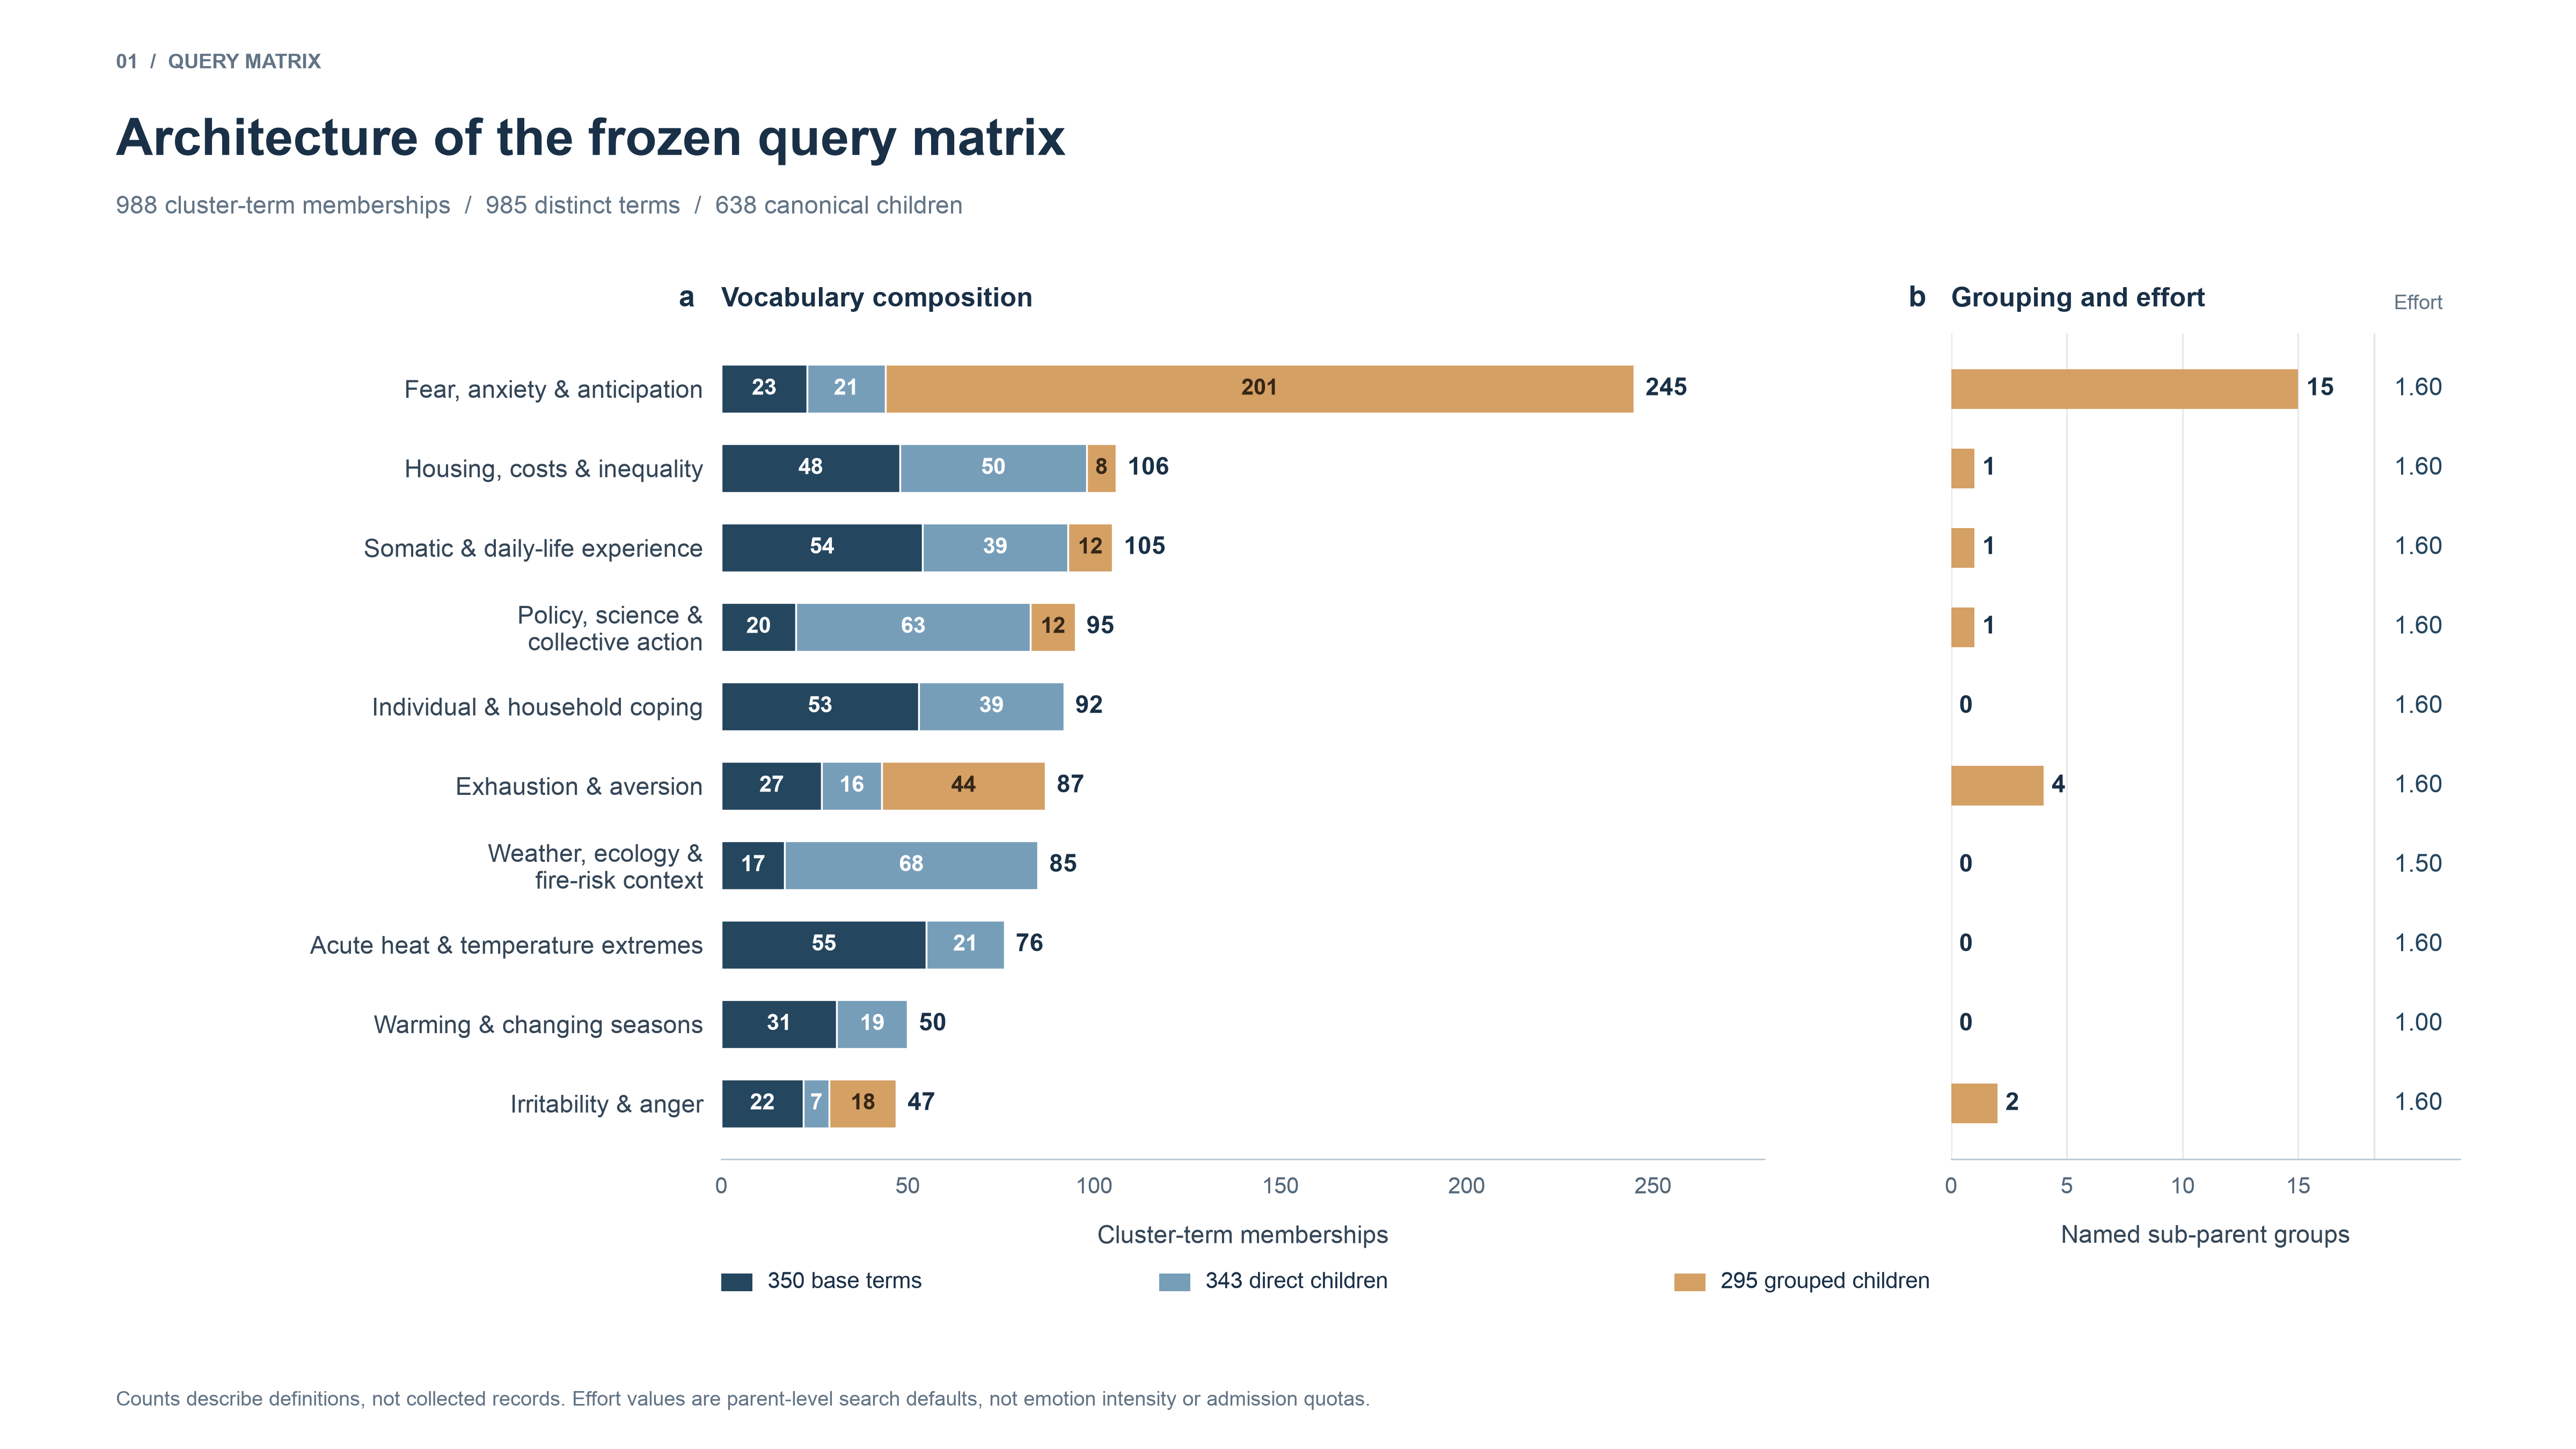

In [3]:
def make_figure_1(data):
    parents=sorted(data['parents'],key=lambda p:-p['total'])
    fig=plt.figure(figsize=(16,9));gs=fig.add_gridspec(1,2,left=.28,right=.955,bottom=.20,top=.77,width_ratios=[2.05,1],wspace=.24)
    a=fig.add_subplot(gs[0]);b=fig.add_subplot(gs[1]);a.set_label('a');b.set_label('b')
    header(fig,1,'Architecture of the frozen query matrix','988 cluster-term memberships  /  985 distinct terms  /  638 canonical children')
    ys=np.arange(10);left=np.zeros(10)
    for field,color in [('base',C['base']),('direct',C['direct']),('grouped',C['grouped'])]:
        values=np.array([p[field] for p in parents]);a.barh(ys,values,left=left,height=.62,color=color,edgecolor='white',linewidth=.8,zorder=3)
        for yy,l,v in zip(ys,left,values):
            if v:a.text(l+v/2,yy,str(v),ha='center',va='center',fontsize=10,fontweight='bold',color='white' if field!='grouped' else '#362717')
        left+=values
    for yy,p in zip(ys,parents):a.text(p['total']+3,yy,str(p['total']),ha='left',va='center',fontsize=11,fontweight='bold')
    a.set_yticks(ys,[p['name'].replace(' & ',' &\n') if len(p['name'])>34 else p['name'] for p in parents]);a.set_ylim(9.7,-.7);a.set_xlim(0,280)
    a.set_xlabel('Cluster-term memberships',labelpad=12);a.set_xticks([0,50,100,150,200,250]);a.tick_params(length=0,pad=8);a.spines['left'].set_visible(False)
    panel_title(a,'a','Vocabulary composition')
    b.barh(ys,[p['groups'] for p in parents],height=.50,color=C['amber'],zorder=3)
    for yy,p in zip(ys,parents):
        b.text(p['groups']+.35,yy,str(p['groups']),va='center',fontsize=11,fontweight='bold')
        b.text(20.2,yy,f"{p['weight']:.2f}",ha='center',va='center',fontsize=11,color=C['navy'])
    b.axvline(18.3,color=C['grid'],lw=.8);b.set_ylim(a.get_ylim());b.set_yticks([]);b.set_xlim(0,22);b.set_xticks([0,5,10,15]);grid(b,'x');b.spines['left'].set_visible(False)
    b.set_xlabel('Named sub-parent groups',labelpad=12);panel_title(b,'b','Grouping and effort')
    b.text(20.2,-.95,'Effort',ha='center',va='bottom',fontsize=9,color=C['muted'])
    key(fig,.28,.115,C['base'],'350 base terms');key(fig,.45,.115,C['direct'],'343 direct children');key(fig,.65,.115,C['grouped'],'295 grouped children')
    footer(fig,'Counts describe definitions, not collected records. Effort values are parent-level search defaults, not emotion intensity or admission quotas.')
    return fig

figure_1 = make_figure_1(DATA)
path_1 = save_figure(figure_1, 'figure_01_matrix_architecture', OUTPUT_DIR, QA_DIR)
print(path_1.name)
plt.close(figure_1)
try:
    from IPython import get_ipython
    if get_ipython() is not None:
        from IPython.display import display, Image
        display(Image(filename=str(path_1), width=1100))
except ImportError:
    pass


## Figure 2: Nested vocabulary hierarchy

Outer parent area represents its membership total. Leaf areas partition the available interior of that parent. Headers and gutters mean cross-parent leaf areas should not be compared as a separate global measure.


figure_02_nested_hierarchy.png


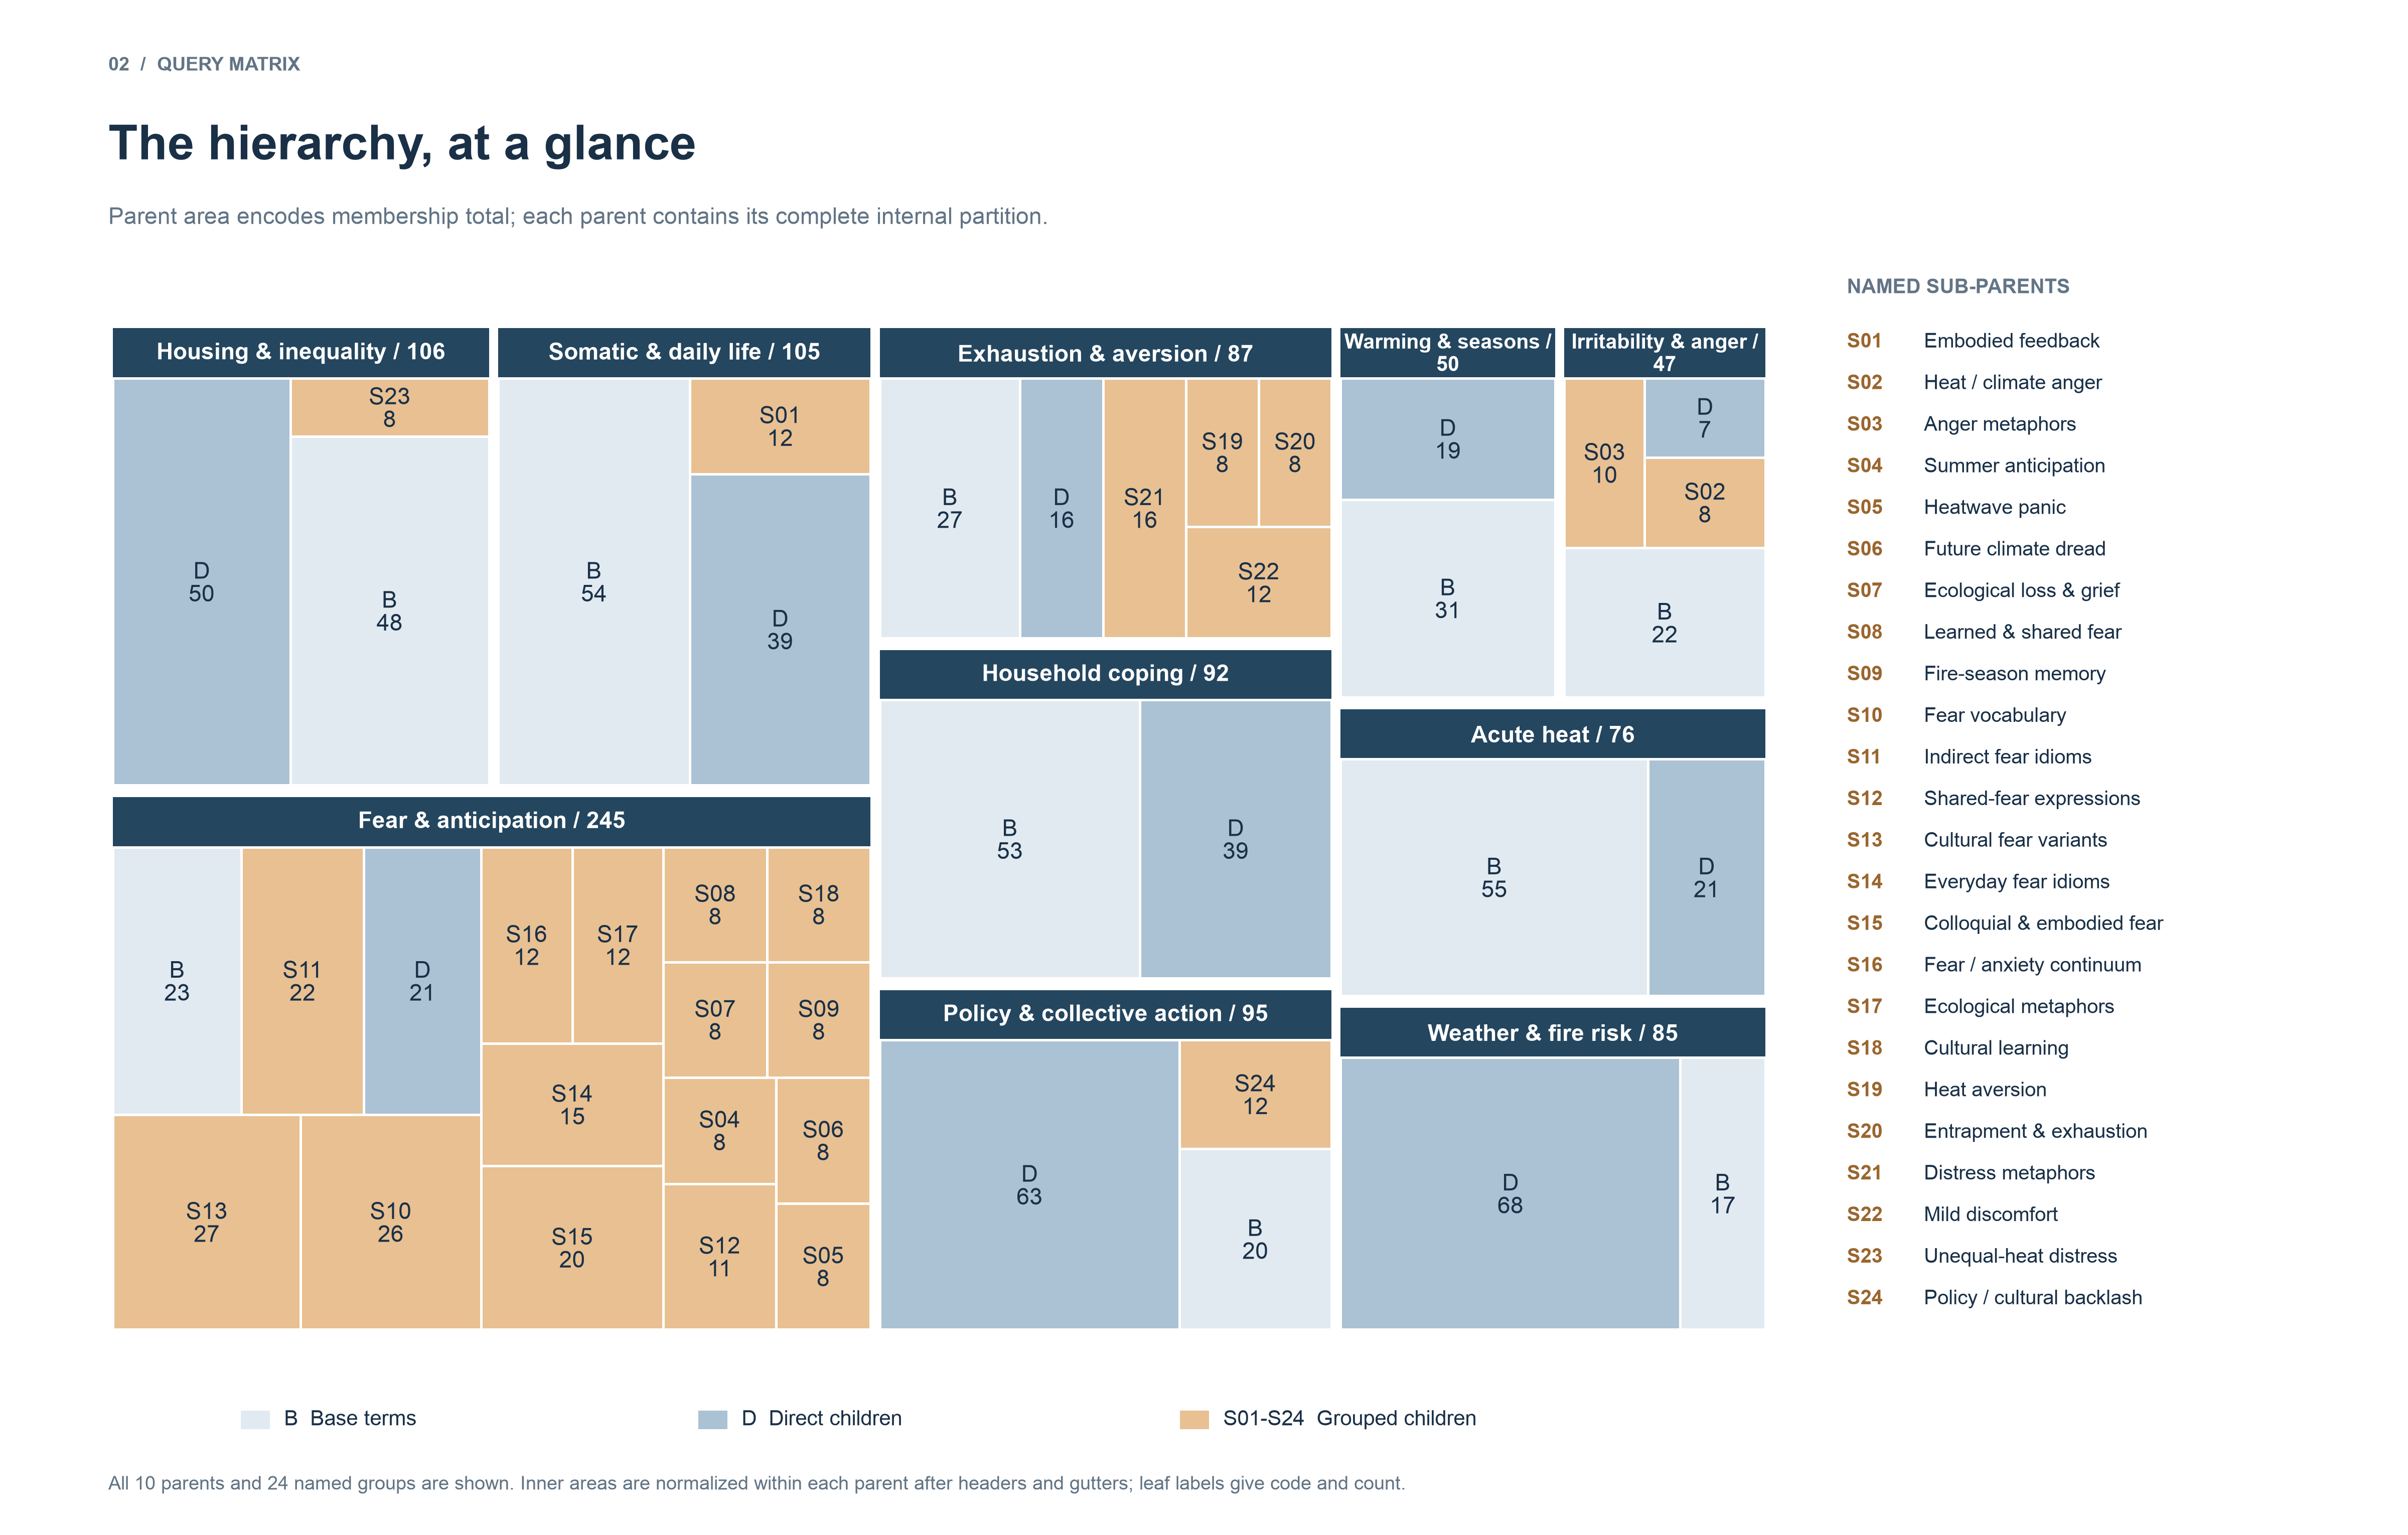

In [4]:
def make_figure_2(data):
    fig=plt.figure(figsize=(16,10.2));ax=fig.add_axes([.045,.13,.69,.66]);ax.set_xlim(0,100);ax.set_ylim(0,48);ax.axis('off')
    header(fig,2,'The hierarchy, at a glance','Parent area encodes membership total; each parent contains its complete internal partition.')
    parents=sorted(data['parents'],key=lambda p:-p['total']);rects=treemap([p['total'] for p in parents],0,0,100,48);fig.canvas.draw()
    groups=[s for p in data['parents'] for s in p['subparents']];codes={s['id']:f'S{i+1:02d}' for i,s in enumerate(groups)}
    for p,(x,y,w,h) in zip(parents,rects):
        gap=.28;header_h=2.65
        ax.add_patch(patches.Rectangle((x+gap,y+gap),w-2*gap,h-2*gap,facecolor='white',edgecolor='white',lw=1.3))
        ax.add_patch(patches.Rectangle((x+gap,y+h-header_h),w-2*gap,header_h-gap,facecolor=C['navy'],edgecolor='none'))
        fit_rect_text(ax,(x+gap,y+h-header_h,w-2*gap,header_h-gap),f"{p['short']}  /  {p['total']}",color='white',maxsize=11.1,minsize=8.6,bold=True)
        leaves=[dict(label='B',count=p['base'],kind='base'),dict(label='D',count=p['direct'],kind='direct')]+[dict(label=codes[s['id']],count=s['count'],kind='grouped') for s in p['subparents']]
        leaves=sorted([s for s in leaves if s['count']>0],key=lambda s:-s['count'])
        inner=(x+gap,y+gap,w-2*gap,h-header_h-gap)
        child_rects=treemap([s['count'] for s in leaves],*inner)
        for s,(xx,yy,ww,hh) in zip(leaves,child_rects):
            colors={'base':'#E1EAF1','direct':'#AAC2D3','grouped':'#E8C092'}
            ax.add_patch(patches.Rectangle((xx,yy),ww,hh,facecolor=colors[s['kind']],edgecolor='white',lw=1.2))
            fit_rect_text(ax,(xx,yy,ww,hh),s['label']+f"\n{s['count']}",maxsize=11,minsize=8.4)
    fig.text(.767,.809,'NAMED SUB-PARENTS',fontsize=9.5,fontweight='bold',color=C['muted'])
    for i,s in enumerate(groups):
        yy=.777-i*.0271
        fig.text(.767,yy,codes[s['id']],fontsize=9.5,fontweight='bold',color='#9A662E',va='center')
        fig.text(.799,yy,SUBLABEL[s['id']].replace('\n',' '),fontsize=9.6,va='center')
    key(fig,.10,.075,'#E1EAF1','B  Base terms');key(fig,.29,.075,'#AAC2D3','D  Direct children');key(fig,.49,.075,'#E8C092','S01-S24  Grouped children')
    footer(fig,'All 10 parents and 24 named groups are shown. Inner areas are normalized within each parent after headers and gutters; leaf labels give code and count.')
    return fig

figure_2 = make_figure_2(DATA)
path_2 = save_figure(figure_2, 'figure_02_nested_hierarchy', OUTPUT_DIR, QA_DIR)
print(path_2.name)
plt.close(figure_2)
try:
    from IPython import get_ipython
    if get_ipython() is not None:
        from IPython.display import display, Image
        display(Image(filename=str(path_2), width=1100))
except ImportError:
    pass


## Figure 3: Fear and anxiety taxonomy

The 245-member fear/anxiety parent includes 23 base terms, 21 direct children and 201 grouped children. Only illustrative expressions are displayed; all assigned children remain in the group counts.


figure_03_fear_taxonomy.png


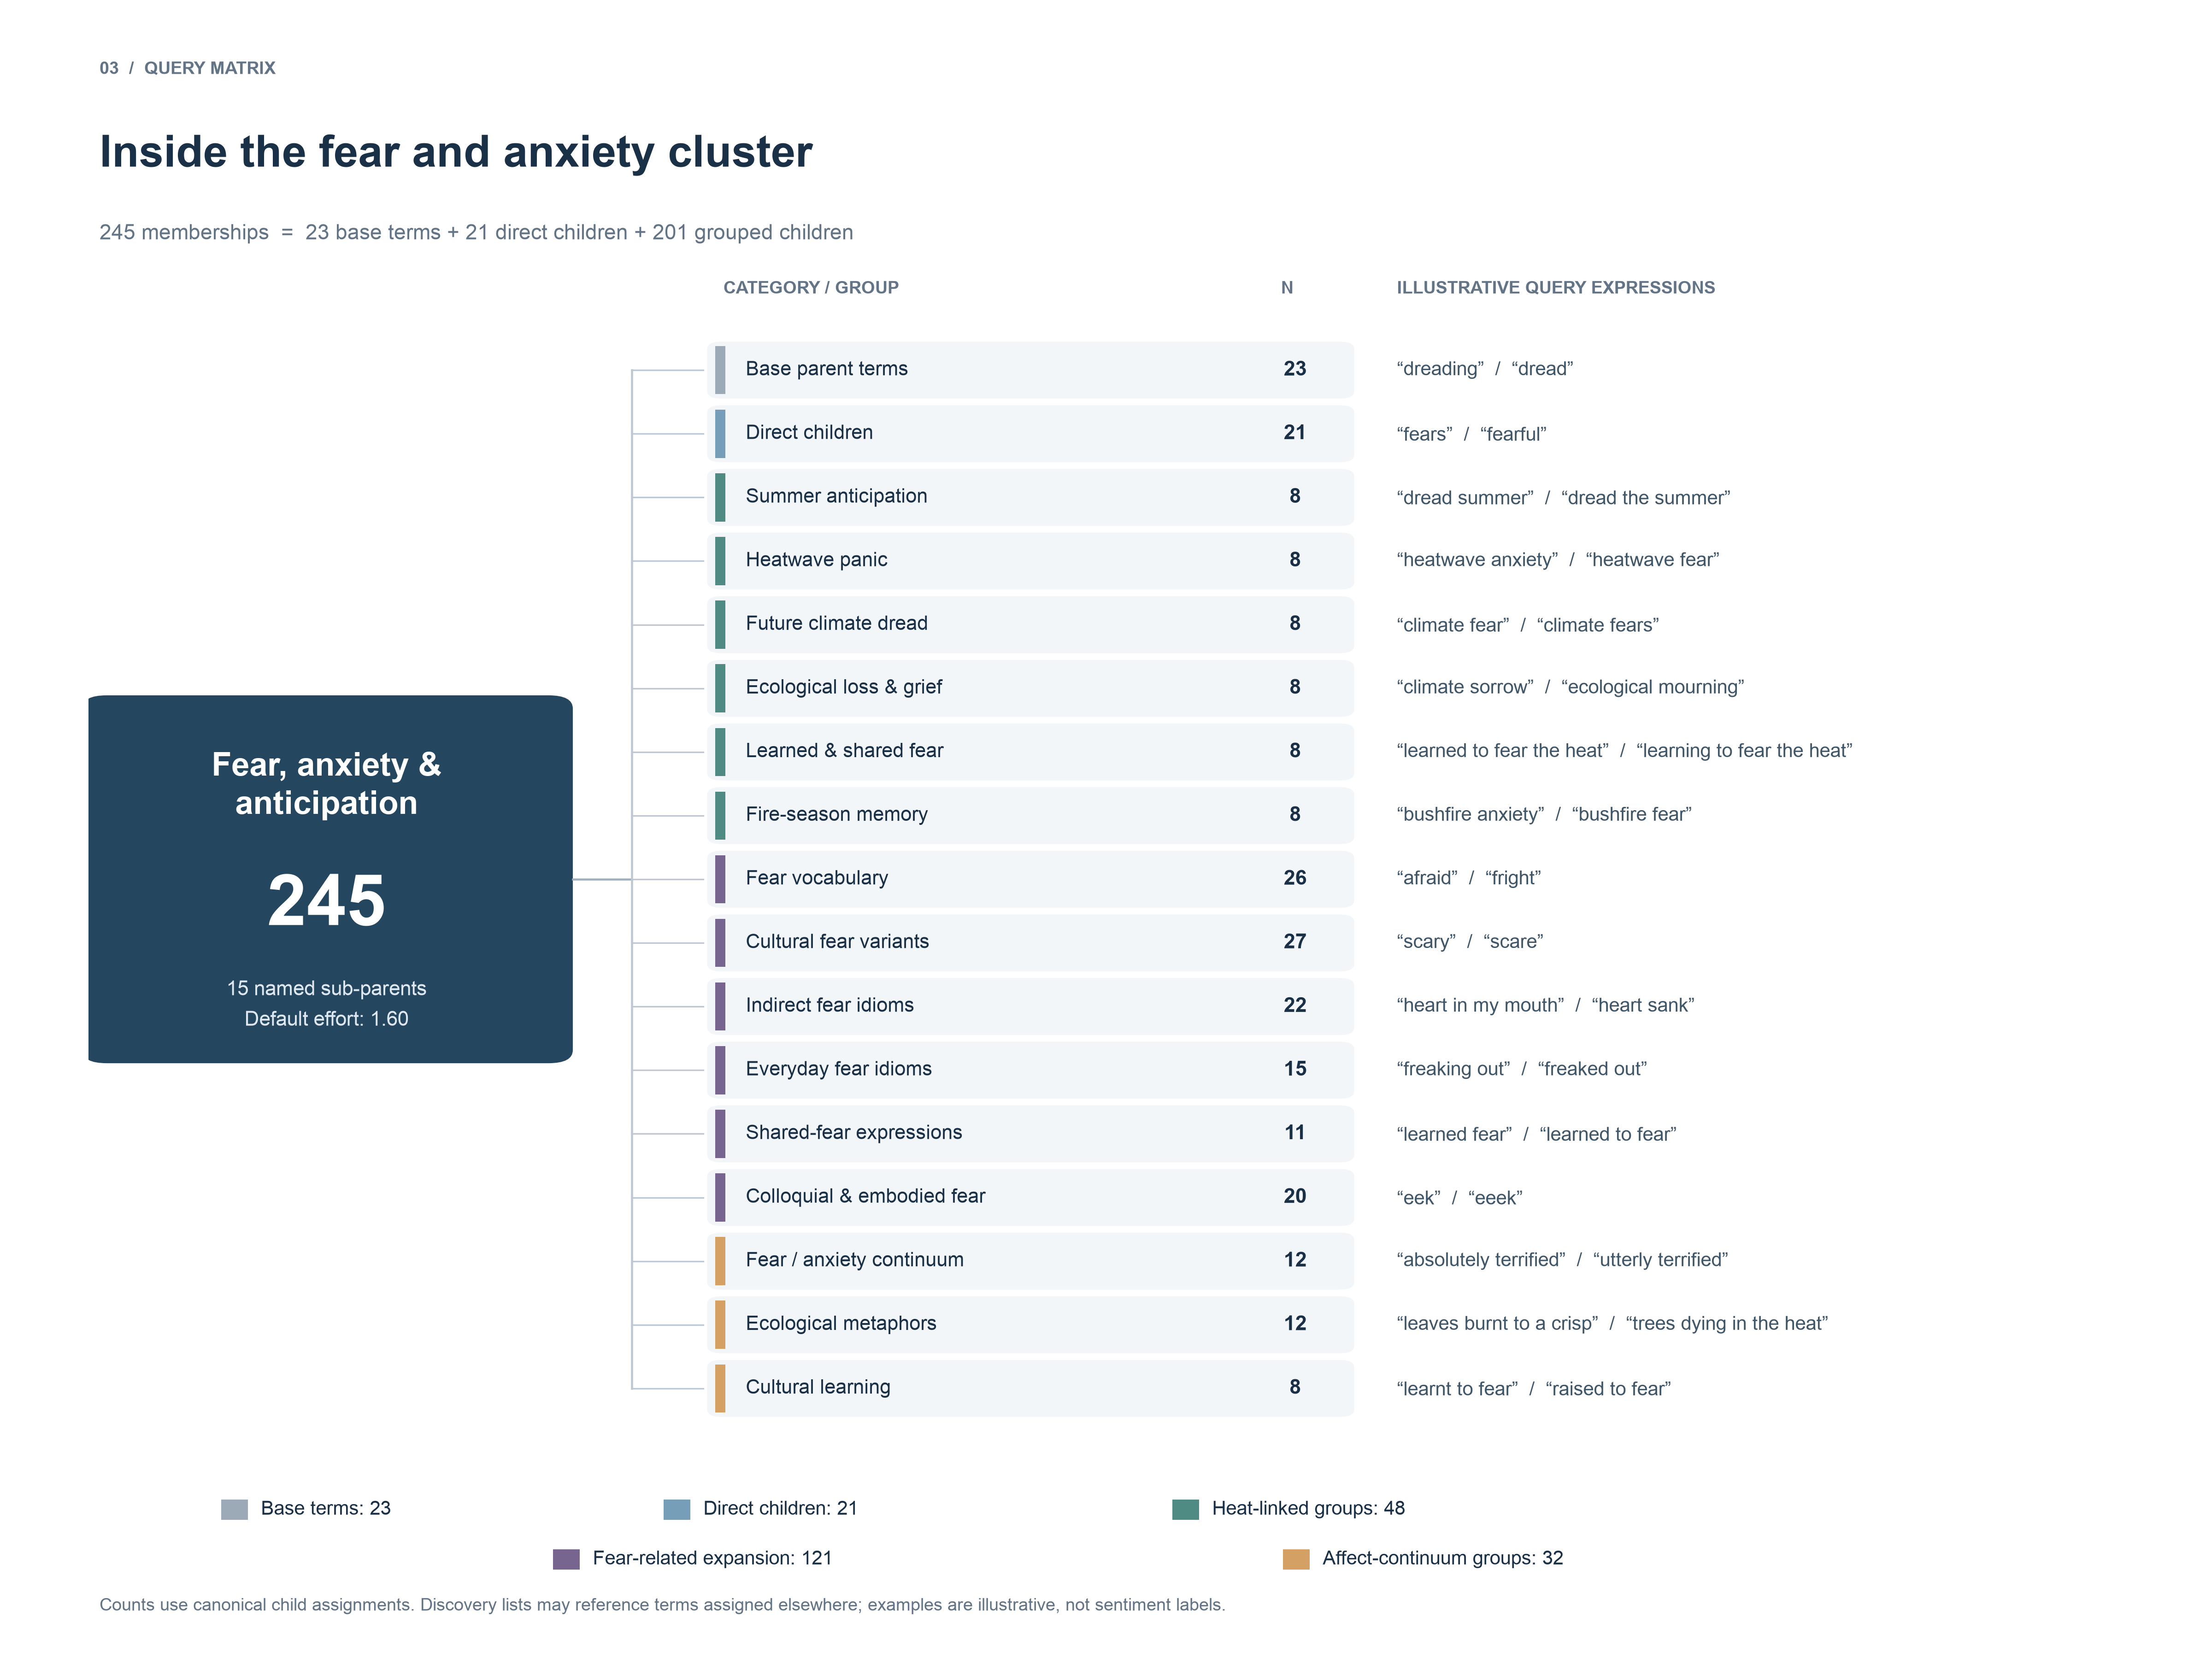

In [5]:
def make_figure_3(data):
    p=next(p for p in data['parents'] if p['id']=='climate_anxiety_anticipation');subs={s['id']:s for s in p['subparents']}
    early=['summer_anticipatory_fear','heatwave_panic','future_climate_dread','ecological_loss_grief','learned_shared_fear','fire_season_memory']
    lexical=['fear_ordinary_variants','fear_ordinary_cultural_variants','fear_indirect_idioms','fear_ordinary_indirect_idioms','fear_learned_shared_expression','fear_colloquial_interjections_and_embodied_idioms']
    continuum=['continuum_fear_anxiety','continuum_ecological_metaphor','continuum_cultural_learning']
    rows=[('Base parent terms',p['base'],p['base_terms'],C['slate']),('Direct children',p['direct'],p['direct_terms'],C['steel'])]
    for group,color in [(early,C['teal']),(lexical,C['plum']),(continuum,C['amber'])]:
        rows.extend((SUBLABEL[sid].replace('\n',' '),subs[sid]['count'],subs[sid]['terms'],color) for sid in group)
    assert len(rows)==17 and sum(r[1] for r in rows)==245
    fig=plt.figure(figsize=(16,12));ax=fig.add_axes([.04,.14,.92,.66]);ax.set_xlim(0,1);ax.set_ylim(0,1);ax.axis('off')
    header(fig,3,'Inside the fear and anxiety cluster','245 memberships  =  23 base terms + 21 direct children + 201 grouped children')
    ys=np.linspace(.965,.035,len(rows));bus=.267;root=(.005,.34,.225,.32)
    ax.add_patch(patches.FancyBboxPatch(root[:2],root[2],root[3],boxstyle='round,pad=0.008,rounding_size=0.012',facecolor=C['navy'],edgecolor='none'))
    ax.text(.117,.585,'Fear, anxiety &\nanticipation',ha='center',va='center',fontsize=17,color='white',fontweight='bold',linespacing=1.25)
    ax.text(.117,.475,'245',ha='center',va='center',fontsize=37,color='white',fontweight='bold')
    ax.text(.117,.386,'15 named sub-parents\nDefault effort: 1.60',ha='center',va='center',fontsize=10.5,color='#DFE8F0',linespacing=1.5)
    ax.plot([.238,bus],[.5,.5],color='#A2B0BD',lw=1.1);ax.plot([bus,bus],[ys[-1],ys[0]],color='#BCC8D3',lw=1.1)
    ax.text(.312,1.035,'CATEGORY / GROUP',fontsize=9,fontweight='bold',color=C['muted']);ax.text(.586,1.035,'N',fontsize=9,fontweight='bold',color=C['muted']);ax.text(.643,1.035,'ILLUSTRATIVE QUERY EXPRESSIONS',fontsize=9,fontweight='bold',color=C['muted'])
    for (label,n,terms,color),y in zip(rows,ys):
        ax.plot([bus,.302],[y,y],color='#BCC8D3',lw=.8)
        ax.add_patch(patches.FancyBboxPatch((.308,y-.022),.31,.044,boxstyle='round,pad=0.004,rounding_size=.007',facecolor=C['pale'],edgecolor='none'))
        ax.add_patch(patches.Rectangle((.308,y-.022),.005,.044,facecolor=color,edgecolor='none'))
        ax.text(.323,y,label,va='center',fontsize=10.4)
        ax.text(.593,y,str(n),ha='center',va='center',fontsize=10.8,fontweight='bold',color=C['ink'])
        chosen=terms[:2]
        example='  /  '.join('“'+t+'”' for t in chosen)
        ax.text(.643,y,'\n'.join(textwrap.wrap(example,width=61,break_long_words=False)),va='center',fontsize=10.1,color='#405669',linespacing=1.12)
    key(fig,.10,.09,C['slate'],'Base terms: 23');key(fig,.30,.09,C['steel'],'Direct children: 21');key(fig,.53,.09,C['teal'],'Heat-linked groups: 48')
    key(fig,.25,.060,C['plum'],'Fear-related expansion: 121');key(fig,.58,.060,C['amber'],'Affect-continuum groups: 32')
    footer(fig,'Counts use canonical child assignments. Discovery lists may reference terms assigned elsewhere; examples are illustrative, not sentiment labels.')
    return fig

figure_3 = make_figure_3(DATA)
path_3 = save_figure(figure_3, 'figure_03_fear_taxonomy', OUTPUT_DIR, QA_DIR)
print(path_3.name)
plt.close(figure_3)
try:
    from IPython import get_ipython
    if get_ipython() is not None:
        from IPython.display import display, Image
        display(Image(filename=str(path_3), width=1100))
except ImportError:
    pass


## Figure 4: Version trajectory and declared coverage

All 19 preserved version stages are shown, including the intermediate fear and variant expansions. Definition and search-register units are deliberately separated.


figure_04_version_and_coverage.png


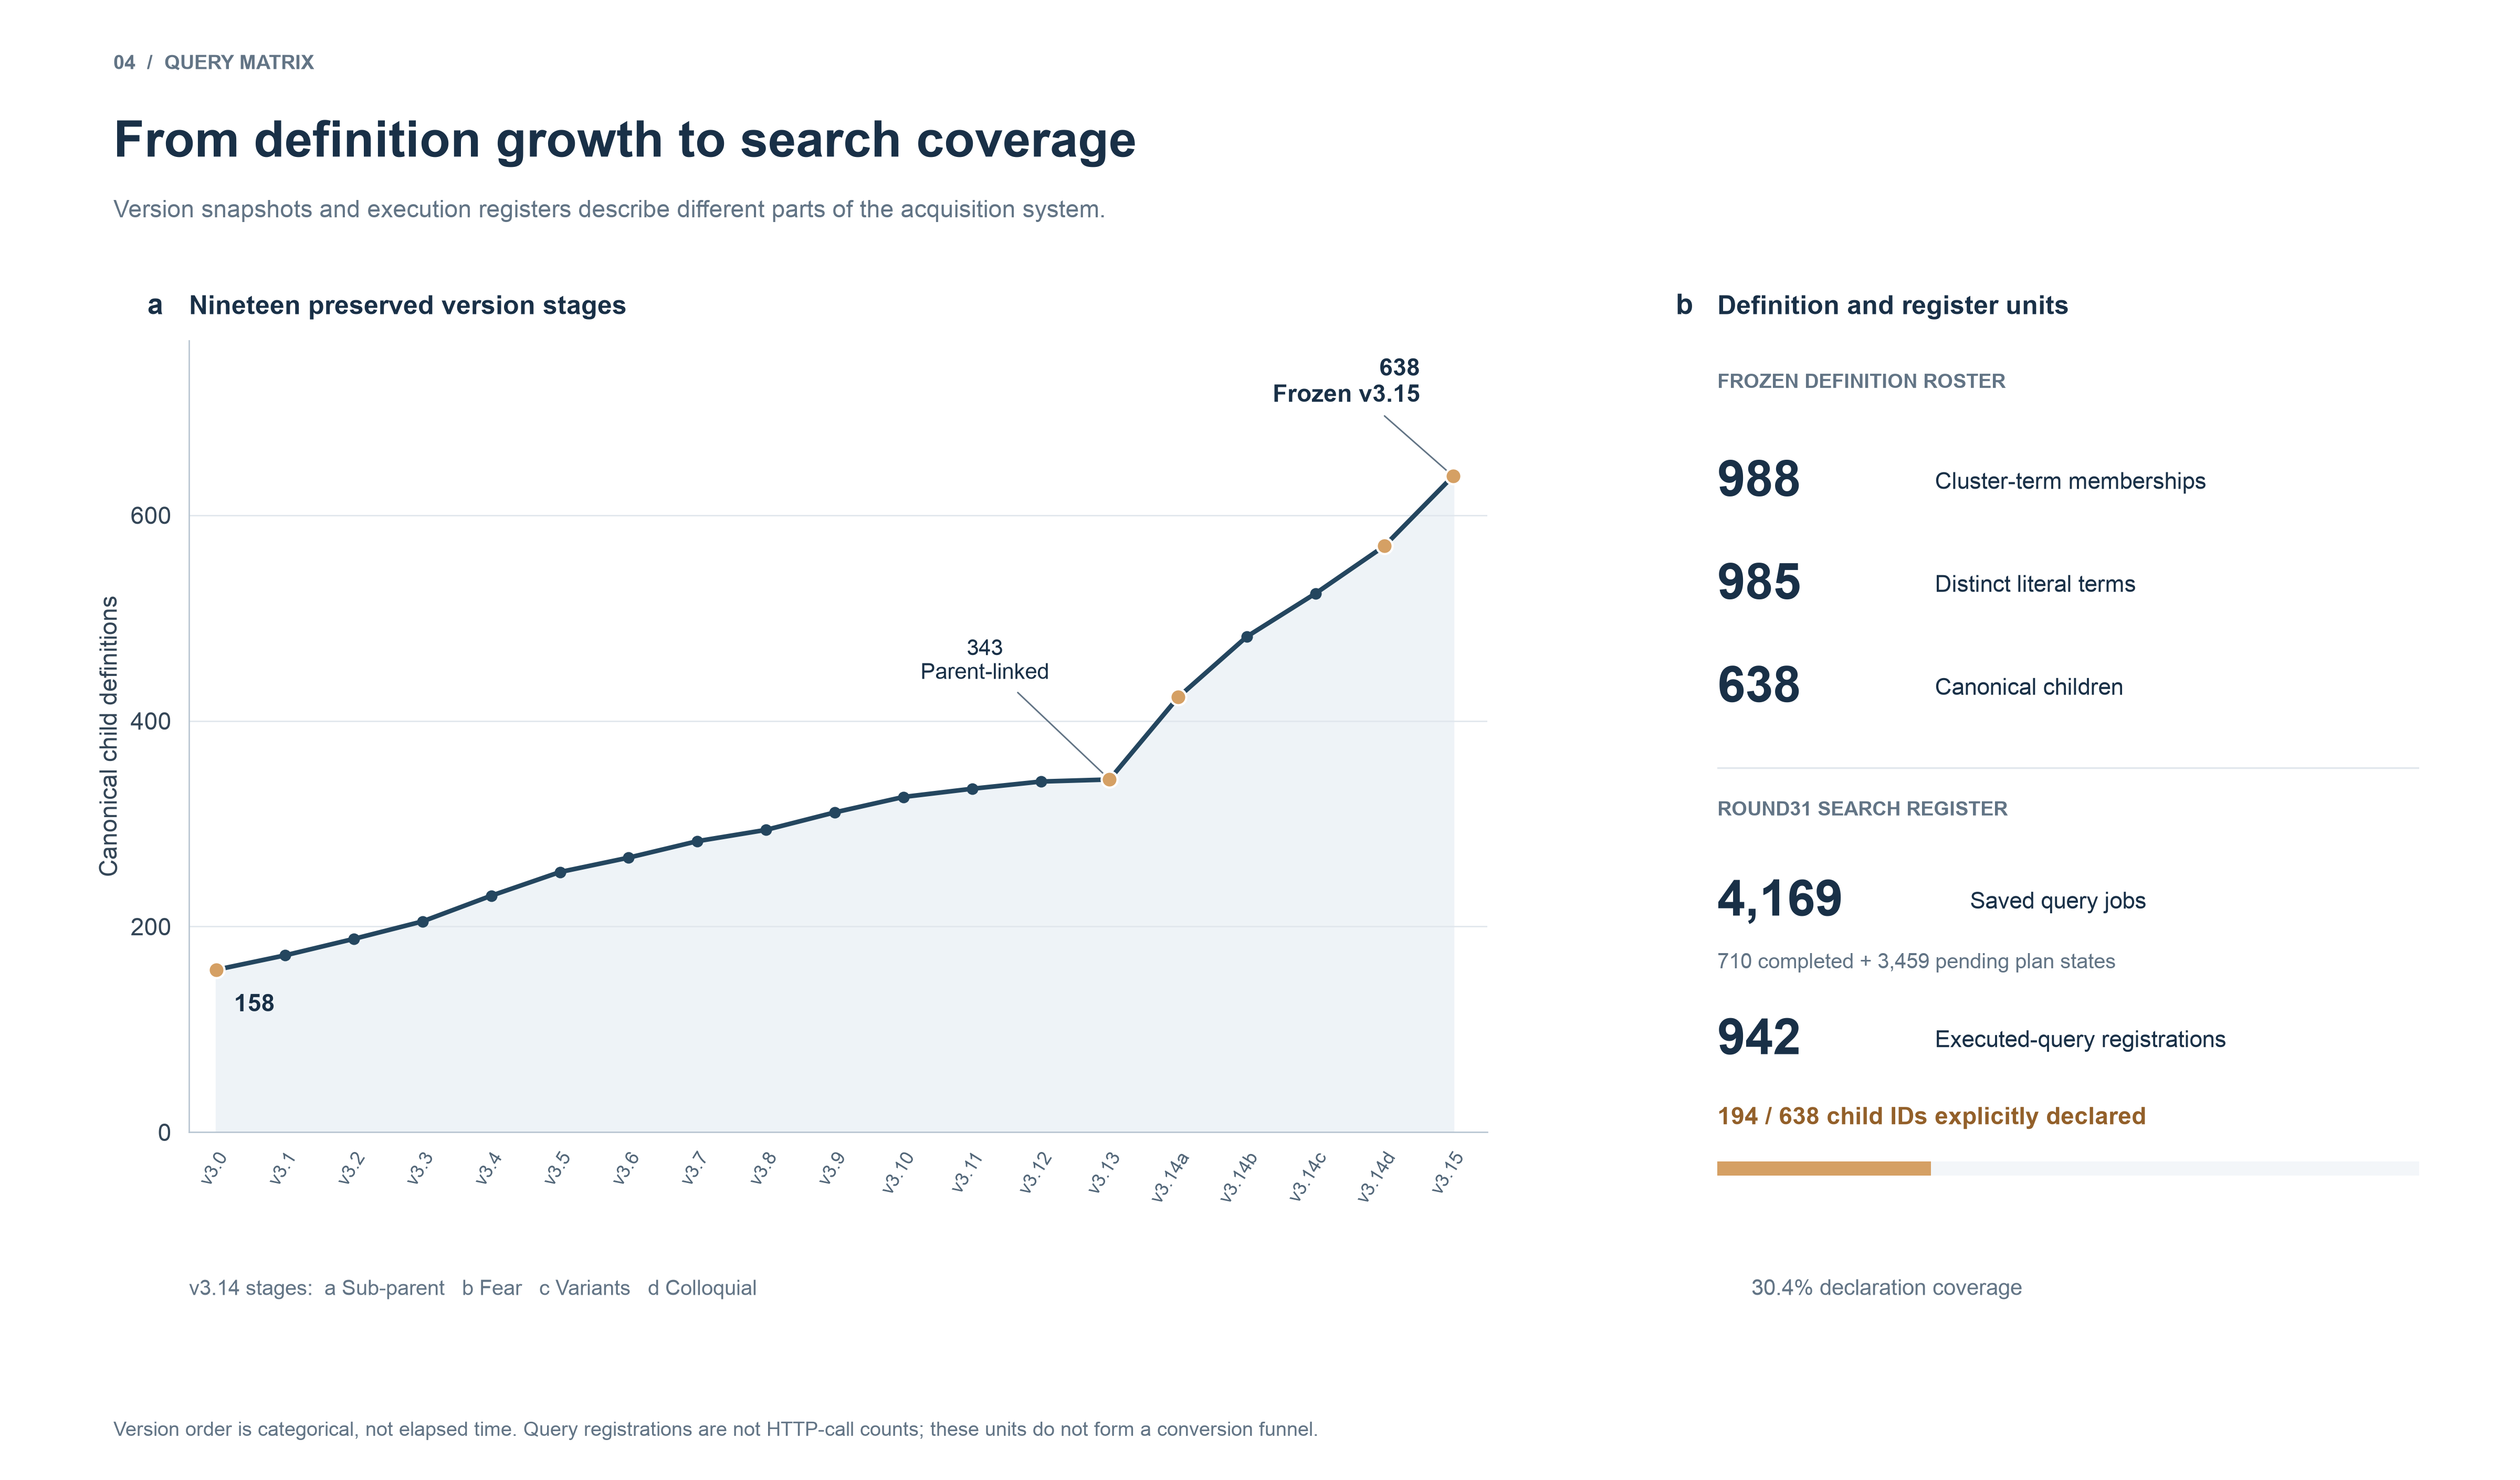

In [6]:
def make_figure_4(data):
    fig=plt.figure(figsize=(16,9.4));gs=fig.add_gridspec(1,2,left=.075,right=.96,bottom=.235,top=.77,width_ratios=[1.85,1],wspace=.23)
    a=fig.add_subplot(gs[0]);b=fig.add_subplot(gs[1]);a.set_label('a');b.set_label('b')
    header(fig,4,'From definition growth to search coverage','Version snapshots and execution registers describe different parts of the acquisition system.')
    hist=data['history'];xs=np.arange(len(hist));vals=np.array([h['count'] for h in hist])
    assert np.all(np.diff(vals)>=0)
    a.fill_between(xs,0,vals,color='#EEF3F7',zorder=0);a.plot(xs,vals,color=C['navy'],lw=2.1,marker='o',ms=4.3,zorder=3)
    for idx in [0,13,14,17,18]:a.scatter([idx],[vals[idx]],s=53,color=C['amber'],edgecolor='white',lw=1,zorder=4)
    a.annotate('158',xy=(0,158),xytext=(8,-19),textcoords='offset points',fontsize=11,fontweight='bold')
    a.annotate('343\nParent-linked',xy=(13,343),xytext=(-57,46),textcoords='offset points',fontsize=10,ha='center',arrowprops={'arrowstyle':'-','lw':.7,'color':C['muted']})
    a.annotate('638\nFrozen v3.15',xy=(18,638),xytext=(-15,34),textcoords='offset points',fontsize=11,fontweight='bold',ha='right',arrowprops={'arrowstyle':'-','lw':.7,'color':C['muted']})
    ticks=[h['label'].replace('\nSub-parent','a').replace('\nFear','b').replace('\nVariants','c').replace('\nColloquial','d') for h in hist]
    a.set_xticks(xs,ticks,rotation=58,ha='right',rotation_mode='anchor',fontsize=8.6);a.set_xlim(-.4,18.5);a.set_ylim(0,770);a.set_yticks([0,200,400,600]);grid(a)
    a.set_ylabel('Canonical child definitions');panel_title(a,'a','Nineteen preserved version stages')
    b.axis('off');b.set_xlim(0,1);b.set_ylim(0,1);panel_title(b,'b','Definition and register units')
    b.text(0,.94,'FROZEN DEFINITION ROSTER',fontsize=9,color=C['muted'],fontweight='bold')
    for y,n,label in [(.82,988,'Cluster-term memberships'),(.69,985,'Distinct literal terms'),(.56,638,'Canonical children')]:
        b.text(0,y,f'{n:,}',fontsize=23,fontweight='bold',va='center');b.text(.31,y,label,fontsize=10.5,va='center')
    b.plot([0,1],[.46,.46],color=C['grid'],lw=.8)
    b.text(0,.40,'ROUND31 SEARCH REGISTER',fontsize=9,color=C['muted'],fontweight='bold')
    b.text(0,.29,'4,169',fontsize=23,fontweight='bold',va='center');b.text(.36,.29,'Saved query jobs',fontsize=10.5,va='center')
    b.text(0,.207,'710 completed + 3,459 pending plan states',fontsize=9.5,color=C['muted'])
    b.text(0,.115,'942',fontsize=23,fontweight='bold',va='center');b.text(.31,.115,'Executed-query registrations',fontsize=10.5,va='center')
    b.text(0,.01,'194 / 638 child IDs explicitly declared',fontsize=11,fontweight='bold',color='#93602A')
    b.add_patch(patches.Rectangle((0,-.055),1,.018,facecolor=C['pale'],edgecolor='none',clip_on=False));b.add_patch(patches.Rectangle((0,-.055),194/638,.018,facecolor=C['amber'],edgecolor='none',clip_on=False))
    fig.text(.695,.125,'30.4% declaration coverage',fontsize=10,color=C['muted'])
    fig.text(.075,.125,'v3.14 stages:  a Sub-parent   b Fear   c Variants   d Colloquial',fontsize=9.5,color=C['muted'])
    footer(fig,'Version order is categorical, not elapsed time. Query registrations are not HTTP-call counts; these units do not form a conversion funnel.')
    return fig

figure_4 = make_figure_4(DATA)
path_4 = save_figure(figure_4, 'figure_04_version_and_coverage', OUTPUT_DIR, QA_DIR)
print(path_4.name)
plt.close(figure_4)
try:
    from IPython import get_ipython
    if get_ipython() is not None:
        from IPython.display import display, Image
        display(Image(filename=str(path_4), width=1100))
except ImportError:
    pass


## Figure 5: Family focus and search registration progress

The upper panel compares normalized family shares using each phase's own denominator. The lower panel gives cumulative registration scale, without implying an hourly rate.


figure_05_search_focus_progress.png


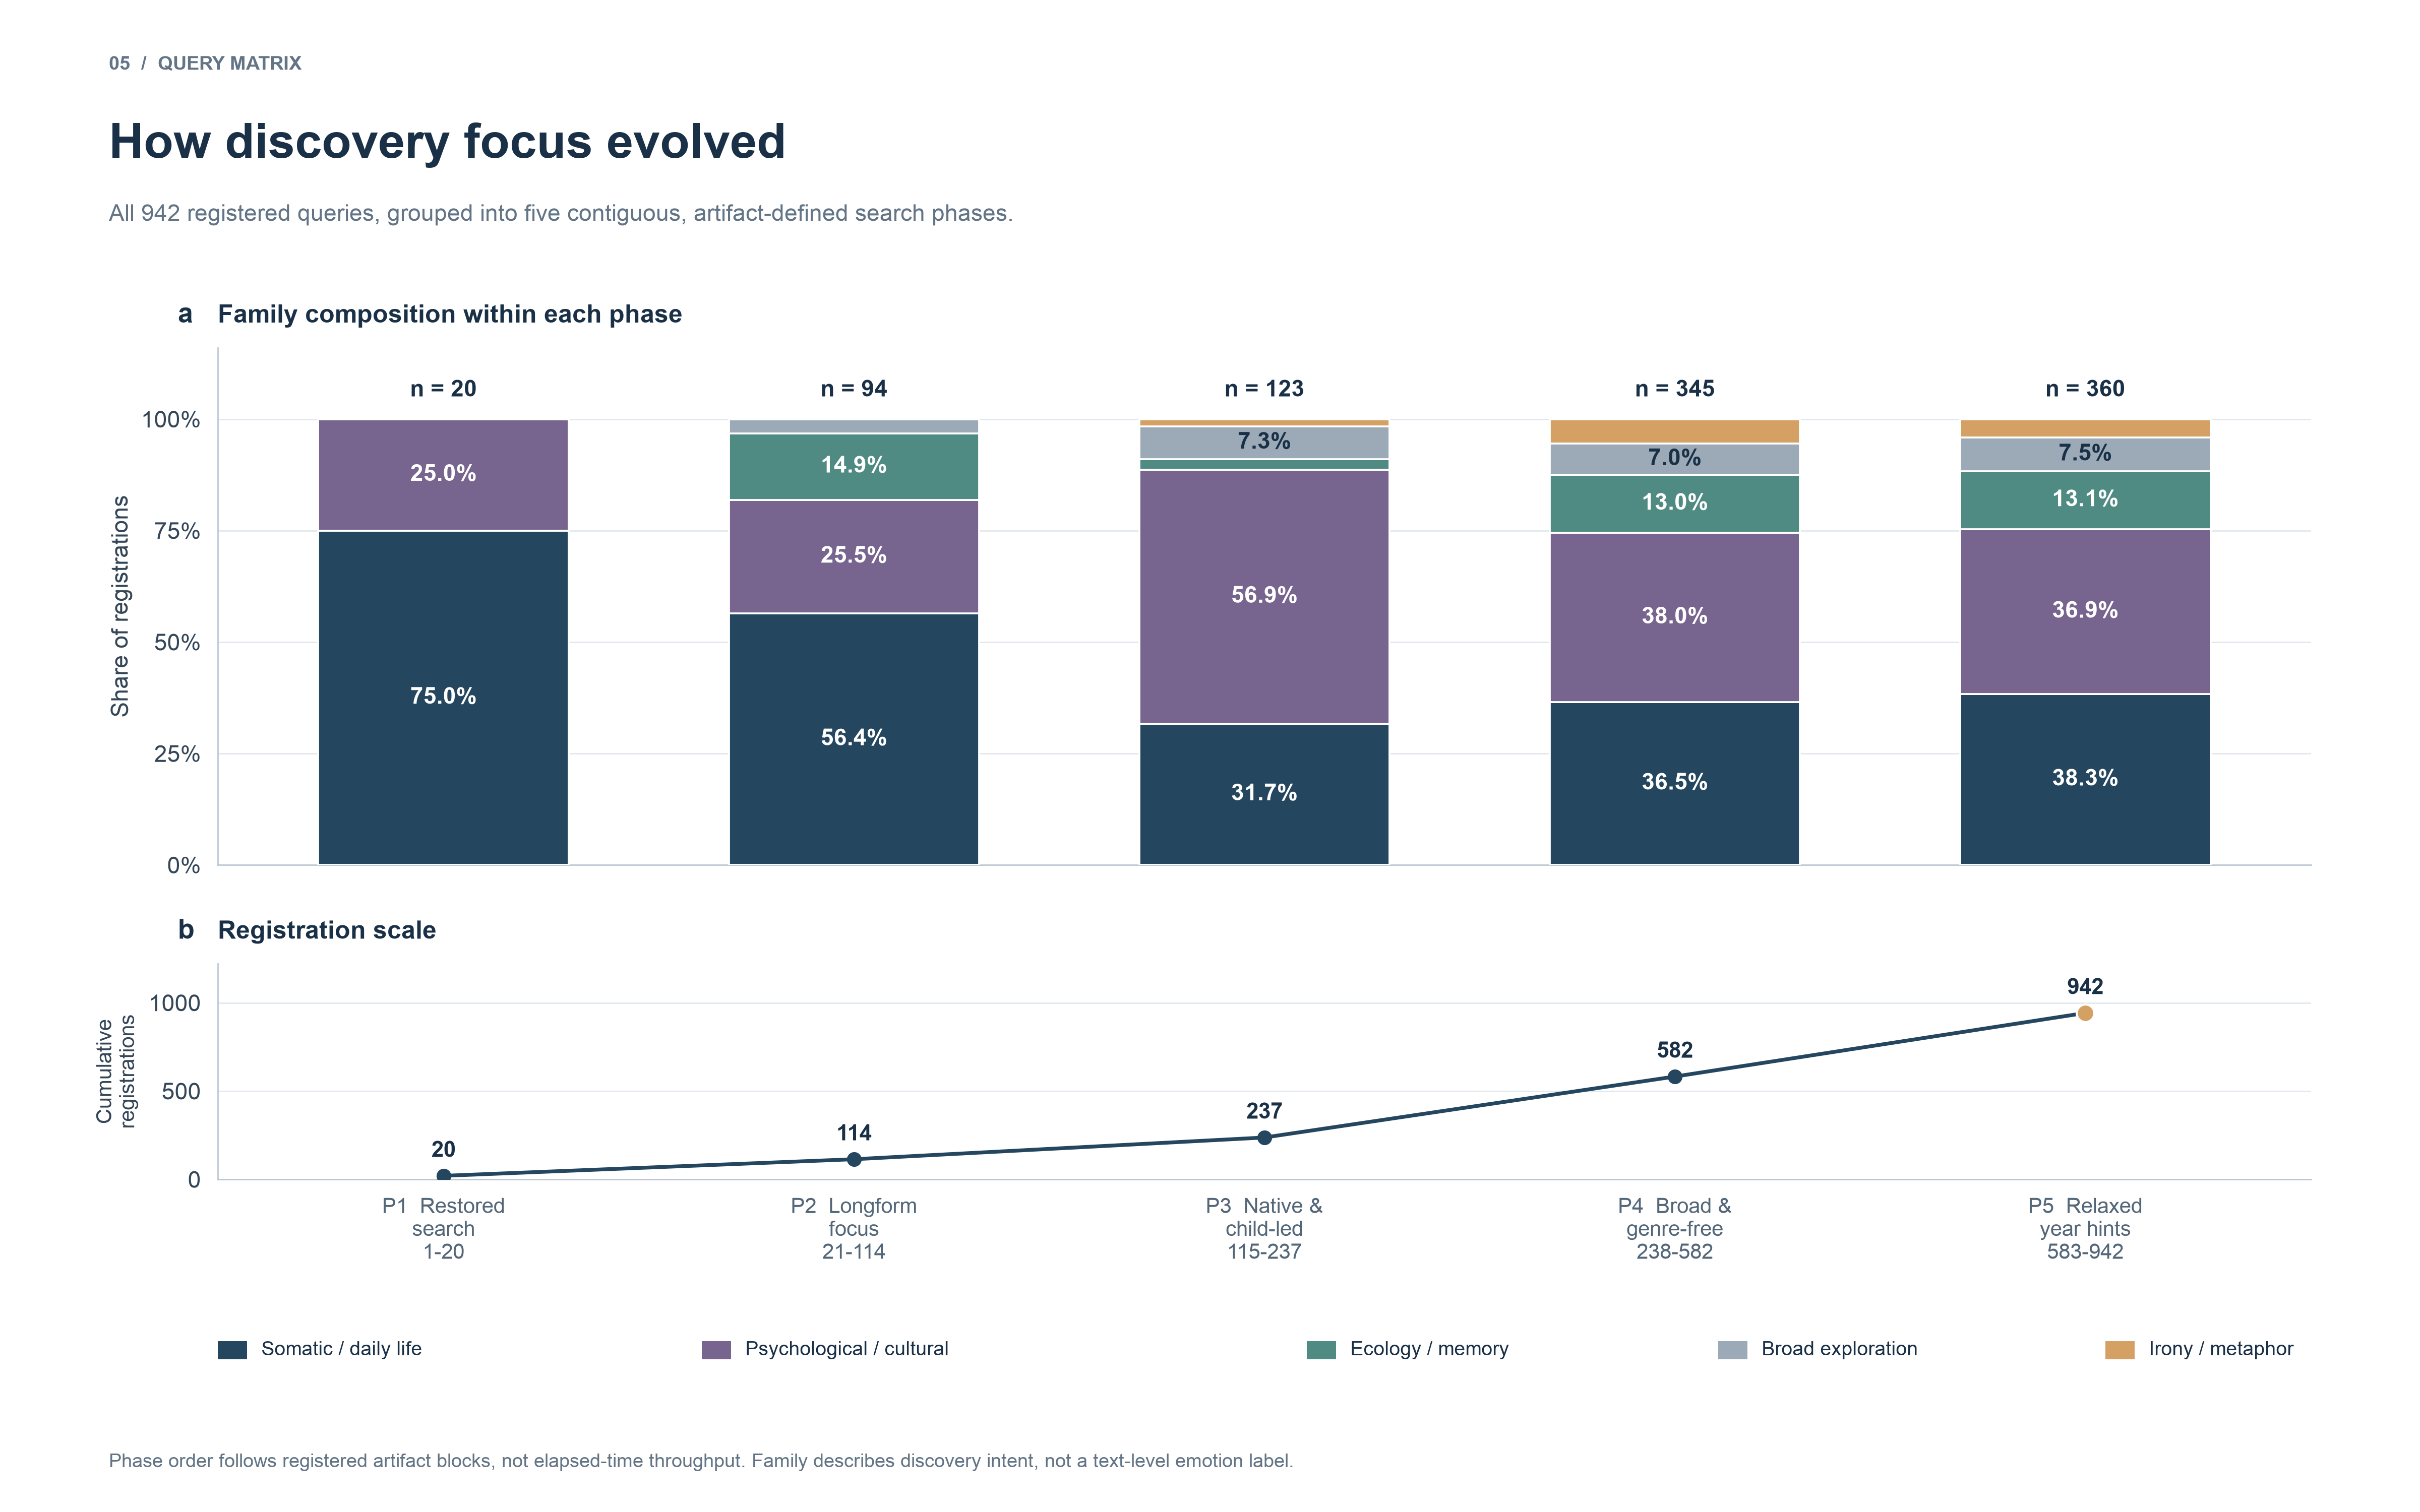

In [7]:
def make_figure_5(data):
    counts,_=phase_statistics(data);den=counts.sum(axis=1);shares=counts/den[:,None]*100
    fig=plt.figure(figsize=(16,10));gs=fig.add_gridspec(2,1,left=.09,right=.955,bottom=.22,top=.77,height_ratios=[2.4,1],hspace=.27)
    a=fig.add_subplot(gs[0]);b=fig.add_subplot(gs[1]);a.set_label('a');b.set_label('b')
    header(fig,5,'How discovery focus evolved','All 942 registered queries, grouped into five contiguous, artifact-defined search phases.')
    x=np.arange(5);bottom=np.zeros(5)
    for j,f in enumerate(FAMILIES):
        v=shares[:,j];a.bar(x,v,bottom=bottom,width=.61,color=FCOL[f],edgecolor='white',lw=.9,zorder=3)
        for i,n in enumerate(v):
            if n>=6:a.text(i,bottom[i]+n/2,f'{n:.1f}%',ha='center',va='center',fontsize=11,fontweight='bold',color='white' if f in FAMILIES[:3] else C['ink'])
        bottom+=v
    for i,n in enumerate(den):a.text(i,104,f'n = {n}',ha='center',va='bottom',fontsize=11,fontweight='bold')
    a.set_xlim(-.55,4.55);a.set_ylim(0,116);a.set_yticks([0,25,50,75,100]);a.yaxis.set_major_formatter(PercentFormatter(100,decimals=0));a.set_xticks([]);a.set_ylabel('Share of registrations');grid(a);panel_title(a,'a','Family composition within each phase')
    cumulative=den.cumsum();b.plot(x,cumulative,color=C['navy'],lw=1.8,marker='o',ms=6,zorder=3)
    b.scatter([4],[942],s=70,color=C['amber'],edgecolor='white',lw=1,zorder=4)
    for i,n in enumerate(cumulative):b.annotate(f'{n:,}',(i,n),xytext=(0,9),textcoords='offset points',ha='center',fontsize=10.5,fontweight='bold')
    b.set_xlim(a.get_xlim());b.set_ylim(0,1220);b.set_yticks([0,500,1000]);b.set_ylabel('Cumulative\nregistrations',fontsize=10);grid(b)
    labels=[f"P{i+1}  {n}\n{data['phase_bounds'][i]+1}-{data['phase_bounds'][i+1]}" for i,n in enumerate(data['phase_names'])]
    b.set_xticks(x,labels,fontsize=10);panel_title(b,'b','Registration scale')
    for x0,f in zip([.09,.29,.54,.71,.87],FAMILIES):key(fig,x0,.107,FCOL[f],FLAB[f],fs=9.3)
    footer(fig,'Phase order follows registered artifact blocks, not elapsed-time throughput. Family describes discovery intent, not a text-level emotion label.')
    return fig

figure_5 = make_figure_5(DATA)
path_5 = save_figure(figure_5, 'figure_05_search_focus_progress', OUTPUT_DIR, QA_DIR)
print(path_5.name)
plt.close(figure_5)
try:
    from IPython import get_ipython
    if get_ipython() is not None:
        from IPython.display import display, Image
        display(Image(filename=str(path_5), width=1100))
except ImportError:
    pass


## Figure 6: Query features across search phases

Metadata attribution requires a recorded weight and at least one declared child ID. Genre and city features use fixed literal patterns. Geographic expansion requires at least two recognized geographic alternatives in parenthesized OR clauses.


figure_06_query_feature_evolution.png


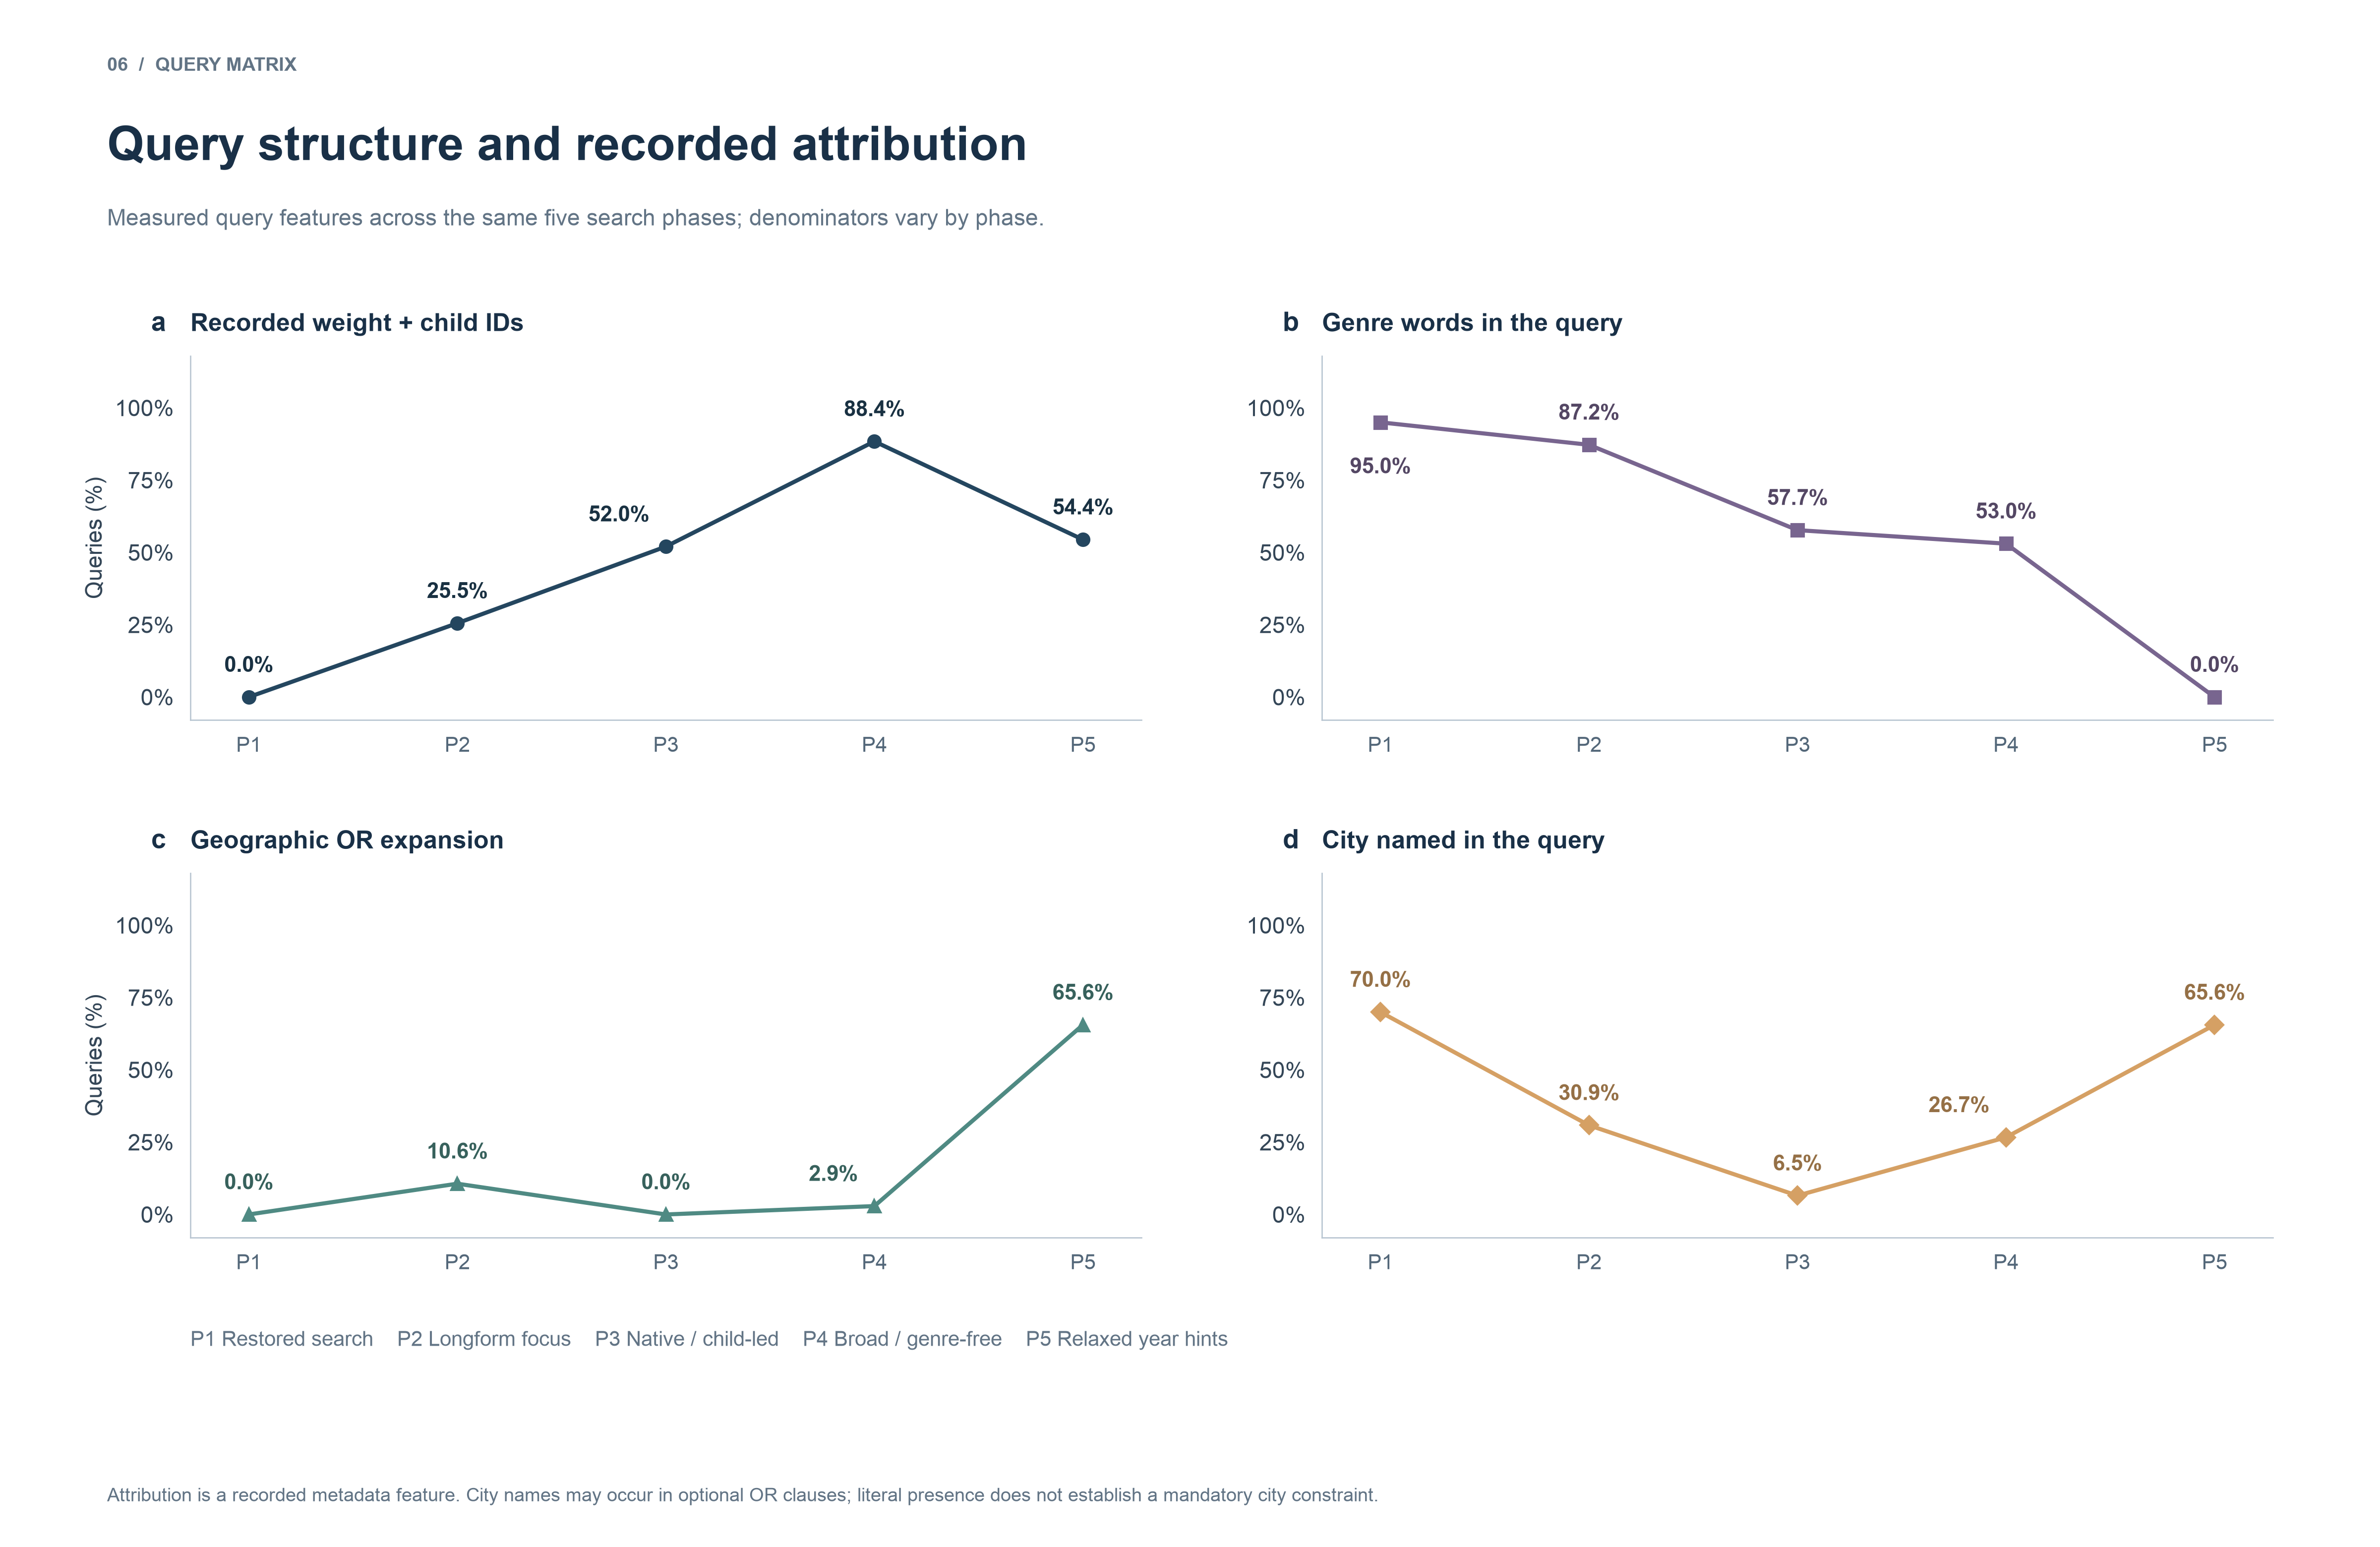

In [8]:
def make_figure_6(data):
    _,rates=phase_statistics(data)
    fig=plt.figure(figsize=(16,10.4));gs=fig.add_gridspec(2,2,left=.08,right=.955,bottom=.20,top=.77,hspace=.42,wspace=.19)
    header(fig,6,'Query structure and recorded attribution','Measured query features across the same five search phases; denominators vary by phase.')
    titles=['Recorded weight + child IDs','Genre words in the query','Geographic OR expansion','City named in the query']
    colors=[C['navy'],C['plum'],C['teal'],C['amber']];markers=['o','s','^','D']
    for k in range(4):
        a=fig.add_subplot(gs[k//2,k%2]);a.set_label('abcd'[k]);vals=rates[k]
        a.plot(np.arange(5),vals,color=colors[k],lw=2.0,marker=markers[k],ms=6,zorder=3)
        for i,v in enumerate(vals):
            offset=-17 if v>90 else 10
            rising=i<4 and vals[i+1]-v>35
            dark=mcolors.to_hex(np.array(mcolors.to_rgb(colors[k]))*.70)
            a.annotate(f'{v:.1f}%',(i,v),xytext=(-8 if rising else 0,offset),textcoords='offset points',ha='right' if rising else 'center',va='bottom' if offset>0 else 'top',fontsize=10.5,color=dark,fontweight='bold')
        a.set_ylim(-8,118);a.set_xlim(-.28,4.28);a.set_yticks([0,25,50,75,100]);a.yaxis.set_major_formatter(PercentFormatter(100,decimals=0));a.set_xticks(range(5),[f'P{i}' for i in range(1,6)])
        a.set_ylabel('Queries (%)' if k%2==0 else '');a.tick_params(length=0,pad=8);panel_title(a,'abcd'[k],titles[k])
    fig.text(.08,.13,'P1 Restored search    P2 Longform focus    P3 Native / child-led    P4 Broad / genre-free    P5 Relaxed year hints',fontsize=10.2,color=C['muted'])
    footer(fig,'Attribution is a recorded metadata feature. City names may occur in optional OR clauses; literal presence does not establish a mandatory city constraint.')
    return fig

figure_6 = make_figure_6(DATA)
path_6 = save_figure(figure_6, 'figure_06_query_feature_evolution', OUTPUT_DIR, QA_DIR)
print(path_6.name)
plt.close(figure_6)
try:
    from IPython import get_ipython
    if get_ipython() is not None:
        from IPython.display import display, Image
        display(Image(filename=str(path_6), width=1100))
except ImportError:
    pass


## Figure 7: Year targeting and actual net text additions

The first panel uses saved query-year hints; the second uses native publication years from the final net-addition report. Every 2003-2025 year is retained. This is not query-to-record causal attribution.


figure_07_year_targeting_and_additions.png


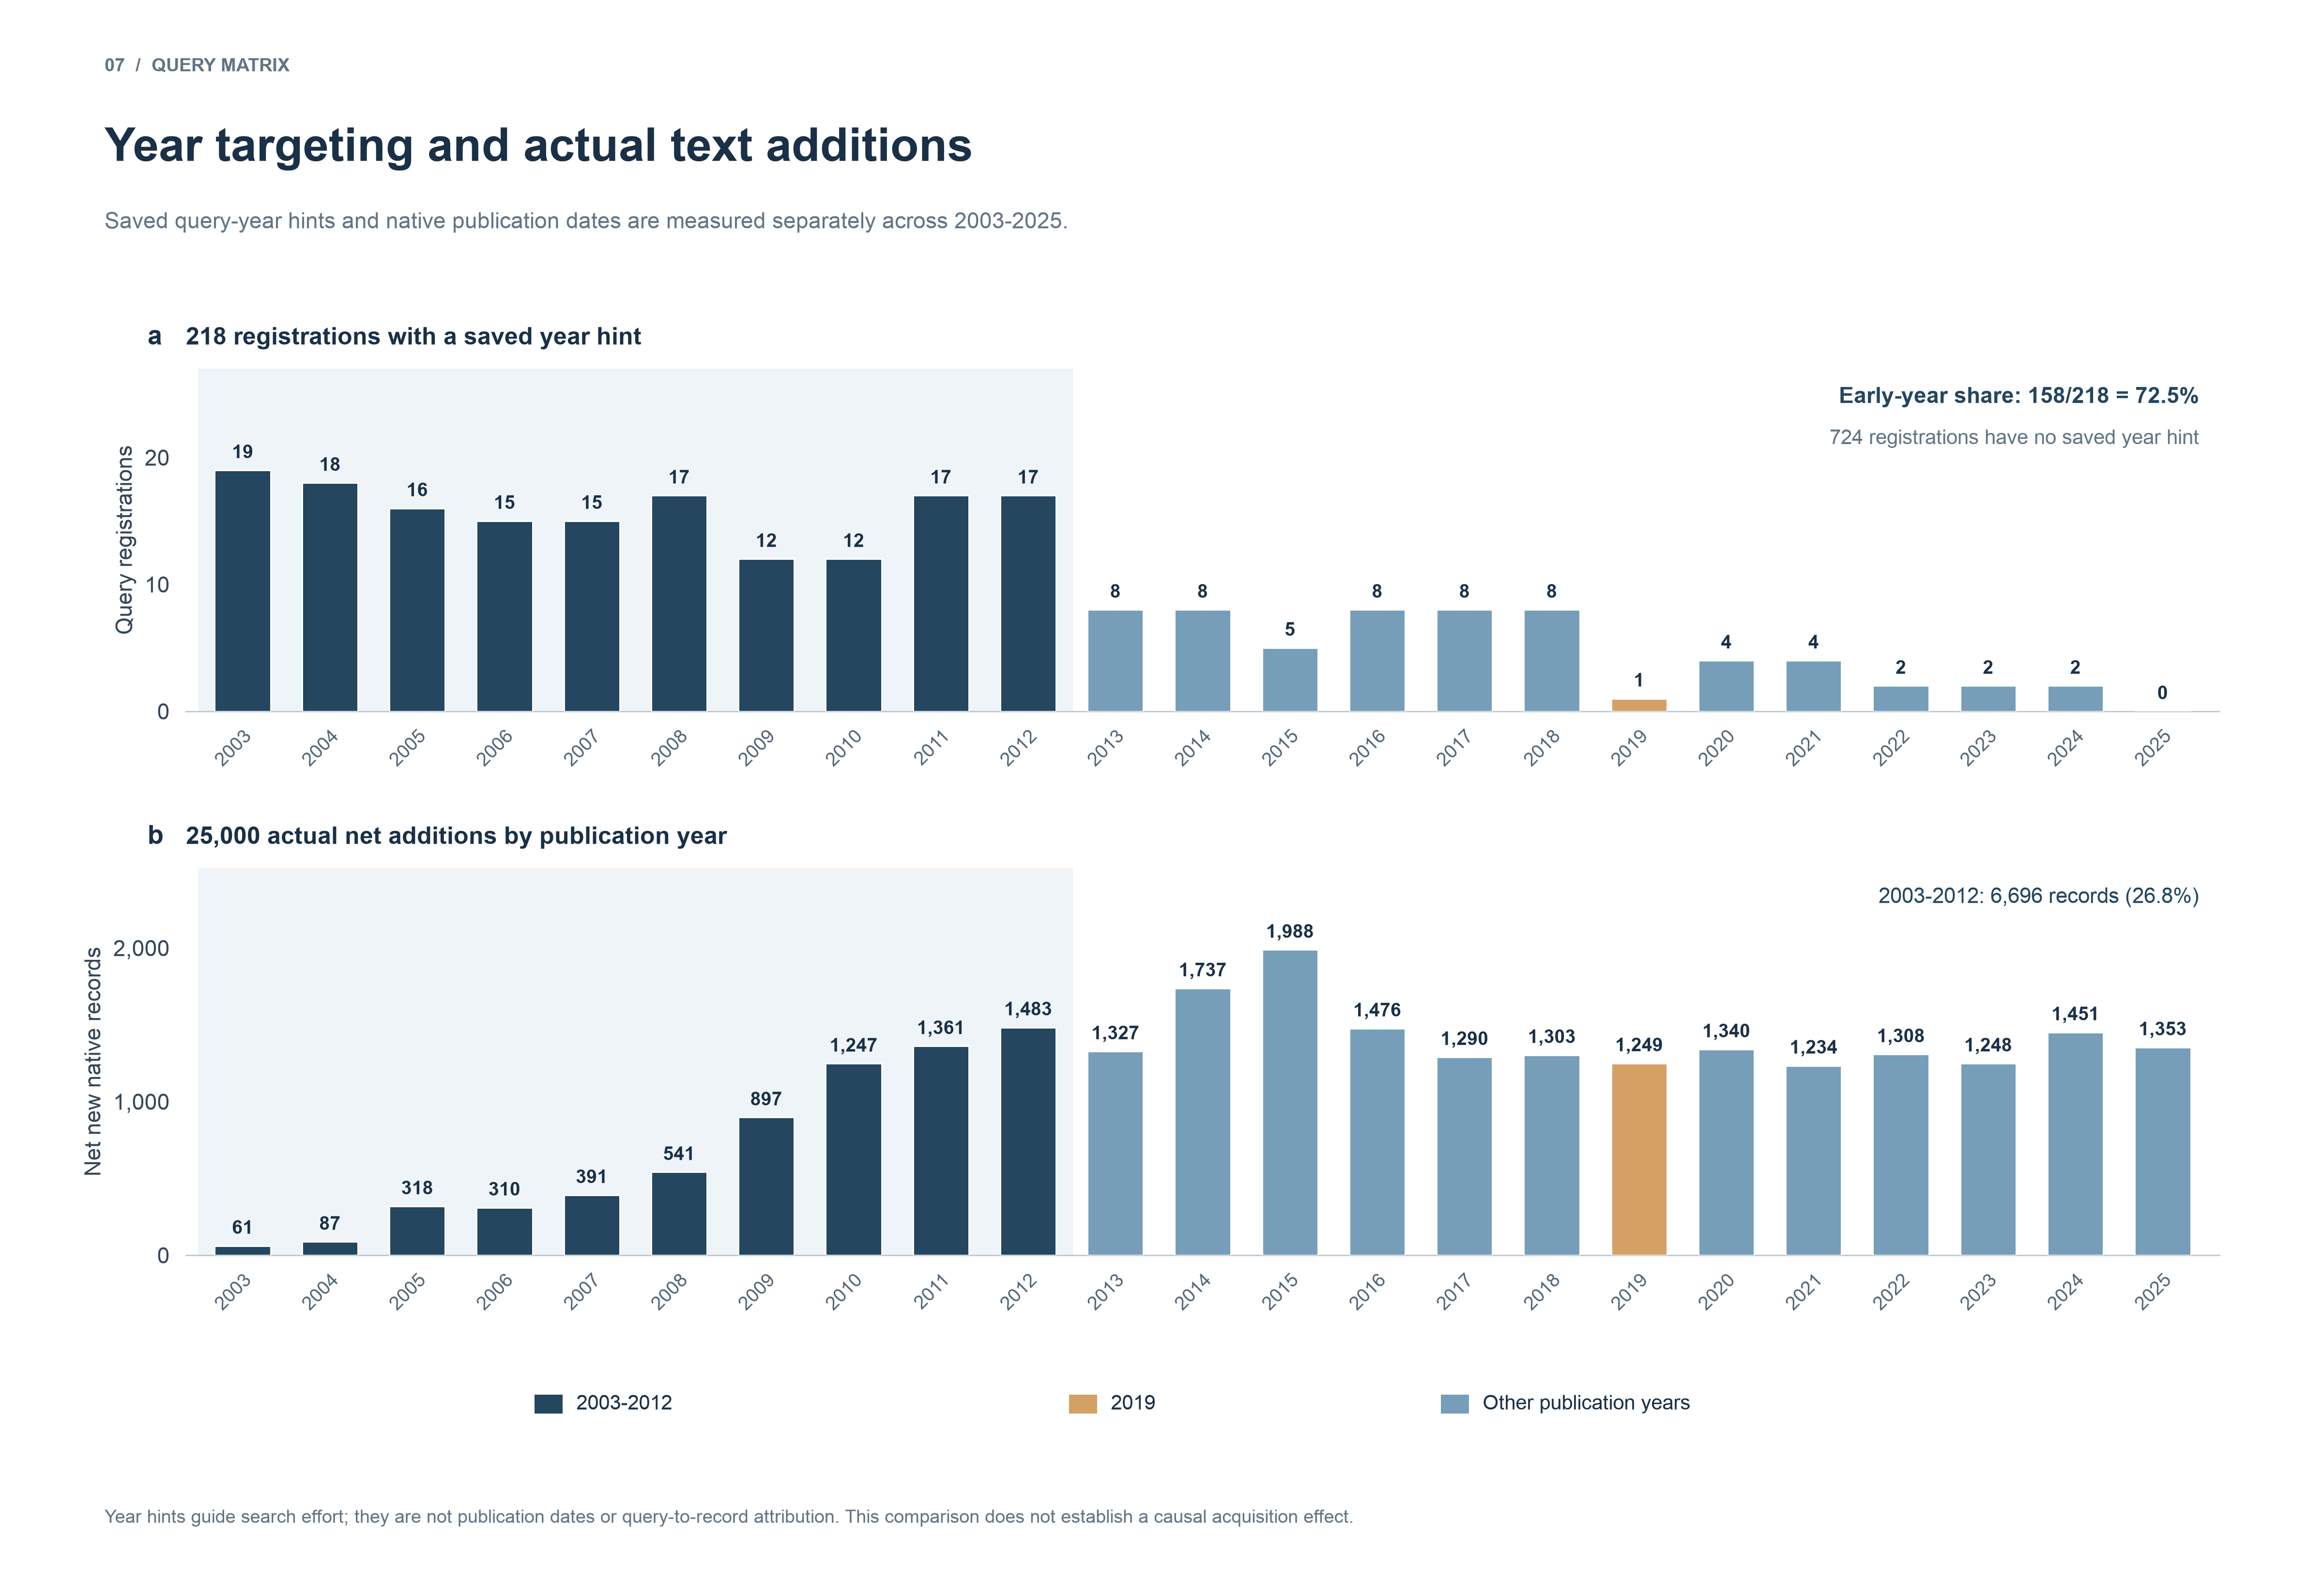

In [9]:
def make_figure_7(data):
    years=list(range(2003,2026));hints=Counter(int(q['year']) for q in data['queries'] if q['year'] is not None)
    qcounts=np.array([hints[y] for y in years]);new=np.array([next(r['new'] for r in data['annual'] if r['year']==y) for y in years])
    assert qcounts.sum()==218 and new.sum()==25000
    fig=plt.figure(figsize=(16,10.8));gs=fig.add_gridspec(2,1,left=.08,right=.955,bottom=.20,top=.765,height_ratios=[1,1.13],hspace=.43)
    a=fig.add_subplot(gs[0]);b=fig.add_subplot(gs[1]);a.set_label('a');b.set_label('b')
    header(fig,7,'Year targeting and actual text additions','Saved query-year hints and native publication dates are measured separately across 2003-2025.')
    xs=np.arange(23);colors=[C['navy'] if y<=2012 else C['amber'] if y==2019 else C['steel'] for y in years]
    for ax,values in [(a,qcounts),(b,new)]:
        ax.axvspan(-.5,9.5,color='#EFF4F8',zorder=0);ax.bar(xs,values,width=.64,color=colors,edgecolor='white',lw=.7,zorder=3)
        for x,v in zip(xs,values):ax.annotate(f'{v:,}',(x,v),xytext=(0,6),textcoords='offset points',ha='center',fontsize=9.4,fontweight='bold')
        ax.set_xlim(-.65,22.65);ax.tick_params(length=0,pad=8);ax.spines['left'].set_visible(False)
        ax.set_xticks(xs,[str(y) for y in years],rotation=45,ha='right',rotation_mode='anchor',fontsize=9.4)
    a.set_ylim(0,27);a.set_yticks([0,10,20]);a.set_ylabel('Query registrations');panel_title(a,'a','218 registrations with a saved year hint')
    a.text(.99,.90,f'Early-year share: {qcounts[:10].sum()}/218 = {qcounts[:10].sum()/218:.1%}',transform=a.transAxes,ha='right',fontsize=11,color=C['navy'],fontweight='bold')
    a.text(.99,.78,'724 registrations have no saved year hint',transform=a.transAxes,ha='right',fontsize=10,color=C['muted'])
    b.set_ylim(0,2520);b.set_yticks([0,1000,2000]);b.yaxis.set_major_formatter(FuncFormatter(lambda v,p:f'{v:,.0f}'));b.set_ylabel('Net new native records');panel_title(b,'b','25,000 actual net additions by publication year')
    b.text(.99,.91,f'2003-2012: {new[:10].sum():,} records ({new[:10].sum()/25000:.1%})',transform=b.transAxes,ha='right',fontsize=10.5,color=C['navy'])
    key(fig,.23,.105,C['navy'],'2003-2012');key(fig,.46,.105,C['amber'],'2019');key(fig,.62,.105,C['steel'],'Other publication years')
    footer(fig,'Year hints guide search effort; they are not publication dates or query-to-record attribution. This comparison does not establish a causal acquisition effect.')
    return fig

figure_7 = make_figure_7(DATA)
path_7 = save_figure(figure_7, 'figure_07_year_targeting_and_additions', OUTPUT_DIR, QA_DIR)
print(path_7.name)
plt.close(figure_7)
try:
    from IPython import get_ipython
    if get_ipython() is not None:
        from IPython.display import display, Image
        display(Image(filename=str(path_7), width=1100))
except ImportError:
    pass
